## Full breakdown of fish behaviour in real trajectories

#### Individual behaviours

First step is to look at trajectories for the three heads + radial distribution for each fish.

Also break down the trajectories per stimulus conditions (no stimulus, moving stimulus, static stimulus).

Four channels per bout, all read straight off `data/bouts_GsizeMotionSingle.csv`:

| key | column | meaning |
|---|---|---|
| `radial` | `1 - dist_to_border_norm` | r/R in the **physical** 100 mm dish — 0 = centre, 1 = wall |
| `angular` | `dtheta_deg` | signed reorientation of the bout (left negative) |
| `dt` | `dt_s` | interval to the **next** bout (log axis) |
| `dist` | `distance_px` | travel to the next bout |

`angular`, `dt` and `dist` are the three generative heads; `radial` is where the fish
*is* when it does them, and it is the channel the trajectory C2ST leans on hardest.

Three figures per section, in increasing order of how much they commit to:

1. **ridges** — all four channels, one row per fish, rows in a common order → shape and
   location differences at a glance;
2. **spread** — median with IQR and 10–90 % whiskers, fish sorted → the same thing as numbers;
3. **per-fish facets** — one channel, one panel per fish, each fish's curve over the pooled
   silhouette → what exactly is different about the fish the strip flagged.

Identity is never carried by colour: 15 fish is past the ceiling of any categorical
palette, so fish are distinguished by **row / panel position** and labelled in place.
Colour is used categorically only for the three stimulus conditions.

### Setup

One cell. Loads the bouts, derives `r_norm` and the condition label, and defines the
channel specs plus the three plotting helpers. Nothing below this cell touches a model.

In [880]:
from math import ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullLocator
from scipy.ndimage import gaussian_filter1d
from scipy import stats as _spearman
from scipy.stats import t as _tdist

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

# --------------------------------------------------------------------------- #
#  Palette / chrome.  Categorical slots 1-3 only (blue, orange, aqua) -- the
#  three that validate on all pairs; aqua is under 3:1 on the light surface, so
#  every condition curve is DIRECT-LABELLED as well as legended.
# --------------------------------------------------------------------------- #
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# ordinal blue ramp, step 250 upward (lighter steps fall below 2:1 on this surface)
SEQ = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
       "#256abf", "#1c5cab", "#184f95", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9,
    "legend.frameon": False, "figure.dpi": 110,
})

# --------------------------------------------------------------------------- #
#  Data
# --------------------------------------------------------------------------- #
BOUTS = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
df = pd.read_csv(BOUTS).sort_values(["fish_id", "segment_id", "bout_index"]).reset_index(drop=True)

# r/R against the PHYSICAL dish (segment_bouts.add_dist_to_border): 0 = centre, 1 = wall.
df["r_norm"] = 1.0 - df["dist_to_border_norm"]

# stimulus condition. `moving` is only ever True on a CLsemi block with non-zero
# dot speed, so the three labels partition the bouts exactly.
_stim = df["stimulus"].astype(str).str.startswith("CLsemi")
df["cond"] = np.where(~_stim, "none",
             np.where(df["moving"].astype(bool), "moving", "static"))

CONDS = {"none": "no stimulus", "moving": "moving dots", "static": "static dots"}
COND_COLOR = {"none": BLUE, "moving": ORANGE, "static": AQUA}
FISH = sorted(df["fish_id"].unique())

# Stimulus BLOCK identity and the clock inside it (§6).
#
# The protocol is an EXACT frame grid -- 1500-frame (50 s) pause, then 1800-frame
# (60 s) stimulus, x95 -- and all 15 fish were recorded in one session, so the same
# grid applies to every fish. Block onset is therefore arithmetic on `frame_onset`,
# with no per-frame file to load. VERIFIED against the `stimulus` label: the grid and
# the label agree on all 70,590 bouts, zero mismatches.
#
# WHY NOT the obvious "runs of the same stimulus label in the bout table": that puts
# t = 0 at the fish's FIRST BOUT of the block, not at the moment the dots appeared.
# The latency between the two is a median 1.7 s but a mean 5.5 s (max 58.9 s), and it
# differs by condition, so it would smear exactly the early dynamics §6A is about.
CYCLE_FR, PAUSE_FR, FPS = 3300, 1500, 30.0
_pos = df["frame_onset"] % CYCLE_FR
_in_stim = _pos >= PAUSE_FR
df["blk"] = df["frame_onset"] // CYCLE_FR * 2 + _in_stim.astype(int)
df["t_blk"] = np.where(_in_stim, _pos - PAUSE_FR, _pos) / FPS

# --------------------------------------------------------------------------- #
#  Channel specs.  `edges` also fixes the display range: mass outside it is NOT
#  renormalised away (see `density`), it just shows as missing area.
# --------------------------------------------------------------------------- #
VARS = {
    "radial":  dict(col="r_norm",      label="radial position  r/R",
                    edges=np.linspace(0, 1, 61),        log=False, smooth=1.2,
                    ticks=None),
    "angular": dict(col="dtheta_deg",  label=r"reorientation  $\Delta\theta$  (deg)",
                    edges=np.linspace(-180, 180, 91),   log=False, smooth=1.2,
                    ticks=[-180, -90, 0, 90, 180]),
    "dt":      dict(col="dt_s",        label=r"inter-bout interval  $\Delta t$  (s)",
                    edges=np.geomspace(0.2, 30, 61),    log=True,  smooth=1.2,
                    ticks=[0.3, 0.5, 1, 2, 5, 10, 20]),
    "dist":    dict(col="distance_px", label="bout distance  (px)",
                    edges=np.linspace(0, 60, 61),       log=False, smooth=1.2,
                    ticks=None),
}
KEYS = list(VARS)


def centers(spec):
    """Bin centres -- geometric for log-spaced edges so they plot in the middle."""
    e = spec["edges"]
    return np.sqrt(e[:-1] * e[1:]) if spec["log"] else 0.5 * (e[:-1] + e[1:])


def density(x, spec):
    """Smoothed histogram density on the spec's edges.

    Normalised by the number of FINITE values, not by the in-range count, so a fish
    with a fatter out-of-axis tail keeps a visibly smaller area under its curve
    instead of being rescaled to look like the others. For log channels the density
    is per decade (the axis is log), which is the right thing to compare by eye.
    """
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = x.size
    if n == 0:
        return np.zeros(len(spec["edges"]) - 1)
    if spec["log"]:
        e = np.log10(spec["edges"])
        h, _ = np.histogram(np.log10(x[x > 0]), bins=e)
    else:
        e = spec["edges"]
        h, _ = np.histogram(x, bins=e)
    d = h / (n * np.diff(e))
    return gaussian_filter1d(d, spec["smooth"], mode="nearest") if spec["smooth"] else d


def _axis(ax, spec):
    """Range + readable ticks. A log axis defaults to 10^0 / 10^1 only, which is
    useless when the whole channel lives between 0.5 s and 3 s -- so dt carries its
    own plain-number ticks."""
    if spec["log"]:
        ax.set_xscale("log")
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    if spec["ticks"]:
        ax.set_xticks(spec["ticks"])
    ax.set_xlim(spec["edges"][0], spec["edges"][-1])


def _bottom_xlabels(axes, label):
    """Put the x label on the lowest VISIBLE axes of each column (the last row can
    be part-empty when the fish count is not a multiple of ncols)."""
    A = np.atleast_2d(axes)
    for j in range(A.shape[1]):
        col = [A[i, j] for i in range(A.shape[0]) if A[i, j].get_visible()]
        if col:
            col[-1].set_xlabel(label)


def _fmt(v, key):
    return f"{v:.2f}" if key in ("radial", "dt") else f"{v:.0f}"


def _tail_note(d, key):
    """Fraction of finite values outside the plotted range -- printed, never hidden."""
    spec = VARS[key]
    x = d[spec["col"]].to_numpy(float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return 0.0
    lo, hi = spec["edges"][0], spec["edges"][-1]
    return float(np.mean((x < lo) | (x > hi)))


def head(d, name):
    """One-line header for a subset: size, fish count, and the off-axis fraction."""
    print(f"{name}: {len(d):,} bouts · {d['fish_id'].nunique()} fish · off-axis "
          + " · ".join(f"{k} {_tail_note(d, k) * 100:.2f}%" for k in KEYS))


# --------------------------------------------------------------------------- #
#  Figure 1 -- ridges.  One row per fish, four channels side by side, SAME row
#  order in every column so a fish can be tracked across channels.
# --------------------------------------------------------------------------- #
def plot_ridges(d, order_by="radial", keys=KEYS, title=None, height=1.9):
    """Ridgeline of every fish, one column per channel.

    `order_by` is a channel key (rows sorted by that channel's per-fish median,
    lowest at the bottom) or None for fish-id order. Row fill darkens with rank in
    that ordering -- a one-hue ordinal ramp, so it encodes the sort and nothing else.
    """
    fish = FISH if order_by is None else list(
        d.groupby("fish_id")[VARS[order_by]["col"]].median().sort_values().index)
    n = len(fish)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.5 * len(keys), 0.36 * n + 1.8),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, keys):
        spec, x = VARS[key], centers(VARS[key])
        curves = {f: density(d.loc[d.fish_id == f, spec["col"]], spec) for f in fish}
        dmax = max(c.max() for c in curves.values()) or 1.0
        pooled_med = float(np.nanmedian(d[spec["col"]]))
        ax.axvline(pooled_med, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        for i, f in enumerate(fish):
            y = i + height * curves[f] / dmax
            col = SEQ[round(i / max(n - 1, 1) * (len(SEQ) - 1))]
            ax.fill_between(x, i, y, color=col, alpha=.85, lw=0, zorder=3 + n - i)
            ax.plot(x, y, color=SURF, lw=.9, zorder=3 + n - i)     # 2px surface gap
            med = float(np.nanmedian(d.loc[d.fish_id == f, spec["col"]]))
            ax.plot([med, med], [i, i + .28], color=INK, lw=1.4, zorder=3 + n - i)
        _axis(ax, spec)
        ax.set_xlabel(spec["label"])
        ax.set_yticks(range(n))
        ax.set_yticklabels([f"fish {f}" for f in fish], fontsize=8)
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.set_ylim(-.4, n - 1 + height * 1.05)
    fig.suptitle(title or "per-fish distributions"
                 + (f"  ·  rows sorted by median {order_by}" if order_by else ""),
                 y=.995, fontsize=11, color=INK)
    fig.text(.5, .955, "each row starts at its own baseline  ·  black tick = that "
             "fish's median  ·  dashed = pooled median",
             ha="center", fontsize=8, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, .945))
    return fig


# --------------------------------------------------------------------------- #
#  Figure 2 -- spread.  The same information as numbers: median, IQR, 10-90 %.
# --------------------------------------------------------------------------- #
def plot_spread(d, keys=KEYS, title=None):
    """Per-fish median (dot), IQR (thick bar), 10-90 % (thin whisker); fish sorted
    per panel by their own median, so the ordering is itself a readout."""
    fig, axes = plt.subplots(1, len(keys), figsize=(3.3 * len(keys), 0.30 * len(FISH) + 1.6))
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, keys):
        spec = VARS[key]
        q = (d.groupby("fish_id")[spec["col"]]
               .quantile([.1, .25, .5, .75, .9]).unstack().sort_values(.5))
        y = np.arange(len(q))
        pooled = float(np.nanmedian(d[spec["col"]]))
        ax.axvline(pooled, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.hlines(y, q[.1], q[.9], color=GRID, lw=2.2, zorder=2)
        ax.hlines(y, q[.25], q[.75], color=SEQ[3], lw=5, zorder=3,
                  capstyle="round")
        ax.plot(q[.5], y, "o", ms=5.5, color=SEQ[6], mec=SURF, mew=1.2, zorder=4)
        for yi, (f, m) in enumerate(q[.5].items()):
            ax.text(1.02, yi, _fmt(m, key), transform=ax.get_yaxis_transform(),
                    va="center", fontsize=7.5, color=INK2)
        if spec["log"]:
            ax.set_xscale("log")
            ax.xaxis.set_minor_locator(NullLocator())
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        if spec["ticks"]:
            ax.set_xticks([t for t in spec["ticks"]
                           if q[.1].min() <= t <= q[.9].max()] or spec["ticks"])
        ax.set_yticks(y)
        ax.set_yticklabels([f"fish {f}" for f in q.index], fontsize=8)
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)
        ax.set_xlabel(spec["label"])
        ax.set_ylim(-.7, len(q) - .3)
        ax.set_title(f"pooled median {_fmt(pooled, key)}", fontsize=9, color=MUTED)
    fig.suptitle(title or "median · IQR · 10–90 %, fish sorted per panel",
                 y=.999, fontsize=11, color=INK)
    fig.tight_layout(w_pad=3.2, rect=(0, 0, 1, .96))
    return fig


# --------------------------------------------------------------------------- #
#  Figure 3 -- per-fish facets for ONE channel, each fish over the pooled shape.
# --------------------------------------------------------------------------- #
def plot_per_fish(d, key, ncols=5, title=None):
    """One panel per fish: that fish's density (blue) over the pooled density
    (grey silhouette). Shared axes, so panel-to-panel differences are real."""
    spec, x = VARS[key], centers(VARS[key])
    pooled = density(d[spec["col"]], spec)
    pooled_med = float(np.nanmedian(d[spec["col"]]))
    curves = {f: density(d.loc[d.fish_id == f, spec["col"]], spec) for f in FISH}
    ymax = max([pooled.max()] + [c.max() for c in curves.values()]) or 1.0
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 1.75 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        g = d.loc[d.fish_id == f, spec["col"]]
        ax.fill_between(x, pooled, color=GRID, lw=0, zorder=1)
        # both rules stop below the label band, so a median never runs through the text
        ax.axvline(pooled_med, color=MUTED, lw=.9, ls=(0, (4, 3)), ymax=.84, zorder=2)
        ax.plot(x, curves[f], color=BLUE, lw=1.7, zorder=3)
        med = float(np.nanmedian(g))
        ax.axvline(med, color=INK, lw=1.1, ymax=.84, zorder=4)
        ax.text(.03, .98, f"fish {f}", transform=ax.transAxes, va="top",
                fontsize=8.5, color=INK, fontweight="bold")
        ax.text(.97, .98, f"n={len(g)}   med {_fmt(med, key)}", transform=ax.transAxes,
                va="top", ha="right", fontsize=7.5, color=INK2)
        _axis(ax, spec)
        ax.set_ylim(0, ymax * 1.22)                     # headroom for the in-panel labels
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, spec["label"])
    handles = [Line2D([], [], color=BLUE, lw=1.7, label="this fish"),
               Line2D([], [], color=GRID, lw=6, label="all fish pooled"),
               Line2D([], [], color=INK, lw=1.1, label="fish median"),
               Line2D([], [], color=MUTED, lw=.9, ls=(0, (4, 3)), label="pooled median")]
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(.5, -.02),
               fontsize=8, labelcolor=INK2)
    fig.suptitle(title or f"{key} — per fish vs pooled", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  Figure 4 -- condition contrast: the three stimulus conditions inside each fish.
# --------------------------------------------------------------------------- #
def plot_conditions(d, key, ncols=5, title=None):
    """One panel per fish, three curves = the three stimulus conditions.

    Categorical colour is legal here (3 series, validated slots 1-3) and every
    condition is also DIRECT-LABELLED in the first panel, which is the relief the
    aqua slot's sub-3:1 contrast requires."""
    spec, x = VARS[key], centers(VARS[key])
    nb = len(x)
    curves = {f: {c: density(d.loc[(d.fish_id == f) & (d["cond"] == c), spec["col"]], spec)
                  for c in CONDS if ((d.fish_id == f) & (d["cond"] == c)).sum() >= 30}
              for f in FISH}
    ymax = max([c.max() for pf in curves.values() for c in pf.values()] or [1.0])
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 1.75 * nrows),
                             sharex=True, sharey=True)
    for j, (ax, f) in enumerate(zip(axes.ravel(), FISH)):
        for ci, (c, lab) in enumerate(CONDS.items()):
            y = curves[f].get(c)
            if y is None:
                continue
            ax.plot(x, y, color=COND_COLOR[c], lw=1.7, zorder=3)
            if j == 0:
                # Direct labels (the relief the aqua slot's sub-3:1 contrast needs).
                # Anchor each one where its own curve stands highest above the other
                # two, searched inside its own third of the axis so three labels can
                # never land on the same point -- which they do at the shared peak.
                lo, hi = round((ci + .1) * nb / 3), round((ci + .9) * nb / 3)
                others = [v for k, v in curves[f].items() if k != c]
                r = y - (np.mean(others, axis=0) if others else 0.0)
                i = lo + int(np.argmax(r[lo:hi]))
                ha = "left" if i < nb / 6 else "right" if i > 5 * nb / 6 else "center"
                ax.annotate(lab, (x[i], y[i]), xytext=(0, 5), textcoords="offset points",
                            ha=ha, fontsize=7.5, color=COND_COLOR[c], zorder=5)
        ax.text(.03, .98, f"fish {f}", transform=ax.transAxes, va="top",
                fontsize=8.5, color=INK, fontweight="bold")
        _axis(ax, spec)
        ax.set_ylim(0, ymax * 1.22)
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, spec["label"])
    fig.legend(handles=[Line2D([], [], color=COND_COLOR[c], lw=1.7, label=l)
                        for c, l in CONDS.items()],
               loc="lower center", ncol=3, bbox_to_anchor=(.5, -.02),
               fontsize=8, labelcolor=INK2)
    fig.suptitle(title or f"{key} — stimulus condition, within fish",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  The table view (the relief rule's fallback, and the numbers behind the eye)
# --------------------------------------------------------------------------- #
def summary_table(d, keys=KEYS):
    """Per-fish median and IQR of every channel, plus `z` = how many between-fish
    SDs that fish's median sits from the across-fish mean of medians. |z| > 2 is
    the fish worth looking at in the facet figure."""
    rows = []
    for f in FISH:
        g = d[d.fish_id == f]
        row = {"fish": f, "n_bouts": len(g)}
        for k in keys:
            s = g[VARS[k]["col"]]
            row[f"{k}_med"] = float(np.nanmedian(s))
            row[f"{k}_iqr"] = float(np.nanquantile(s, .75) - np.nanquantile(s, .25))
        rows.append(row)
    t = pd.DataFrame(rows).set_index("fish")
    for k in keys:
        m = t[f"{k}_med"]
        t[f"{k}_z"] = (m - m.mean()) / (m.std(ddof=1) or np.nan)
    return t[["n_bouts"] + [f"{k}_{s}" for k in keys for s in ("med", "iqr", "z")]]


# --------------------------------------------------------------------------- #
#  §6 -- stimulus response.
#
#  TWO QUESTIONS, TWO PLOTS:
#    A. does the fish CLOSE DISTANCE on the dots once a block starts (approach vs
#       time-in-block, averaged over blocks with a CI);
#    B. does it TURN TOWARD them (P(turn toward), one bar per fish per condition).
#
#  SIGN CONVENTION for B, checked against segment_bouts, not assumed.
#  `stim_angle_rad` is wrap(atan2(dot_cy - y, dot_cx - x) - f_ori) and `dtheta` is
#  wrap(theta_i - theta_{i-1}) with theta = atan2(dy, dx): BOTH are CCW-positive in
#  the same frame, so positive = the fish's left for both, and sign(dtheta) ==
#  sign(phi) is literally "turned toward the dots". (Do NOT cross-reference
#  evaluate.symbols_from_dtheta -- its docstring names dtheta < -10 "Left", the
#  opposite naming. Nothing here uses it.)
#
#  THE REPLICATE IS THE BLOCK, NOT THE BOUT. Both plots average per block first and
#  put the error bar across blocks. Bouts inside one 60 s block share a starting
#  position and a dot trajectory, so treating them as independent would shrink every
#  interval by roughly sqrt(30) and turn noise into a finding.
# --------------------------------------------------------------------------- #
DTHETA0 = 10.0                       # forward/turn threshold, deg
BLOCK_S = 60.0                       # stimulus block length (CLsemi1800 = 1800 fr @ 30 fps)
TBIN_S = 2.0                         # time-in-block bin for the approach curves
TEDGES = np.arange(0, BLOCK_S + TBIN_S, TBIN_S)
# 8, not 5: with the true block origin, a bin late in a quiet fish's block is fed by
# whichever handful of blocks it happened to stay active in, and at 5 those isolated
# points swing over the full y range. 8 still passes every bin of a normally active
# fish (median blocks/bin is 39 moving / 21 static).
MIN_BLOCKS = 8                       # blocks needed in a bin before a point is drawn
MIN_TURNS = 5                        # turn bouts needed before a block scores a P(toward)
STIM_CONDS = ["moving", "static"]    # 'none' has no dots to approach or turn toward


def stim(d, cond=None):
    """Bouts with a dot on screen and a defined bearing; optionally one condition."""
    s = d[(d["cond"] != "none") & np.isfinite(d["stim_angle_rad"])]
    return s if cond is None else s[s["cond"] == cond]


def _turns(g):
    """Turn bouts only. A forward bout has no direction to be 'toward' anything."""
    return g[g["dtheta_deg"].abs() > DTHETA0]


def _toward(g):
    return (np.sign(g["dtheta_deg"]) == np.sign(g["stim_angle_rad"])).to_numpy(float)


def follow_index(g, min_turns=25):
    """P(turn toward the dots) − 0.5 over turn bouts; NaN below `min_turns`.

    The scalar behind §6B's bars, pulled out so §15 can track it over session time.
    """
    t = _turns(g)
    return float(_toward(t).mean() - .5) if len(t) >= min_turns else np.nan


def _mean_ci(v, min_n):
    """Mean and a t-based 95 % CI of a sample of block-level values."""
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    if len(v) < min_n:
        return np.nan, np.nan, np.nan, len(v)
    m = v.mean()
    if len(v) == 1:
        return m, np.nan, np.nan, 1
    h = _tdist.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return m, m - h, m + h, len(v)


# --------------------------------------------------------------------------- #
#  A -- distance to the dot centroid over the 60 s block
# --------------------------------------------------------------------------- #
def approach_curve(g, edges=TEDGES, min_blocks=MIN_BLOCKS):
    """Mean distance to the dot centroid per time-in-block bin, averaged over blocks.

    Two stages: within each block, the mean `dot_dist_px` of the bouts falling in the
    bin; then the mean of those block means, with a t-based 95 % CI ACROSS BLOCKS.
    Returns (mean, lo, hi, n_blocks) per bin, NaN where fewer than `min_blocks` blocks
    put a bout in that bin (the last bin is thin -- blocks end at ~59.8 s).

    ⚠ `min_blocks` is an ABSOLUTE count, so it means different things at different
    sample sizes and it will punch holes in a curve when the per-bin count sits on the
    threshold. Measured case: fish 9 static has 35 blocks and 18-26 per bin (all 30 bins
    drawn), but after §8's cleaning only 10 blocks and 4-10 per bin -- median exactly 8 --
    so at the default it flickers across the floor and 8 bins vanish. The gaps are the
    threshold, not the fish. Lower it when the surviving sample is small.
    """
    i = np.digitize(g["t_blk"].to_numpy(float), edges) - 1
    ok = (i >= 0) & (i < len(edges) - 1) & np.isfinite(g["dot_dist_px"].to_numpy(float))
    per = (pd.DataFrame({"bin": i[ok], "blk": g["blk"].to_numpy()[ok],
                         "v": g["dot_dist_px"].to_numpy(float)[ok]})
           .groupby(["bin", "blk"], sort=False)["v"].mean())
    m, lo, hi = (np.full(len(edges) - 1, np.nan) for _ in range(3))
    n = np.zeros(len(edges) - 1, int)
    for b, v in per.groupby(level="bin"):
        m[b], lo[b], hi[b], n[b] = _mean_ci(v.to_numpy(), min_blocks)
    return m, lo, hi, n


def _pool(per_fish, n_bins, min_fish=3):
    """Mean over fish of per-fish curves, with the CI taken ACROSS FISH (not blocks --
    for a population statement the fish are the replicates)."""
    P = np.vstack(per_fish)
    out = [_mean_ci(P[:, b], min_fish) for b in range(n_bins)]
    return tuple(np.array([o[k] for o in out]) for k in (0, 1, 2))


def pooled_approach(d, cond, min_blocks=MIN_BLOCKS):
    """All-fish approach curve for one condition: (mean, lo, hi) per time bin."""
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    return _pool([approach_curve(stim(d[d.fish_id == f], cond), min_blocks=min_blocks)[0]
                  for f in FISH], len(x))


def plot_approach_impact(d_before, d_after,
                         labels=("all blocks", "quiescence-hit blocks removed"),
                         min_blocks=MIN_BLOCKS, min_blocks_after=None, title=None):
    """Before/after on the pooled curves — does dropping those blocks change the answer?

    One panel per condition, so the only thing varying inside a panel is the dataset.
    Dashed is the full data, solid is the cleaned one; both are the all-fish mean with a
    95 % CI across fish, i.e. the "all fish" panel of §6A.
    """
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    fig, axes = plt.subplots(1, len(STIM_CONDS), figsize=(5.4 * len(STIM_CONDS), 4.0),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, STIM_CONDS):
        for d_, lab, ls, alpha, mb in (
                (d_before, labels[0], (0, (4, 2)), .12, min_blocks),
                (d_after, labels[1], "-", .22, min_blocks_after or min_blocks)):
            m, lo, hi = pooled_approach(d_, c, min_blocks=mb)
            ax.fill_between(x, lo, hi, color=COND_COLOR[c], alpha=alpha, lw=0, zorder=2)
            ax.plot(x, m, color=COND_COLOR[c], lw=2, ls=ls, zorder=3, label=lab)
        ax.set_xlim(0, BLOCK_S)
        ax.set_xticks([0, 15, 30, 45, 60])
        ax.set_xlabel("time since the block started (s)")
        ax.set_title(CONDS[c], fontsize=10, color=INK)
        ax.legend(fontsize=8, labelcolor=INK2, loc="lower right")
    axes[0].set_ylabel("distance to dots (px)")
    fig.suptitle(title or "does removing the quiescence-hit blocks change §6A?  "
                 "(all fish, 95 % CI across fish)", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def plot_approach(d, ncols=4, min_blocks=MIN_BLOCKS, title=None):
    """Distance to the dots vs time since the block started, one panel per fish.

    The last panel is all fish together (mean of the 15 per-fish curves, CI across
    fish rather than across blocks -- stated on the panel so the two are not confused).
    """
    x = .5 * (TEDGES[:-1] + TEDGES[1:])
    curves = {(f, c): approach_curve(stim(d[d.fish_id == f], c), min_blocks=min_blocks)
              for f in FISH for c in STIM_CONDS}
    pooled = {c: _pool([curves[(f, c)][0] for f in FISH], len(x)) for c in STIM_CONDS}
    allv = np.concatenate([np.concatenate([curves[k][1], curves[k][2]])
                           for k in curves])
    ylo, yhi = np.nanmin(allv), np.nanmax(allv)
    pad = .05 * (yhi - ylo)
    panels = list(FISH) + ["all"]
    nrows = ceil(len(panels) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.9 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for j, (ax, f) in enumerate(zip(axes.ravel(), panels)):
        missing = []
        for c in STIM_CONDS:
            if f == "all":
                m, lo, hi = pooled[c]
            else:
                m, lo, hi, _ = curves[(f, c)]
            if np.all(np.isnan(m)):      # say so, rather than leaving a blank panel
                missing.append(CONDS[c])
            ax.fill_between(x, lo, hi, color=COND_COLOR[c], alpha=.20, lw=0, zorder=2)
            ax.plot(x, m, color=COND_COLOR[c], lw=1.8, zorder=3)
            if j == 0:                                    # direct labels, once
                k = np.flatnonzero(np.isfinite(m))[-1]
                ax.annotate(CONDS[c], (x[k], m[k]), xytext=(-3, 4),
                            textcoords="offset points", ha="right", fontsize=7.5,
                            color=COND_COLOR[c], zorder=5)
        lab = "all fish" if f == "all" else f"fish {f}"
        ax.text(.03, .95, lab, transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if missing:
            ax.text(.5, .5, "no " + " or ".join(missing) + " block\nreaches "
                    f"{min_blocks} in any bin", transform=ax.transAxes, ha="center",
                    va="center", fontsize=8, color=MUTED, linespacing=1.4)
        if f == "all":
            ax.text(.03, .82, "CI across fish", transform=ax.transAxes, va="top",
                    fontsize=7, color=MUTED)
        ax.set_xlim(0, BLOCK_S)
        ax.set_xticks([0, 15, 30, 45, 60])
        ax.set_ylim(ylo - pad, yhi + pad)
    for ax in axes.ravel()[len(panels):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "time since the block started (s)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("distance to dots (px)")
    fig.legend(handles=[Line2D([], [], color=COND_COLOR[c], lw=1.8, label=CONDS[c])
                        for c in STIM_CONDS]
               + [Patch(facecolor=GRID, edgecolor="none", label="95 % CI across blocks")],
               loc="lower center", ncol=3, bbox_to_anchor=(.5, -.02), fontsize=8,
               labelcolor=INK2)
    fig.suptitle(title or "distance to the dot centroid over the 60 s stimulus block",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  B -- P(turn toward the dots), one bar per fish per condition
# --------------------------------------------------------------------------- #
def toward_by_block(g):
    """P(turn toward the dots) within each block, over that block's turn bouts.
    Blocks with fewer than MIN_TURNS turn bouts are dropped rather than counted at a
    noisy 0 or 1."""
    t = _turns(g)
    if not len(t):
        return np.array([])
    per = (pd.DataFrame({"blk": t["blk"].to_numpy(), "tw": _toward(t)})
           .groupby("blk")["tw"].agg(["mean", "size"]))
    return per.loc[per["size"] >= MIN_TURNS, "mean"].to_numpy()


def toward_stats(d):
    """(mean, lo, hi, n_blocks) of P(turn toward) per fish per condition."""
    return {(f, c): _mean_ci(toward_by_block(stim(d[d.fish_id == f], c)), MIN_BLOCKS)
            for f in FISH for c in STIM_CONDS}


def plot_toward_bars(d, title=None):
    """Grouped bars: P(bout turns toward the dot centroid), moving vs static, per fish.

    Bars are anchored on the 0.5 CHANCE line, not on zero: 0.5 is what a fish that
    ignores the dots scores, so the bar length is the departure from chance -- the
    quantity being compared. The axis still reads as a probability and the baseline is
    drawn solid so it cannot be mistaken for a zero origin.
    """
    st = toward_stats(d)
    x = np.arange(len(FISH))
    w = .38
    fig, ax = plt.subplots(figsize=(12, 4.4))
    ax.axhline(.5, color=INK2, lw=1.3, zorder=4)
    for k, c in enumerate(STIM_CONDS):
        m = np.array([st[(f, c)][0] for f in FISH])
        lo = np.array([st[(f, c)][1] for f in FISH])
        hi = np.array([st[(f, c)][2] for f in FISH])
        xs = x + (k - .5) * w
        ax.bar(xs, m - .5, bottom=.5, width=w - .03, color=COND_COLOR[c],
               label=CONDS[c], zorder=2)
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], fmt="none", ecolor=INK,
                    elinewidth=1, capsize=2.5, zorder=5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"fish {f}" for f in FISH], fontsize=8)
    ax.set_xlim(-.78, len(FISH) - .3)
    ax.set_ylabel("P(bout turns toward the dots)")
    ax.set_yticks([.4, .5, .6, .7, .8])
    # in the left margin: the only strip of the baseline no bar or whisker reaches
    ax.text(-.74, .503, "chance", ha="left", va="bottom", fontsize=7.5, color=INK2)
    ax.legend(fontsize=8, labelcolor=INK2, ncol=2, loc="upper left")
    ax.set_title(title or "P(turn toward the dot centroid)  ·  bars from the 0.5 chance "
                 "line, whiskers = 95 % CI across blocks", fontsize=10, color=INK)
    fig.tight_layout()
    return fig


def toward_table(d):
    """The numbers behind the bars: P(turn toward) per fish, and how many blocks."""
    st = toward_stats(d)
    rows = {}
    for f in FISH:
        r = {}
        for c in STIM_CONDS:
            m, lo, hi, n = st[(f, c)]
            r[f"{CONDS[c]}"] = m
            r[f"{CONDS[c]} 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
            r[f"{CONDS[c]} n blocks"] = n
        r["moving − static"] = r[CONDS["moving"]] - r[CONDS["static"]]
        rows[f] = r
    t = pd.DataFrame(rows).T
    t.index.name = "fish"
    for c in t.columns:
        if "CI" not in c and "blocks" not in c:
            t[c] = t[c].astype(float).round(3)
    return t


# --------------------------------------------------------------------------- #
#  §6bis -- why an approach curve stops early: the raw speed trace of one block.
#
#  This is section 5 of notebooks/segment_bouts.ipynb ("speed trace and detected
#  bouts") re-pointed at a chosen block, and it answers the only question that
#  matters when a curve truncates: did the FISH stop, or did the DETECTOR stop?
#  Kept onsets and rejected peaks are drawn separately, so the two cases look
#  completely different -- a flat trace vs a trace full of unkept peaks.
#
#  Detection is re-run exactly as scripts/segment_bouts.py ran it: on the whole
#  continuous segment, so the threshold is mean(v) + k*std(v) over the ENTIRE
#  recording, not over the block. Re-deriving it per block would invent a different
#  threshold and show bouts the shipped CSV does not contain. VERIFIED: this
#  reproduces all 3137 shipped bouts for fish 6, frame for frame.
# --------------------------------------------------------------------------- #
FRAMES_DIR = ROOT / "data" / "data" / "df_transformed"
SPEED_K = 1.0                        # segment_bouts.py --speed-thresh-k default


def as_blk(b):
    """Accept either form of block name and return the internal grid id.

    THE TWO ARE NOT INTERCHANGEABLE and getting it wrong fails silently: the tables
    print a LABEL like ``"stim 9"`` (stimulus block 9 of 95), while the grid id counts
    pause and stimulus blocks together, so ``"stim 9"`` is grid id 19 -- and grid id 9
    is a different block entirely (``"stim 4"``). Every public function here takes
    either, so paste the label straight out of `worst_gaps` / `quiet_gaps` and it is
    right by construction.
    """
    if isinstance(b, str):
        kind, _, num = b.strip().partition(" ")
        kind = kind.lower()
        if kind not in ("stim", "pause") or not num.strip().isdigit():
            raise ValueError(f"block {b!r}: expected 'stim N' / 'pause N', or a grid int")
        return int(num) * 2 + (kind == "stim")
    return int(b)


def block_label(blk):
    """'stim 13' / 'pause 76' -- the user-facing name, and what the tables print."""
    cyc, in_stim = divmod(as_blk(blk), 2)
    return f"{'stim' if in_stim else 'pause'} {cyc}"


def block_frame_range(blk):
    """(first, last+1) frame of a block, inverting the `blk` formula above."""
    cyc, in_stim = divmod(as_blk(blk), 2)
    f0 = cyc * CYCLE_FR + (PAUSE_FR if in_stim else 0)
    return f0, f0 + (CYCLE_FR - PAUSE_FR if in_stim else PAUSE_FR)


def pick_blocks(d, fish_id, cond, n=2, min_bouts=15, last_before=None):
    """Grid block ids for one fish + condition, busiest first.

    ``last_before`` keeps only blocks whose LAST bout falls before that many seconds
    -- the "fish bouted for a while and then went quiet" case, which is what you want
    to watch, because the block still shows the fish swimming before it stops. Leave
    it None to get the blocks with the most bouts. Returns LABELS ('stim 34', ...).
    """
    g = (d[(d["fish_id"] == fish_id) & (d["cond"] == cond)]
         .groupby("blk")["t_blk"].agg(["size", "max"]))
    g = g[g["size"] >= min_bouts]
    if last_before is not None:
        g = g[g["max"] < last_before]
    return [block_label(b) for b in g.sort_values("size", ascending=False).index[:n]]


def pick_pause_blocks(d, fish_id, cond=None, n=3, min_bouts=12, min_pause=10.0,
                      min_after=3):
    """Blocks where the fish bouts, goes quiet for a while, and then STARTS AGAIN.

    The §9 shape: an internal pause longer than `min_pause` with at least `min_after`
    bouts following it inside the same block, so the restart is actually visible.
    Longest pause first. `cond` restricts to 'moving' or 'static'. Returns LABELS.
    """
    sub = d[(d["fish_id"] == fish_id) & (d["cond"] != "none")]
    if cond is not None:
        sub = sub[sub["cond"] == cond]
    out = []
    for b, g in sub.groupby("blk"):
        t = np.sort(g["t_blk"].to_numpy())
        if len(t) < min_bouts:
            continue
        gaps = np.diff(t)
        i = int(np.argmax(gaps))
        if gaps[i] > min_pause and len(t) - (i + 1) >= min_after:
            out.append((float(gaps[i]), b))
    out.sort(reverse=True)
    return [block_label(b) for _, b in out[:n]]


def cond_of(stim_label):
    """moving / static / none from a raw stimulus label.

    `CLsemi1800_g4-0_s3.5-3.5` is moving, `..._s0-0` is static (the `_s{L}-{R}` field is
    the dot speed), anything else is a pause. One definition, used by every §6bis/§7
    figure -- scattered "s3.5 in stim" tests drift apart.
    """
    t = str(stim_label)
    if not t.startswith("CLsemi"):
        return "none"
    return "static" if "_s0-0" in t else "moving"


def _segment_bouts():
    """Import scripts/segment_bouts.py -- the module that produced the bouts CSV."""
    import sys
    p = str(ROOT / "scripts")
    if p not in sys.path:
        sys.path.insert(0, p)
    import segment_bouts
    return segment_bouts


def _speed(x, y):
    """segment_bouts' instantaneous speed (px/s), lightly smoothed."""
    v = np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS
    return pd.Series(v).rolling(3, center=True, min_periods=1).mean().to_numpy()


_SESSION_CACHE = {}


def session_trace(fish_id, k=SPEED_K):
    """Whole-session smoothed speed and detected bouts for one fish.

    The detection that every §6bis/§7/§10 figure sits on, run once over the ENTIRE
    continuous recording -- which is the only correct way to do it, since the threshold
    is mean(v) + k*SD over all 174 minutes (see block_traces). Cached per fish, because
    the per-frame CSV is ~115 MB and the block figures ask for it repeatedly.
    """
    if (fish_id, k) in _SESSION_CACHE:
        return _SESSION_CACHE[(fish_id, k)]
    from scipy.signal import find_peaks
    SB = _segment_bouts()

    prefix = f"f{fish_id}"
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=["frame", "stimulus", f"{prefix}_x", f"{prefix}_y"])
    g = fr[fr[f"{prefix}_x"].notna()].reset_index(drop=True)     # the one continuous segment

    x, y = SB.fish_xy_px(g, prefix)                              # smoothed: DETECTION only
    v = _speed(x, y)
    thr = float(np.nanmean(v) + k * np.nanstd(v))
    peaks, _ = find_peaks(v, height=thr, distance=SB.REFRACTORY_FR)
    onsets = np.array([SB._snap_to_trough(v, pk) for pk in peaks], dtype=int)
    keep = np.zeros(len(peaks), bool)
    for j, o in enumerate(onsets):                               # segment_bouts' displacement gate
        a, b = max(o - SB.DISP_WIN_FR, 0), min(o + SB.DISP_WIN_FR, len(x) - 1)
        d_ = np.hypot(x[b] - x[a], y[b] - y[a])
        keep[j] = SB.DISP_MIN_PX <= d_ <= SB.DISP_MAX_PX

    frames = g["frame"].to_numpy()
    out = dict(frames=frames, v=v, thr=thr, stims=g["stimulus"].to_numpy(),
               on_keep=frames[onsets[keep]], on_rej=frames[onsets[~keep]])
    _SESSION_CACHE[(fish_id, k)] = out
    return out


def block_traces(fish_id, blocks, k=SPEED_K, extend_s=0.0):
    """Speed trace + kept onsets + REJECTED peaks for each of `blocks`, one fish.

    Returns {blk: dict(t, v, thr, onsets_s, rejects_s, stim, end_s)} with times in
    seconds from the true block onset. `extend_s` carries the window that many seconds
    PAST the block end -- across the boundary into whatever comes next, which is how you
    see whether a stop outlives the block. `end_s` marks where the block itself ended. A "reject" is a speed peak that cleared the threshold
    but failed segment_bouts' displacement gate -- the thing to look for if you
    suspect the detector rather than the fish.
    """
    S = session_trace(fish_id, k)
    frames, v, thr = S["frames"], S["v"], S["thr"]
    stims, on_keep, on_rej = S["stims"], S["on_keep"], S["on_rej"]
    out = {}
    for b in blocks:
        f0, f1 = block_frame_range(b)
        fe = f1 + extend_s * FPS
        m = (frames >= f0) & (frames < fe)
        cut = lambda fo: (fo[(fo >= f0) & (fo < fe)] - f0) / FPS   # noqa: E731
        st, tt = stims[m], (frames[m] - f0) / FPS
        chg = np.flatnonzero(np.r_[True, st[1:] != st[:-1]]) if len(st) else []
        periods = [(float(tt[a]), float(tt[e - 1]), str(st[a]))
                   for a, e in zip(chg, np.r_[chg[1:], len(st)])]
        out[as_blk(b)] = dict(t=tt, v=v[m], thr=thr,
                              label=block_label(b), end_s=(f1 - f0) / FPS,
                              stim=str(st[0]) if m.any() else "?",
                              periods=periods,
                              onsets_s=cut(on_keep), rejects_s=cut(on_rej))
    return out


def plot_bout_trace(fish_id, blocks, extend_s=0.0, title=None):
    """One row per block: the speed trace, the detection threshold, the kept bout
    onsets, and any peak the displacement gate rejected.

    `extend_s` carries each row past its block end, so a row can span several stimulus
    periods; every period is tinted by what it is (moving / static / pause) and labelled,
    because at that point "which block am I looking at" stops being obvious. This is the
    still-image counterpart of `make_block_video`, and costs seconds rather than minutes.
    """
    tr = block_traces(fish_id, blocks, extend_s=extend_s)
    fig, axes = plt.subplots(len(blocks), 1, figsize=(12, 2.1 * len(blocks)),
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, b in zip(axes, blocks):
        r = tr[as_blk(b)]
        c = COND_COLOR[cond_of(r["stim"])]
        for a, z, lab in r["periods"]:                 # tint + name every period
            k = cond_of(lab)
            ax.axvspan(a, z, color=COND_COLOR[k], alpha=.13, lw=0, zorder=0)
            if z - a > 8:
                ax.text((a + z) / 2, .97, "pause" if k == "none" else k + " dots",
                        transform=ax.get_xaxis_transform(), ha="center", va="top",
                        fontsize=7.5, color=COND_COLOR[k])
        for a, _, _ in r["periods"][1:]:
            ax.axvline(a, color=MUTED, lw=.8, zorder=1)
        ax.plot(r["t"], r["v"], lw=.7, color=INK2, zorder=2)
        ax.axhline(r["thr"], color=MUTED, lw=1, ls=(0, (4, 3)), zorder=3)
        ax.plot(r["onsets_s"], np.full(len(r["onsets_s"]), r["thr"]), "o", ms=4.5,
                color=c, mec=SURF, mew=.8, zorder=5)
        if len(r["rejects_s"]):
            ax.plot(r["rejects_s"], np.full(len(r["rejects_s"]), r["thr"]), "x", ms=6,
                    color="#d03b3b", mew=1.4, zorder=5)
        if len(r["onsets_s"]):                       # mark a SUBSTANTIAL silent tail
            last = float(r["onsets_s"].max())
            if last < r["t"].max() - 8:              # 8 s: below that it is just the block ending
                ax.axvline(last, color=INK, lw=1.1, ls=(0, (3, 2)), zorder=6)
                ax.text(last + 1, .62, "last bout", transform=ax.get_xaxis_transform(),
                        va="center", fontsize=7.5, color=INK, zorder=6)
        kind = cond_of(r["stim"])
        ax.set_title(f"{r['label']} · {r['stim']} ({kind}) · {len(r['onsets_s'])} bouts, "
                     f"{len(r['rejects_s'])} rejected", fontsize=9, color=INK, loc="left")
        ax.set_ylabel("speed (px/s)")
        ax.set_xlim(0, 60)
    axes[-1].set_xlabel("time since the block's stimulus appeared (s)")
    for ax in axes:
        ax.set_xlim(0, max(rr["t"].max() for rr in tr.values()))
    # built by hand: a per-axes legend would omit the reject marker on any block that
    # happens to have none, which is most of them
    # figure-level, not on axes[0]: with the periods labelled along the top of every row
    # an in-axes legend lands on top of them
    fig.legend(handles=[
        Line2D([], [], color=INK2, lw=.7, label="speed"),
        Line2D([], [], color=MUTED, lw=1, ls=(0, (4, 3)), label="detection threshold"),
        Line2D([], [], ls="none", marker="o", ms=4.5, color=MUTED, mec=SURF,
               label="bout onset (kept)"),
        Line2D([], [], ls="none", marker="x", ms=6, color="#d03b3b", mew=1.4,
               label="peak rejected by the displacement gate")],
        loc="lower center", bbox_to_anchor=(.5, -.015), ncol=4, fontsize=8,
        labelcolor=INK2)
    fig.suptitle(title or f"fish {fish_id} — raw speed and detected bouts, per block "
                 f"(threshold = mean + {SPEED_K:g}·SD over the whole recording)",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def block_activity(d, fish_id, blocks):
    """Mean speed and bout count before vs after the last bout of each block -- the
    numbers behind the trace figure."""
    tr = block_traces(fish_id, blocks)
    rows = {}
    for b in blocks:
        r = tr[as_blk(b)]
        cut = r["onsets_s"].max() if len(r["onsets_s"]) else 0.0
        for lab, m in (("before last bout", r["t"] <= cut), ("after", r["t"] > cut)):
            if m.sum() < 2:
                continue
            rows[(r["label"], lab)] = dict(
                window_s=round(float(r["t"][m].max() - r["t"][m].min()), 1),
                mean_speed=round(float(r["v"][m].mean()), 2),
                max_speed=round(float(r["v"][m].max()), 2),
                frac_over_thr=round(float(np.mean(r["v"][m] > r["thr"])), 4))
    t = pd.DataFrame(rows).T
    t.index.names = ["block", "window"]
    return t


# --------------------------------------------------------------------------- #
#  §7 -- watch it. A 30 fps replay of chosen blocks, to check with your own eyes
#  that a fish that "stops" really is sitting still and is not a tracking failure.
# --------------------------------------------------------------------------- #
ROI_PHYSICAL = (ROOT / "data" / "data" / "Original_data"
                / "ROIdef2025-02-20T12_09_16.csv")
N_STIMULI = 8


def _ensure_ffmpeg():
    """Point matplotlib at an ffmpeg binary and say which one.

    Same fallback ``bout_video._render_env`` applies for its subprocess -- prefer a
    system ffmpeg, otherwise use the one bundled in the ``imageio-ffmpeg`` wheel --
    but set in-process, since we animate here rather than shelling out to
    scripts/visualize.py (that script renders real-vs-synthetic sample CSVs, which is
    not what this is)."""
    import os
    import shutil
    import matplotlib as mpl
    if shutil.which("ffmpeg"):
        return "ffmpeg (system)"
    try:
        import imageio_ffmpeg
        exe = imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        exe = None
    if not exe or not os.path.exists(exe):
        raise RuntimeError(
            "No ffmpeg for .mp4 output. Fix (pick one):\n"
            "  * pip install imageio-ffmpeg   (bundles ffmpeg, no admin), or\n"
            "  * install ffmpeg on your PATH, or\n"
            "  * pass out=... with a .gif extension (pillow writer, no ffmpeg).")
    mpl.rcParams["animation.ffmpeg_path"] = exe
    return "imageio-ffmpeg (bundled)"


def make_block_video(fish_id, blocks, out, fps=FPS, trail_s=2.0, dpi=100,
                     ncols=None, extend_s=0.0, start_s=0.0, max_frames=None,
                     verbose=True):
    """Render the per-frame replay of one fish's blocks at real speed.

    Top row: the dish, the active stimulus dots, and the fish as a heading arrow with
    a `trail_s` tail. Bottom row: that block's whole speed trace with a cursor, so the
    picture and the number always agree. Plays every block at once, frame for frame,
    at `fps` -- pass fps=FPS for real time.

    Bout onsets and the speed trace come from `block_traces`, i.e. the same
    verified reproduction of scripts/segment_bouts.py used by §6A′.
    """
    from matplotlib.animation import FuncAnimation
    SB = _segment_bouts()

    which = _ensure_ffmpeg() if str(out).lower().endswith(".mp4") else "pillow"
    tr = block_traces(fish_id, blocks, extend_s=extend_s)

    prefix = f"f{fish_id}"
    cols = (["frame", "stimulus", f"{prefix}_x", f"{prefix}_y", f"{prefix}_ori"]
            + [f"d{k}_{s}" for k in range(N_STIMULI) for s in ("x", "y", "stim")])
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=cols)
    dish = SB.load_physical_dish(ROI_PHYSICAL).iloc[fish_id]

    panes = []
    for b in blocks:
        f0, f1 = block_frame_range(b)
        s = fr[(fr["frame"] >= f0 + start_s * FPS)
               & (fr["frame"] < f1 + extend_s * FPS)].reset_index(drop=True)
        act = [k for k in range(N_STIMULI)
               if not s[f"d{k}_stim"].isin(SB.STIM_NONE).all()]
        # PER-FRAME dot state, not a single snapshot: once the window runs past the block
        # end the dots change or switch off, and a fixed scatter would keep showing the
        # old stimulus over the pause.
        DX = s[[f"d{k}_x" for k in act]].to_numpy(float) if act else np.zeros((len(s), 0))
        DY = s[[f"d{k}_y" for k in act]].to_numpy(float) if act else np.zeros((len(s), 0))
        ON = (~s[[f"d{k}_stim" for k in act]].isin(SB.STIM_NONE)).to_numpy() if act             else np.zeros((len(s), 0), bool)
        panes.append(dict(blk=block_label(b), s=s, act=act, tr=tr[as_blk(b)],
                          DX=DX, DY=DY, ON=ON, t0=float(start_s),
                          x=s[f"{prefix}_x"].to_numpy(float),
                          y=s[f"{prefix}_y"].to_numpy(float),
                          o=s[f"{prefix}_ori"].to_numpy(float)))
    n_frames = min(len(p["s"]) for p in panes)
    if max_frames:                       # short preview / smoke test of the whole path
        n_frames = min(n_frames, int(max_frames))
    trail = int(trail_s * fps)

    # ONE set of limits for every pane, so the dishes render at the same scale and the
    # panels are comparable. The dots sit outside the dish wall -- they are projected
    # around the arena -- so the box has to be widened to include them, per pane.
    dx = [dish.cx - dish.radius, dish.cx + dish.radius]
    dy = [dish.cy - dish.radius, dish.cy + dish.radius]
    for p in panes:
        if p["DX"].size:
            dx += [np.nanmin(p["DX"]), np.nanmax(p["DX"])]
            dy += [np.nanmin(p["DY"]), np.nanmax(p["DY"])]
    pad = 14
    xlim = (min(dx) - pad, max(dx) + pad)
    ylim = (min(dy) - pad - .13 * (max(dy) - min(dy)), max(dy) + pad)   # room for the readout

    # Wrap into rows of `ncols` panes; each pane is a (dish, speed) pair of axes, so
    # the figure has 2 matplotlib rows per pane row. Five blocks side by side would be
    # two feet wide.
    ncols = int(ncols or min(len(panes), 3))
    nrp = ceil(len(panes) / ncols)
    fig, axes = plt.subplots(2 * nrp, ncols, figsize=(4.4 * ncols, 5.6 * nrp),
                             gridspec_kw=dict(height_ratios=[3, 1] * nrp), squeeze=False)
    art = []
    for j, p in enumerate(panes):
        r, stim = p["tr"], p["tr"]["stim"]
        kind = cond_of(stim)
        col = COND_COLOR[kind]
        rp, cp = divmod(j, ncols)

        ax = axes[2 * rp, cp]
        ax.add_patch(plt.Circle((dish.cx, dish.cy), dish.radius, fill=False,
                                color=MUTED, lw=1.2))
        dots = ax.scatter([], [], s=48, color=col, alpha=.55, zorder=2)
        tail, = ax.plot([], [], lw=1.2, color=INK2, alpha=.55, zorder=3)
        head = ax.quiver([p["x"][0]], [p["y"][0]], [np.cos(p["o"][0])], [np.sin(p["o"][0])],
                         color=INK, scale=14, width=.012, zorder=4)
        txt = ax.text(.02, .02, "", transform=ax.transAxes, fontsize=9, color=INK)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title(f"{p['blk']} · {stim} ({kind})\n{len(r['onsets_s'])} bouts",
                     fontsize=10, color=INK)

        ax2 = axes[2 * rp + 1, cp]
        ax2.plot(r["t"], r["v"], lw=.7, color=INK2, zorder=2)
        ax2.axhline(r["thr"], color=MUTED, lw=1, ls=(0, (4, 3)), zorder=3)
        ax2.plot(r["onsets_s"], np.full(len(r["onsets_s"]), r["thr"]), "o", ms=3,
                 color=col, mec=SURF, mew=.6, zorder=4)
        cur = ax2.axvline(0, color="#d03b3b", lw=1.4, zorder=5)
        if extend_s > 0:                       # everything right of this is the NEXT block
            ax2.axvspan(r["end_s"], n_frames / fps, color=GRID, alpha=.45, lw=0, zorder=1)
            ax2.axvline(r["end_s"], color=INK2, lw=1.1, zorder=4)
        ax2.set_xlim(0, max(q["tr"]["t"].max() for q in panes))
        ax2.set_xlabel("time since the stimulus appeared (s)")
        ax2.set_ylabel("speed (px/s)")
        art.append((p, tail, head, txt, cur, dots))

    for j in range(len(panes), nrp * ncols):            # blank the unused slots
        rp, cp = divmod(j, ncols)
        axes[2 * rp, cp].set_visible(False)
        axes[2 * rp + 1, cp].set_visible(False)
    fig.tight_layout()

    def update(t):
        out_ = []
        for p, tail, head, txt, cur, dots in art:
            a = max(0, t - trail)
            tail.set_data(p["x"][a:t + 1], p["y"][a:t + 1])
            head.set_offsets([[p["x"][t], p["y"][t]]])
            head.set_UVC(np.cos(p["o"][t]), np.sin(p["o"][t]))
            on = p["ON"][t] if p["ON"].size else np.zeros(0, bool)
            dots.set_offsets(np.c_[p["DX"][t][on], p["DY"][t][on]]
                             if on.any() else np.empty((0, 2)))
            tt = p["t0"] + t / fps                 # seconds since the block's own onset
            done = int((p["tr"]["onsets_s"] <= tt).sum())
            past = "  · NEXT BLOCK" if tt >= p["tr"]["end_s"] else ""
            txt.set_text(f"t = {tt:5.1f} s     bouts so far {done}"
                         f"/{len(p['tr']['onsets_s'])}{past}")
            cur.set_xdata([tt, tt])
            out_ += [tail, head, txt, cur, dots]
        return out_

    anim = FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=False)
    out = Path(out)
    if verbose:
        print(f"rendering {n_frames} frames ({n_frames / fps:.0f} s at {fps:g} fps) "
              f"via {which} -> {out}")
    anim.save(str(out), writer=("ffmpeg" if str(out).lower().endswith(".mp4") else "pillow"),
              fps=fps, dpi=dpi)
    plt.close(fig)
    print(f"wrote {out}  ({out.stat().st_size / 1e6:.1f} MB)")
    return out


# --------------------------------------------------------------------------- #
#  §8 -- quiescence audit: every stretch with no bouts, across all fish/blocks.
# --------------------------------------------------------------------------- #
N_CYCLES = 95                                   # pause+stimulus cycles in the session
REC_S = N_CYCLES * CYCLE_FR / FPS               # 10450 s = 174.2 min per fish
QUIET_S = 10.0                                  # a "no-bout stretch" starts here


def quiet_gaps(d, min_s=QUIET_S):
    """One row per stretch longer than `min_s` seconds with no bout.

    `dt_s` is already the interval from a bout to the NEXT one, so a gap is just a bout
    with ``dt_s > min_s`` -- no recomputation, and it cannot disagree with the rest of
    the notebook. Gaps are NOT clipped at block boundaries: a fish that stops 30 s into
    a stimulus block and only resumes two blocks later is ONE gap, reported against the
    block it started in, which is the block whose curve it damages.
    """
    g = d[d["dt_s"] > min_s].copy()
    g["block"] = g["blk"].map(block_label)
    g["start_min"] = g["t_onset_s"] / 60.0
    g["into_block_s"] = g["t_blk"].round(1)
    g["gap_s"] = g["dt_s"].round(1)
    return (g[["fish_id", "block", "cond", "into_block_s", "start_min", "gap_s", "stimulus"]]
            .sort_values(["fish_id", "start_min"]).reset_index(drop=True))


def quiescence_summary(d, min_s=QUIET_S):
    """Per fish, worst first: how much of the 174 min it spent not bouting at all."""
    g = quiet_gaps(d, min_s)
    rows = []
    for f in FISH:
        s = g[g["fish_id"] == f]
        tot = float(s["gap_s"].sum())
        rows.append(dict(
            fish=f, bouts=int((d["fish_id"] == f).sum()), n_gaps=len(s),
            quiet_min=round(tot / 60, 1), pct_of_session=round(tot / REC_S * 100, 1),
            longest_s=round(float(s["gap_s"].max()), 0) if len(s) else 0.0,
            longest_in=s.loc[s["gap_s"].idxmax(), "block"] if len(s) else "-"))
    return (pd.DataFrame(rows).set_index("fish")
            .sort_values("pct_of_session", ascending=False))


def plot_active_share(d, thr=QUIET_S, title=None):
    """One bar per fish: the share of the session NOT inside a no-bout stretch > `thr`.

    Straight from the bout table -- no per-frame files -- so it is the complement of §8's
    `pct_of_session` and cannot disagree with the raster above it. Bars start at zero
    because this is a share of a fixed total, and are sorted so the ranking is the readout.
    """
    s = quiescence_summary(d, thr)
    act = (100 - s["pct_of_session"]).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    ax.bar(np.arange(len(act)), act.to_numpy(), width=.72, color=SEQ[3], zorder=3)
    ax.axhline(act.mean(), color=MUTED, lw=1.1, ls=(0, (4, 3)), zorder=4)
    ax.text(len(act) - .45, act.mean() + 2, f"mean {act.mean():.0f} %", ha="right",
            va="bottom", fontsize=8, color=INK2)
    for i, v in enumerate(act):
        ax.text(i, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(np.arange(len(act)))
    ax.set_xticklabels([f"f{f}" for f in act.index], fontsize=8)
    ax.set_xlim(-.7, len(act) - .3)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of the session active")
    ax.grid(axis="y", color=GRID, lw=.8, zorder=1)
    ax.set_axisbelow(True)
    ax.set_title(title or f"share of the {REC_S / 60:.0f} min session spent active "
                 f"(not in a no-bout stretch > {thr:g} s)", fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


def worst_gaps(d, n=15, min_s=QUIET_S):
    """The longest single stretches in the whole dataset, and exactly where each is."""
    return (quiet_gaps(d, min_s).sort_values("gap_s", ascending=False)
            .head(n).reset_index(drop=True))


def plot_quiescence(d, min_s=QUIET_S, title=None):
    """Timeline of every no-bout stretch: one row per fish, worst fish at the top.

    One bar = one gap, drawn at its real position and width in session time, so "which
    fish" and "when" are the same glance. Single colour on purpose -- there is one
    category here (the fish is not bouting), and hue would imply a distinction.
    """
    g = quiet_gaps(d, min_s)
    summ = quiescence_summary(d, min_s)
    order = list(summ.index)[::-1]        # barh counts upward, so reverse to put worst on top
    fig, ax = plt.subplots(figsize=(13, .42 * len(order) + 2.0))
    for i, f in enumerate(order):
        s = g[g["fish_id"] == f]
        ax.barh(np.full(len(s), i), s["gap_s"] / 60, left=s["start_min"],
                height=.74, color=INK2, lw=0, zorder=3)
        ax.text(1.005, i, f"{summ.loc[f, 'pct_of_session']:.0f} %",
                transform=ax.get_yaxis_transform(), va="center", fontsize=8, color=INK2)
    ax.set_xlim(0, REC_S / 60)
    ax.set_ylim(-.7, len(order) - .3)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"fish {f}" for f in order], fontsize=8)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=.8, zorder=1)
    ax.set_axisbelow(True)
    ax.set_xlabel("time through the session (min)")
    sec = ax.secondary_xaxis("top", functions=(lambda m: m * 60 * FPS / CYCLE_FR,
                                               lambda b: b * CYCLE_FR / (60 * FPS)))
    sec.set_xlabel("block number (one pause + one stimulus block each)", fontsize=9)
    ax.set_title(title or f"stretches with no bout for more than {min_s:g} s  ·  "
                 f"one bar = one stretch  ·  % = share of the {REC_S / 60:.0f} min session",
                 fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


def block_inventory(d):
    """All 190 grid blocks (95 pause + 95 stimulus) with their condition.

    Taken by POOLING over fish, which is valid because the stimulus schedule is one
    programme shared by all 15. That matters: a fish can have zero bouts in a block it
    slept through, so a per-fish groupby would silently drop exactly the blocks this
    audit is about. Checked: all 190 are recovered (95 none / 60 moving / 35 static).
    """
    return d.groupby("blk").agg(stimulus=("stimulus", "first"), cond=("cond", "first"))


def block_cover(d, min_s=QUIET_S):
    """Per (fish, block) the fraction of the block spent inside a no-bout stretch.

    A gap is NOT charged only to the block it starts in -- it is intersected with every
    block it runs through, because a fish that goes quiet in one block and wakes up two
    blocks later has ruined all three. Blocks with no overlap are absent (cover 0).
    """
    inv = block_inventory(d)
    rows = []
    for fid, g in d.groupby("fish_id"):
        q = g[g["dt_s"] > min_s]
        cov = {}
        for f0, dt in zip(q["frame_onset"].to_numpy(float), q["dt_s"].to_numpy(float)):
            f1 = f0 + dt * FPS
            b0 = int(f0 // CYCLE_FR * 2 + (f0 % CYCLE_FR >= PAUSE_FR))
            b1 = int(f1 // CYCLE_FR * 2 + (f1 % CYCLE_FR >= PAUSE_FR))
            for b in range(b0, b1 + 1):
                a, z = block_frame_range(b)
                ov = min(f1, z) - max(f0, a)
                if ov > 0:
                    cov[b] = cov.get(b, 0.0) + ov / (z - a)
        rows += [dict(fish=fid, blk=b, cover=min(c, 1.0)) for b, c in cov.items()]
    out = pd.DataFrame(rows, columns=["fish", "blk", "cover"])
    return out.merge(inv.reset_index(), on="blk", how="left")


def block_loss(d, min_s=QUIET_S, min_cover=0.0):
    """How much of the dataset you throw away by dropping quiescence-hit blocks.

    A block counts as lost when more than `min_cover` of it sits inside a no-bout
    stretch; `min_cover=0` means "any overlap at all", which is the strict reading and
    roughly doubles the loss versus `min_cover=0.5`. Percentages are of that fish's
    blocks of that condition; the last column is the share of its BOUTS that go with
    them, which is the number that matters downstream.
    """
    inv = block_inventory(d)
    tot = inv["cond"].value_counts()
    cv = block_cover(d, min_s)
    lost = cv[cv["cover"] > min_cover]
    bad = set(zip(lost["fish"], lost["blk"]))
    keep = ~pd.Series(list(zip(d["fish_id"], d["blk"])), index=d.index).isin(bad)

    rows = []
    for f in FISH:
        s = lost[lost["fish"] == f]["cond"].value_counts()
        n = int((d["fish_id"] == f).sum())
        r = {c: round(100 * s.get(c, 0) / tot[c], 1) for c in ("none", "moving", "static")}
        r["all blocks"] = round(100 * s.sum() / tot.sum(), 1)
        r["bouts lost"] = round(100 * (1 - keep[d["fish_id"] == f].mean()), 1)
        rows.append(dict(fish=f, **r))
    t = pd.DataFrame(rows).set_index("fish")
    t.loc["ALL"] = t.mean().round(1)
    t.loc["ALL", "bouts lost"] = round(100 * (1 - keep.mean()), 1)
    return t


def drop_quiet_blocks(d, min_s=QUIET_S, min_cover=0.0, verbose=True):
    """`d` with every quiescence-hit (fish, block) removed -- the cleaned dataset."""
    cv = block_cover(d, min_s)
    bad = set(zip(cv.loc[cv["cover"] > min_cover, "fish"],
                  cv.loc[cv["cover"] > min_cover, "blk"]))
    keep = ~pd.Series(list(zip(d["fish_id"], d["blk"])), index=d.index).isin(bad)
    out = d[keep]
    if verbose:
        tot = block_inventory(d)["cond"].value_counts()
        left = (out[out["cond"] != "none"].groupby(["fish_id", "cond"])["blk"].nunique()
                .unstack(fill_value=0).reindex(columns=STIM_CONDS, fill_value=0))
        # a block with no bouts left cannot appear here -- but it also cannot survive:
        # zero bouts in 60 s means some gap spans it, so it is always dropped anyway
        pct = (left / [tot[c] for c in STIM_CONDS] * 100).round(0).astype(int)
        pct.columns = [f"{c} %" for c in STIM_CONDS]
        kept_b, all_b = int(left.to_numpy().sum()), len(FISH) * int(tot[STIM_CONDS].sum())
        print(f"kept {len(out):,} of {len(d):,} bouts ({keep.mean() * 100:.1f} %)  ·  "
              f"{kept_b:,} of {all_b:,} stimulus blocks ({kept_b / all_b * 100:.1f} %)")
        print(f"surviving stimulus blocks per fish "
              f"(of {tot['moving']:.0f} moving / {tot['static']:.0f} static):")
        print(pd.concat([left, pct], axis=1).to_string())
    return out


def tracking_check(fish_ids=None, verbose=True):
    """Are the long gaps real stillness, or lost tracking?

    Reads just the x column of each per-frame CSV and reports untracked (NaN) runs.
    MEASURED when this was written: every fish has exactly ONE NaN run and it sits at
    frame 0, before tracking locks on -- so no mid-session dropout can explain any gap.
    ~4 s per fish; call it with a short list to spot-check.
    """
    rows = []
    for fid in (FISH if fish_ids is None else fish_ids):
        path = next(FRAMES_DIR.glob(f"*_f{fid}_transformed_abs.csv"))
        col = f"f{fid}_x"
        s = pd.read_csv(path, usecols=[col])[col]
        nan = s.isna().to_numpy()
        idx = np.flatnonzero(nan)
        if len(idx) == 0:
            rows.append(dict(fish=fid, nan_frames=0, n_runs=0, longest_s=0.0,
                             longest_at_s=np.nan, all_at_start=True))
            continue
        runs = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
        k = int(np.argmax([len(r) for r in runs]))
        rows.append(dict(fish=fid, nan_frames=int(nan.sum()), n_runs=len(runs),
                         longest_s=round(len(runs[k]) / FPS, 1),
                         longest_at_s=round(runs[k][0] / FPS, 1),
                         all_at_start=bool(max(r[-1] for r in runs) < 60 * FPS)))
        if verbose:
            print(f"  fish {fid:2d}: {rows[-1]['nan_frames']:5d} untracked frames in "
                  f"{rows[-1]['n_runs']} run(s), longest {rows[-1]['longest_s']:.1f} s "
                  f"at t={rows[-1]['longest_at_s']:.1f} s")
    return pd.DataFrame(rows).set_index("fish")


# --------------------------------------------------------------------------- #
#  §9 -- the shape of a stop: when in a block, and does it come back?
# --------------------------------------------------------------------------- #
def block_profile(d, thr=QUIET_S):
    """Per (fish, block): when the bouts start and stop inside it, and whether the fish
    paused in the middle and resumed.

    Includes blocks with NO bouts, which never appear in `d` at all — they are exactly
    the blocks the fish slept through, so leaving them out would answer the opposite of
    the question. Column names carry `_s` because plain `first`/`last`/`tail` collide
    with DataFrame methods and fail silently as attribute access.
    """
    inv = block_inventory(d)
    dur = {b: (CYCLE_FR - PAUSE_FR) / FPS if b % 2 else PAUSE_FR / FPS for b in inv.index}
    rows = []
    for f in FISH:
        by = {b: g["t_blk"].to_numpy()
              for b, g in d[d["fish_id"] == f].groupby("blk")}
        for b in inv.index:
            t = np.sort(by.get(b, np.empty(0)))
            D = dur[b]
            gaps = np.diff(t) if len(t) > 1 else np.empty(0)
            rows.append(dict(
                fish=f, blk=b, cond=inv["cond"][b], n=len(t), silent_all=len(t) == 0,
                first_s=t[0] if len(t) else np.nan,
                last_s=t[-1] if len(t) else np.nan,
                tail_s=D - t[-1] if len(t) else D,
                n_internal=int((gaps > thr).sum()),
                max_internal=float(gaps.max()) if len(gaps) else 0.0))
    return pd.DataFrame(rows)


def plot_session(d, fish_id, row_min=15, thr=QUIET_S, k=SPEED_K, title=None):
    """The whole 174-minute session for one fish, wrapped over rows.

    Raw 30 fps speed — no downsampling, it renders in under a second — so a dead period
    is a flat line and an active one is a band of bout peaks, which is the contrast the
    figure exists to show. Two channels layered without fighting each other:

      * background tint = what was on screen (moving dots / static dots / pause). At this
        zoom there are ~8 blocks per row, so the periods are tinted but NOT labelled —
        the legend carries it instead.
      * black bar along the bottom = a stretch of more than `thr` s with no bout, i.e.
        exactly the gaps §8 counts.
    """
    S = session_trace(fish_id, k)
    inv = block_inventory(d)
    t = S["frames"] / FPS
    v = S["v"]
    gaps = d[(d["fish_id"] == fish_id) & (d["dt_s"] > thr)]
    g0 = gaps["t_onset_s"].to_numpy(float)
    g1 = g0 + gaps["dt_s"].to_numpy(float)

    row_s = row_min * 60.0
    nrows = int(np.ceil(t.max() / row_s))
    ymax = float(np.nanpercentile(v, 99.9))
    fig, axes = plt.subplots(nrows, 1, figsize=(13, 1.25 * nrows + 1.2))
    axes = np.atleast_1d(axes)
    for r, ax in enumerate(axes):
        a, z = r * row_s, (r + 1) * row_s
        for b in inv.index:                                   # stimulus background
            f0, f1 = block_frame_range(b)
            s0, s1 = f0 / FPS, f1 / FPS
            if s1 > a and s0 < z:
                ax.axvspan((max(s0, a) - a) / 60, (min(s1, z) - a) / 60,
                           color=COND_COLOR[inv["cond"][b]], alpha=.13, lw=0, zorder=0)
        for s0, s1 in zip(g0, g1):                            # dead-period bar, bottom 6 %
            if s1 > a and s0 < z:
                ax.axvspan((max(s0, a) - a) / 60, (min(s1, z) - a) / 60,
                           ymin=0, ymax=.06, color=INK, lw=0, zorder=4)
        m = (t >= a) & (t < z)
        ax.plot((t[m] - a) / 60, v[m], lw=.3, color=INK2, zorder=3)
        ax.set_xlim(0, row_min)
        ax.set_ylim(-.06 * ymax / .94, ymax)                  # keep the bar clear of the trace
        ax.set_yticks([])
        ax.set_ylabel(f"{a / 60:.0f}–{min(z, t.max()) / 60:.0f}\nmin", fontsize=7.5,
                      color=INK2, rotation=0, ha="right", va="center", labelpad=14)
        ax.tick_params(labelsize=8)
        for sp in ("left", "right", "top"):
            ax.spines[sp].set_visible(False)
    axes[-1].set_xlabel(f"time within the row (min)  ·  each row is {row_min:g} min")
    quiet = float(gaps["dt_s"].sum()) / REC_S * 100
    fig.legend(handles=[Patch(facecolor=COND_COLOR[c], alpha=.4, label=l)
                        for c, l in CONDS.items()]
               + [Patch(facecolor=INK, label=f"no bout for > {thr:g} s"),
                  Line2D([], [], color=INK2, lw=.8, label="speed (px/s)")],
               loc="lower center", ncol=5, bbox_to_anchor=(.5, -.012), fontsize=8,
               labelcolor=INK2)
    fig.suptitle(title or f"fish {fish_id} — the whole session, {row_min:g} min per row  ·  "
                 f"{quiet:.0f} % of it with no bout for over {thr:g} s",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def stop_summary(d, thr=QUIET_S, verbose=True):
    """Q1 + Q2, per fish and pooled, over STIMULUS blocks.

    `ends early` = the last bout falls more than `thr` before the block ends (the fish
    stopped and never came back inside that block). `mid-block pause` = it went quiet for
    more than `thr` and then started again in the SAME block. Both are percentages of the
    blocks in which the fish bouted at all; `silent all` is counted separately, of all 95.
    """
    P = block_profile(d, thr)
    S = P[P["cond"] != "none"]
    rows = []
    for f in list(FISH) + ["ALL"]:
        s = S if f == "ALL" else S[S["fish"] == f]
        a = s[~s["silent_all"]]
        rows.append(dict(
            fish=f, blocks=len(s),
            silent_all_pct=round(100 * s["silent_all"].mean(), 1),
            ends_early_pct=round(100 * (a["tail_s"] > thr).mean(), 1),
            median_tail_s=round(float(a["tail_s"].median()), 1),
            mid_pause_pct=round(100 * (a["n_internal"] > 0).mean(), 1),
            median_mid_pause_s=round(float(a.loc[a["n_internal"] > 0, "max_internal"]
                                           .median()), 1) if (a["n_internal"] > 0).any()
            else np.nan))
    t = pd.DataFrame(rows).set_index("fish")
    if verbose:
        a = S[~S["silent_all"]]
        print(f"STIMULUS blocks, n={len(S)}  (threshold {thr:g} s)")
        print(f"  silent for the whole block                 {100 * S['silent_all'].mean():5.1f} %")
        print("  of the blocks it did bout in:")
        for k in (5, thr, 20):
            print(f"    last bout more than {k:>2.0f} s before the end  "
                  f"{100 * (a['tail_s'] > k).mean():5.1f} %")
        print(f"    median silent tail                       {a['tail_s'].median():5.1f} s"
              f"   (mean {a['tail_s'].mean():.1f} s)")
        print(f"  STOPPED AND RESTARTED inside the block     "
              f"{100 * (a['n_internal'] > 0).mean():5.1f} %  "
              f"({a.loc[a['n_internal'] > 0, 'n_internal'].mean():.2f} pauses each, longest "
              f"median {a.loc[a['n_internal'] > 0, 'max_internal'].median():.1f} s, "
              f"max {a['max_internal'].max():.1f} s)")
    return t


def restart_table(d, thr=QUIET_S):
    """Q3: latency from a block's onset to the fish's first bout in it, split by whether
    the fish had stopped early in the PREVIOUS block.

    ⚠ The schedule strictly alternates, so 'next block is a stimulus' also means 'it went
    quiet during a pause' and vice versa. The stim/pause rows therefore differ in what
    came before as well as what comes next -- read them as descriptions, not as a clean
    test of which transition wakes a fish.
    """
    P = block_profile(d, thr).sort_values(["fish", "blk"])
    P["next_first_s"] = P.groupby("fish")["first_s"].shift(-1)
    P["next_blk"] = P.groupby("fish")["blk"].shift(-1)
    adj = (P["next_blk"] == P["blk"] + 1) & ~P["silent_all"]
    grp = {"after a block it STOPPED in": adj & (P["tail_s"] > thr),
           "after a normal block": adj & (P["tail_s"] <= thr)}
    rows = {}
    for lab, m in grp.items():
        for nxt, nm in (("any", slice(None)), ("dots appear", P["next_blk"] % 2 == 1),
                        ("dots vanish", P["next_blk"] % 2 == 0)):
            v = P.loc[m if nxt == "any" else (m & nm), "next_first_s"]
            rows[(lab, nxt)] = dict(
                n=len(v), median_s=round(float(v.median()), 2),
                pct_under_2s=round(100 * float(np.mean(v < 2)), 1),
                pct_under_5s=round(100 * float(np.mean(v < 5)), 1),
                pct_no_bout=round(100 * float(v.isna().mean()), 1))
    t = pd.DataFrame(rows).T
    t.index.names = ["previous block", "next block"]
    return t


def plot_restart(d, thr=QUIET_S, title=None):
    """Q3 as a picture: how long after a block starts does the fish first bout?"""
    P = block_profile(d, thr).sort_values(["fish", "blk"])
    P["next_first_s"] = P.groupby("fish")["first_s"].shift(-1)
    P["next_blk"] = P.groupby("fish")["blk"].shift(-1)
    adj = (P["next_blk"] == P["blk"] + 1) & ~P["silent_all"]
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for lab, m, c in (("after a normal block", adj & (P["tail_s"] <= thr), INK2),
                      ("after a block it stopped in", adj & (P["tail_s"] > thr), "#d03b3b")):
        v = P.loc[m, "next_first_s"].to_numpy(float)
        n_all, v = len(v), np.sort(v[np.isfinite(v)])
        # ECDF over ALL such blocks, so the plateau below 1.0 IS the "never bouted" share
        ax.step(np.r_[0, v], np.r_[0, np.arange(1, len(v) + 1) / n_all] * 100,
                where="post", color=c, lw=2, label=f"{lab}  (n={n_all})")
    ax.axvline(thr, color=MUTED, lw=.9, ls=(0, (4, 3)))
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 100)
    ax.set_xlabel("latency from the block onset to the first bout (s)")
    ax.set_ylabel("% of blocks with a bout by then")
    ax.legend(fontsize=8, labelcolor=INK2, loc="lower right")
    ax.set_title(title or "does a new block restart a fish that had stopped?",
                 fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------- #
#  §11 -- occupancy: where the fish sits when dead vs where it swims when active
# --------------------------------------------------------------------------- #
_XY_CACHE = {}


def fish_xy(fish_id):
    """RAW per-frame position for one fish (tracked frames only) + the frame numbers.

    Raw, not `SB.fish_xy_px`: the Gaussian smoothing there exists to stop integer-pixel
    quantisation spawning fake speed peaks during DETECTION, and has no business moving a
    position that is being histogrammed. float32 keeps all 15 fish cacheable (~56 MB).
    """
    if fish_id in _XY_CACHE:
        return _XY_CACHE[fish_id]
    prefix = f"f{fish_id}"
    path = next(FRAMES_DIR.glob(f"*_{prefix}_transformed_abs.csv"))
    fr = pd.read_csv(path, usecols=["frame", f"{prefix}_x", f"{prefix}_y"]).dropna()
    out = (fr["frame"].to_numpy(np.int32),
           fr[f"{prefix}_x"].to_numpy(np.float32), fr[f"{prefix}_y"].to_numpy(np.float32))
    _XY_CACHE[fish_id] = out
    return out


def physical_dish():
    """Per-fish (cx, cy, radius) of the TRUE 100 mm dish, from the raw ROIdef."""
    return _segment_bouts().load_physical_dish(ROI_PHYSICAL)


def dead_active_masks(d, fish_id, frames, thr=QUIET_S):
    """Split a fish's tracked frames into (dead, active, unclassified).

    DEAD  = inside a stretch of more than `thr` s with no bout -- the same gaps §8 counts
            (`dt_s > thr`), taken strictly BETWEEN the two bouts that bracket them, since
            the endpoints themselves are bouts.
    ACTIVE= every other frame between the fish's first bout and the end of the last bout's
            interval.
    Frames outside that span are neither: the recording starts before the first bout and
    can end after the last, and those are not evidence either way.
    """
    sub = d[d["fish_id"] == fish_id]
    f0 = sub["frame_onset"].to_numpy(float)
    end = f0 + sub["dt_s"].to_numpy(float) * FPS
    dead = np.zeros(len(frames), bool)
    q = sub["dt_s"].to_numpy(float) > thr
    i0 = np.searchsorted(frames, f0[q], "right")
    i1 = np.searchsorted(frames, end[q], "left")
    for a, b in zip(i0, i1):
        dead[a:b] = True
    covered = (frames >= f0.min()) & (frames <= end.max())
    return dead & covered, covered & ~dead, ~covered


DT_EDGES = np.geomspace(0.2, 512, 41)          # 0.2 s .. past the 426 s maximum


def plot_dt_hist(d, edges=None, thr=QUIET_S, subset="all", nbins=40, logy=None,
                 ncols=5, title=None):
    """Inter-bout interval per fish, as RAW COUNTS over the full range.

    `subset` splits the SAME variable at `thr`: 'active' keeps dt <= thr (the bouting
    rhythm), 'dead' keeps dt > thr (the break durations). ⚠ That split is circular by
    construction -- a "dead" stretch IS a dt above the threshold -- so it reassigns no
    bout and tells you nothing the full figure does not already contain. What it buys is
    resolution: each half gets its own bin edges and y scale, so the bouting mode and the
    break-length distribution both become readable instead of one squashing the other.

    §1's `dt` panel is a density on a 0.2-30 s axis: the right picture for the bouting
    mode, the wrong one for the tail. It renormalises, and it stops an order of magnitude
    before the data does (max 426 s), so the long breaks are literally off the page.

    Here both axes are log. Log x because dt spans four decades; **log y because the
    counts do too** -- the mode bin holds several hundred bouts and a tail bin holds one
    to ten, so on a linear count axis the tail is a flat line on the floor, which is
    exactly how it goes unnoticed. Everything right of the shaded edge is a "dead"
    stretch by the §8 definition.
    """
    if edges is None:
        rng = {"all": (DT_EDGES[0], DT_EDGES[-1]), "active": (DT_EDGES[0], thr),
               "dead": (thr, DT_EDGES[-1])}[subset]
        edges = np.geomspace(*rng, nbins + 1)
    keep = {"all": lambda v: v, "active": lambda v: v[v <= thr],
            "dead": lambda v: v[v > thr]}[subset]
    counts = {f: np.histogram(keep(d.loc[d["fish_id"] == f, "dt_s"].dropna().to_numpy()),
                              bins=edges)[0] for f in FISH}
    cmax = max(c.max() for c in counts.values())
    logy = (cmax > 100) if logy is None else logy
    # headroom for the in-panel labels: the mode bin otherwise runs into them
    top = cmax * ((15 if subset == "active" else 6) if logy else 1.35)
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        v = d.loc[d["fish_id"] == f, "dt_s"].dropna().to_numpy(float)
        if subset == "all":
            ax.axvspan(thr, edges[-1], color=GRID, alpha=.5, lw=0, zorder=0)
        ax.bar(edges[:-1], counts[f], width=np.diff(edges), align="edge",
               color=SEQ[3] if subset != "dead" else SEQ[6], zorder=3)
        ax.set_xscale("log")
        if logy:
            ax.set_yscale("log")
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{t:g}"))
        ax.set_xticks([t for t in (0.5, 5, 50, 500) if edges[0] <= t <= edges[-1]]
                      or [float(f"{edges[0]:.1g}"), float(f"{edges[-1]:.1g}")])
        ax.set_xlim(edges[0], edges[-1])
        ax.set_ylim(.7 if logy else 0, top)
        n_long = int((v > thr).sum())
        ax.text(.03, .95, f"fish {f}", transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if subset == "active":
            # the in-range max is just the threshold (9.4-10.0 s for every fish), so it
            # says nothing. p95 is where this fish's bouting rhythm actually tails off,
            # and the number that differs between fish is the OVERALL max -- which lives
            # off this axis by construction, so it is labelled as such.
            a = v[v <= thr]
            p95 = float(np.quantile(a, .95))
            ax.axvline(p95, ymax=.72, color=INK, lw=1, ls=(0, (3, 2)), zorder=5)
            # everything goes in the headroom at the top: the bottom of the panel is full
            # of bars, and muted text over a filled bar is unreadable
            note = (f"{counts[f].sum()} bouts · median {np.median(a):.2f} s\n"
                    f"p95 {p95:.1f} s  (dashed)\n"
                    f"longest of all: {v.max():.0f} s")
        else:
            note = (f"{counts[f].sum()} breaks\nmax {v.max():.0f} s" if subset == "dead"
                    else f"{n_long} > {thr:g} s\nmax {v.max():.0f} s")
        ax.text(.97, .95, note, transform=ax.transAxes, va="top", ha="right",
                fontsize=7.5, color=INK2, linespacing=1.35)
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "inter-bout interval  Δt  (s)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("bouts (count)")
    head = {"all": f"full range, raw counts  ·  shaded = longer than {thr:g} s",
            "active": f"ACTIVE only (dt <= {thr:g} s) — the bouting rhythm",
            "dead": f"DEAD only (dt > {thr:g} s) — how long the breaks last"}[subset]
    fig.suptitle(title or f"inter-bout interval per fish · {head}",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


PX_PER_MM_PHYS = 3.60      # physical px/mm (raw ROIdef, 100 mm dish) -- not the 3.67 nominal
FISH_MAX_MM_S = 50.0       # a larval zebrafish burst tops out around here

HEAD_HIST = {
    "dist": dict(col="distance_px", label="bout distance  (px)", logx=True,
                 edges=np.geomspace(1, 256, 41), ticks=[1, 5, 25, 125]),
    "angular": dict(col="dtheta_deg", label=r"reorientation  $\Delta\theta$  (deg)",
                    logx=False, edges=np.linspace(-180, 180, 73),
                    ticks=[-180, -90, 0, 90, 180]),
}


def plot_head_hist(d, key, subset="all", thr=QUIET_S, ncols=5, title=None):
    """§12's three-way view for the OTHER two heads: distance and turn.

    ⚠ Unlike §12's `dt` split this one is NOT circular. A bout's distance and dtheta are
    different variables from its dt, so 'dead' genuinely selects a different set of rows --
    the bouts that START a long break -- and the shapes really can differ. Bin edges are
    held FIXED across the three subsets so they can be read side by side.

    ⚠⚠ Read the 'dead' panels knowing what is in those rows: distance and dtheta are
    measured onset-to-onset, so on a row whose dt is 300 s they describe the drift and the
    net reorientation ACROSS the break, not a bout. A fatter tail there is a statement
    about the gap, not about how the fish swims.
    """
    sp = HEAD_HIST[key]
    edges, col = sp["edges"], sp["col"]
    rows = {"all": d, "active": d[d["dt_s"] <= thr], "dead": d[d["dt_s"] > thr]}[subset]
    counts = {f: np.histogram(rows.loc[rows["fish_id"] == f, col].dropna(), bins=edges)[0]
              for f in FISH}
    cmax = max(c.max() for c in counts.values())
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.0 * nrows),
                             sharex=True, sharey=True)
    for ax, f in zip(axes.ravel(), FISH):
        v = rows.loc[rows["fish_id"] == f, col].dropna().to_numpy(float)
        ax.bar(edges[:-1], counts[f], width=np.diff(edges), align="edge",
               color=SEQ[3] if subset != "dead" else SEQ[6], zorder=3)
        if sp["logx"]:
            ax.set_xscale("log")
            ax.xaxis.set_minor_locator(NullLocator())
            ax.xaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{t:g}"))
        ax.set_yscale("log")
        ax.set_xticks(sp["ticks"])
        ax.set_xlim(edges[0], edges[-1])
        ax.set_ylim(.7, cmax * (40 if key == "dist" else 15))
        ax.text(.03, .95, f"fish {f}", transform=ax.transAxes, va="top", fontsize=8.5,
                color=INK, fontweight="bold")
        if len(v):
            stat = (f"median {np.median(np.abs(v)):.0f}°\np95 |Δθ| {np.quantile(np.abs(v), .95):.0f}°"
                    if key == "angular" else
                    f"median {np.median(v):.1f} px\np95 {np.quantile(v, .95):.0f} px\n"
                    f"max {v.max():.0f} px")
            ax.text(.97, .95, f"{len(v)} bouts\n{stat}", transform=ax.transAxes, va="top",
                    ha="right", fontsize=7.5, color=INK2, linespacing=1.35)
        if key == "dist":
            # distance is onset-to-onset and is NOT covered by segment_bouts' displacement
            # gate (that gate looks at a +/-0.5 s window around the onset), so a large value
            # is fine when dt is long and impossible when it is not. Flag by implied speed.
            sub = rows[rows["fish_id"] == f]
            mm_s = sub["distance_px"] / PX_PER_MM_PHYS / sub["dt_s"]
            n_fast = int((mm_s > FISH_MAX_MM_S).sum())
            if n_fast:
                # x in data coords, y in axes fraction -- low enough to clear the stats
                # block at the top and the single-count bars underneath
                ax.plot(sub.loc[mm_s > FISH_MAX_MM_S, "distance_px"],
                        np.full(n_fast, .17), "v", ms=6, color="#d03b3b", zorder=6,
                        transform=ax.get_xaxis_transform(), clip_on=False)
                ax.text(.03, .04, f"{n_fast} over {FISH_MAX_MM_S:g} mm/s",
                        transform=ax.transAxes, va="bottom", ha="left", fontsize=7.5,
                        color="#d03b3b")
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, sp["label"])
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("bouts (count)")
    what = {"all": "all bouts", "active": f"ACTIVE only (Δt ≤ {thr:g} s)",
            "dead": f"DEAD only (Δt > {thr:g} s) — measured across the break"}[subset]
    fig.suptitle(title or f"{key} per fish · {what} · raw counts",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def worst_jumps(n=3, exclude=(), fish_ids=None):
    """The biggest single-frame position jump per fish, worst first.

    The bout-level check in §13 only catches a glitch that happens to land ON an onset --
    2 rows in the whole dataset. This looks at the raw per-frame positions instead, which
    is where the artefact actually lives. The signature is a frame that moves impossibly
    far and comes straight back: `snap_back` is the very next frame's step, so a teleport
    shows a huge `step` and a near-zero `snap_back`, while a real fast swim keeps going.

    Uses RAW positions (`fish_xy`), not the smoothed ones detection runs on -- smoothing
    spreads a one-frame spike over several frames and blunts exactly what we are looking
    for. Returns dicts with the block label and the time inside it, ready for
    `make_block_video`.
    """
    out = []
    for fid in (FISH if fish_ids is None else fish_ids):
        if fid in exclude:
            continue
        fr, x, y = fish_xy(fid)
        step = np.r_[0.0, np.hypot(np.diff(x.astype(float)), np.diff(y.astype(float)))]
        i = int(np.argmax(step))
        f = int(fr[i])
        pos = f % CYCLE_FR
        out.append(dict(fish=fid, frame=f,
                        block=block_label(f // CYCLE_FR * 2 + (pos >= PAUSE_FR)),
                        t_s=round((pos - PAUSE_FR if pos >= PAUSE_FR else pos) / FPS, 1),
                        step_px=round(float(step[i]), 1),
                        mm_s=round(float(step[i]) * FPS / PX_PER_MM_PHYS),
                        snap_back=round(float(step[i + 1]) if i + 1 < len(step) else np.nan, 1),
                        n_over_100mm_s=int((step > 100 * PX_PER_MM_PHYS / FPS).sum())))
    return sorted(out, key=lambda r: -r["step_px"])[:n]


def pick_reversal_block(d, thr_deg=150.0, min_bouts=25, max_gap=10.0, exclude=(),
                        rank="contrast"):
    """An ACTIVE block rich in near-180° turns, for looking at what they are.

    `max_gap` keeps out the quiet blocks -- otherwise the winner is always a block whose
    "turns" are reorientations measured across a pause. `rank='contrast'` prefers the block
    where the reversals sit furthest out relative to that fish's own position in the SAME
    block, which is what makes a wall interpretation visible; `rank='count'` just takes the
    most of them.
    """
    out = []
    for (fid, blk), g in d[d["cond"] != "none"].groupby(["fish_id", "blk"]):
        if fid in exclude or len(g) < min_bouts:
            continue
        t = np.sort(g["t_blk"].to_numpy())
        if len(t) > 1 and np.diff(t).max() >= max_gap:
            continue
        big = g["dtheta_deg"].abs() > thr_deg
        if big.sum() < 4:
            continue
        r = 1 - g["dist_to_border_norm"]
        out.append(dict(fish=fid, block=block_label(blk), n=len(g), n_rev=int(big.sum()),
                        r_rev=round(float(r[big].median()), 2),
                        r_other=round(float(r[~big].median()), 2),
                        contrast=round(float(r[big].median() - r[~big].median()), 3),
                        stim=g["stimulus"].iloc[0]))
    key = "contrast" if rank == "contrast" else "n_rev"
    return sorted(out, key=lambda z: -z[key])


def plot_block_path(d, fish_id, block, thr_deg=150.0, title=None):
    """The swum path of one block with the near-180° turns marked, over the physical wall.

    Grey line = the raw 30 fps trajectory; dots = bout onsets; red = onsets whose |dtheta|
    exceeds `thr_deg`, with the incoming and outgoing travel legs drawn so a reversal reads
    as a hairpin. If those hairpins sit on the wall, that is the answer.
    """
    dish = physical_dish()
    cx, cy, R = (float(dish.loc[fish_id, k]) for k in ("cx", "cy", "radius"))
    f0, f1 = block_frame_range(block)
    fr, X, Y = fish_xy(fish_id)
    m = (fr >= f0) & (fr < f1)
    g = d[(d["fish_id"] == fish_id) & (d["blk"] == as_blk(block))].sort_values("bout_index")
    bx, by = g["x_px"].to_numpy(float), g["y_px"].to_numpy(float)
    big = (g["dtheta_deg"].abs() > thr_deg).to_numpy()

    fig, ax = plt.subplots(figsize=(6.4, 6.4))
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(cx + R * np.cos(th), cy + R * np.sin(th), color="#d03b3b", lw=1.3, zorder=2)
    ax.plot(X[m].astype(float), Y[m].astype(float), lw=.7, color=MUTED, alpha=.8, zorder=3)
    ax.plot(bx[~big], by[~big], "o", ms=4, color=SEQ[3], mec=SURF, mew=.6, zorder=4,
            label="bout onset")
    for i in np.flatnonzero(big):          # draw the hairpin: leg in, leg out
        if 0 < i < len(bx) - 1:
            ax.plot([bx[i - 1], bx[i], bx[i + 1]], [by[i - 1], by[i], by[i + 1]],
                    "-", lw=1.6, color="#d03b3b", alpha=.9, zorder=5)
    ax.plot(bx[big], by[big], "o", ms=7, color="#d03b3b", mec=SURF, mew=1, zorder=6,
            label=f"|Δθ| > {thr_deg:g}°")
    pad = .06 * R
    ax.set_xlim(cx - R - pad, cx + R + pad)
    ax.set_ylim(cy - R - pad, cy + R + pad)
    ax.set_aspect("equal")
    ax.axis("off")
    r = 1 - g["dist_to_border_norm"]
    ax.legend(loc="lower right", fontsize=8, labelcolor=INK2)
    ax.set_title(title or (f"fish {fish_id} · {block_label(block)} · {g['stimulus'].iloc[0]}\n"
                           f"{int(big.sum())} of {len(g)} bouts over {thr_deg:g}°  ·  "
                           f"median r/R {r[big].median():.2f} at those vs "
                           f"{r[~big].median():.2f} elsewhere"),
                 fontsize=10, color=INK)
    fig.tight_layout()
    return fig


def reversal_pair_check(d, thr_deg=150.0, max_gap=QUIET_S, verbose=True):
    """Are back-to-back ±180° turns a real out-and-back, or one corrupted leg direction?

    `dtheta_i = theta_i - theta_{i-1}`, so a single wrong leg direction corrupts TWO
    consecutive turns: +180 then -180. Three tests, in order of what they can settle:

      1. RATE -- how much more often do consecutive big turns happen than independence
         predicts. Tells you there is structure, not what kind.
      2. CANCELLATION -- do the pair sum to ~0. Necessary but NOT sufficient: a genuine
         shuttle out and back cancels just as neatly as a bad leg does.
      3. DECISIVE -- the path actually walked between onset i-1 and i+1 (summed per-frame
         steps) against the sum of the two straight legs, plus the worst single-frame step.
         Real travel walks much further than the straight line, over a real duration, with
         every step physical. A one-frame glitch gives path ≈ straight and one impossible
         step -- for scale, the known fish 5 artefact steps 217 px in a frame.

    Reads the per-frame CSVs via `fish_xy` (cached; ~9 s if §11 has not run). Returns the
    per-pair table.
    """
    d = d.sort_values(["fish_id", "bout_index"])
    ad = d["dtheta_deg"].abs()
    ok = (d["dt_s"] <= max_gap) & (d.groupby("fish_id")["dt_s"].shift(1) <= max_gap)
    c = d[ok].copy()
    c["big"] = c["dtheta_deg"].abs() > thr_deg
    nxt = c.groupby("fish_id")["big"].shift(-1).fillna(False)
    p, pair = c["big"].mean(), c["big"] & nxt
    exp = p * p * len(c)
    wrap = lambda a: (a + 180) % 360 - 180                       # noqa: E731
    net = np.abs(wrap(c.loc[pair, "dtheta_deg"]
                      + c.groupby("fish_id")["dtheta_deg"].shift(-1)[pair]))

    rows = []
    for fid, g in d.groupby("fish_id"):
        fr, X, Y = fish_xy(fid)
        idx = {int(f): k for k, f in enumerate(fr)}
        x, y = g["x_px"].to_numpy(float), g["y_px"].to_numpy(float)
        a_, dts = g["dtheta_deg"].abs().to_numpy(), g["dt_s"].to_numpy()
        fo, bi = g["frame_onset"].to_numpy(int), g["bout_index"].to_numpy()
        for i in range(1, len(g) - 2):
            if not (a_[i] > thr_deg and a_[i + 1] > thr_deg):
                continue
            if max(dts[i - 1], dts[i], dts[i + 1]) > max_gap:
                continue
            u, v = idx.get(int(fo[i - 1])), idx.get(int(fo[i + 1]))
            if u is None or v is None or v <= u:
                continue
            px, py = X[u:v + 1].astype(float), Y[u:v + 1].astype(float)
            step = np.hypot(np.diff(px), np.diff(py))
            straight = (np.hypot(x[i] - x[i - 1], y[i] - y[i - 1])
                        + np.hypot(x[i + 1] - x[i], y[i + 1] - y[i]))
            rows.append(dict(fish=fid, bout=int(bi[i]), secs=round((v - u) / FPS, 2),
                             path_px=round(float(step.sum()), 1),
                             straight_px=round(float(straight), 1),
                             ratio=round(float(step.sum() / max(straight, 1e-9)), 2),
                             excursion_px=round(float(np.hypot(px - px[0], py - py[0]).max()), 1),
                             max_step_px=round(float(step.max()), 1),
                             max_step_mm_s=round(float(step.max()) * FPS / PX_PER_MM_PHYS)))
    t = pd.DataFrame(rows)
    if verbose:
        print(f"1. RATE       P(|dtheta| > {thr_deg:g}) = {p:.4f}")
        print(f"              consecutive pairs {int(pair.sum())} observed vs {exp:.0f} "
              f"expected  ->  {pair.sum() / exp:.1f}x chance")
        print(f"2. CANCELS    |sum of the pair| median {net.median():.0f}°, "
              f"{100 * (net < 45).mean():.0f} % under 45°   (necessary, not sufficient)")
        if len(t):
            print(f"3. DECISIVE   over {t['secs'].median():.2f} s the fish walks "
                  f"{t['path_px'].median():.0f} px against {t['straight_px'].median():.0f} px "
                  f"of straight legs  ->  ratio {t['ratio'].median():.2f}")
            print(f"              it gets {t['excursion_px'].median():.0f} px from the start "
                  f"and back; worst single frame {t['max_step_px'].median():.1f} px "
                  f"= {t['max_step_mm_s'].median():.0f} mm/s")
            print(f"              pairs with any frame over 100 mm/s: "
                  f"{int((t['max_step_mm_s'] > 100).sum())} of {len(t)}")
            print(f"\n  VERDICT: {'real out-and-back travel' if t['ratio'].median() > 1.3 else 'LOOKS LIKE A POSITION GLITCH'}"
                  f" -- a one-frame glitch would give ratio ~1 and a step in the hundreds of px")
            print(f"  concentrated in fish {t['fish'].value_counts().index[0]} "
                  f"({int(t['fish'].value_counts().iloc[0])} of {len(t)} pairs)")
    return t


# --------------------------------------------------------------------------- #
#  §15 -- does behaviour drift over the 174 min session?
# --------------------------------------------------------------------------- #
TREND_METRICS = {
    "quiescent %": ("all", lambda x, w: 100 * x.loc[x["dt_s"] > QUIET_S, "dt_s"].sum() / (w * 60)),
    "bouts / min": ("all", lambda x, w: len(x) / w),
    "median Δt (s)": ("active", lambda x, w: x["dt_s"].median()),
    "median dist (px)": ("active", lambda x, w: x["distance_px"].median()),
    "median |Δθ| (°)": ("active", lambda x, w: x["dtheta_deg"].abs().median()),
    "mean r/R": ("active", lambda x, w: (1 - x["dist_to_border_norm"]).mean()),
    "follow index": ("moving", lambda x, w: follow_index(x)),
}


def trend_series(d, bin_min=15.0):
    """Each metric as a per-fish time series over session-time bins.

    Returns {metric: DataFrame(bin x fish)}. Kinematic metrics use ACTIVE rows only --
    `distance` and `dtheta` on a gap-spanning row describe the gap, not a bout, so a drift
    in quiescence would otherwise leak into every other channel as a fake trend.
    """
    d = d.copy()
    d["dt_prev"] = d.groupby("fish_id")["dt_s"].shift(1)
    d["_tb"] = (d["t_onset_s"] / 60.0 // bin_min).astype(int)
    src = {"all": d,
           "active": d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)],
           "moving": stim(d[(d["dt_s"] <= QUIET_S) & (d["dt_prev"] <= QUIET_S)], "moving")}
    # the session is 174.2 min, so the final bin is PARTIAL -- a rate metric divided by
    # bin_min would dive at the end and read as a trend. Keep only whole bins.
    n_full = int(REC_S / 60 // bin_min)
    out = {}
    for name, (which, fn) in TREND_METRICS.items():
        s = src[which]
        t = pd.DataFrame({
            fid: gg.groupby("_tb").apply(lambda x: fn(x, bin_min), include_groups=False)
            for fid, gg in s.groupby("fish_id")})
        out[name] = t[t.index < n_full]
    return out


def trend_table(d, bin_min=15.0):
    """Per-metric: is there a trend, and do the fish agree on its direction?

    The across-fish SIGN TEST is the test that matters. A single fish drifting proves
    nothing -- with 15 fish, a real session effect should push most of them the same way.
    `rho` is each fish's own Spearman of the metric against time, so between-fish level
    differences (individuality) cannot produce it.
    """
    rows = []
    for name, S in trend_series(d, bin_min).items():
        rhos = []
        for fid in S.columns:
            s = S[fid].dropna()
            if len(s) > 5:
                rhos.append(_spearman.spearmanr(s.index.to_numpy(), s.to_numpy()).statistic)
        rhos = np.asarray(rhos, float)
        rhos = rhos[np.isfinite(rhos)]
        pos = int((rhos > 0).sum())
        p = _spearman.binomtest(max(pos, len(rhos) - pos), len(rhos), .5).pvalue
        rows.append(dict(metric=name, mean_rho=round(float(rhos.mean()), 3),
                         same_sign=f"{max(pos, len(rhos)-pos)}/{len(rhos)}",
                         first_bin=round(float(S.iloc[0].mean()), 2),
                         last_bin=round(float(S.iloc[-1].mean()), 2),
                         sign_test_p=round(float(p), 4)))
    return pd.DataFrame(rows).set_index("metric")


def settling_table(d, early_min=30.0, bin_min=15.0):
    """Early vs the rest of the session, PAIRED within fish (Wilcoxon over the 15).

    A Spearman over the whole session tests for a monotone drift, which is the wrong
    instrument if the change is a settling-in effect confined to the opening. This
    contrasts the first `early_min` against everything after, fish by fish, so the pairing
    again removes individuality.
    """
    S = trend_series(d, bin_min)
    k = int(early_min // bin_min)
    rows = []
    for name, T in S.items():
        e, l = T.iloc[:k].mean(axis=0), T.iloc[k:].mean(axis=0)
        diff = (e - l).dropna()
        if len(diff) < 10:
            continue
        rows.append(dict(metric=name, early=round(float(e.mean()), 2),
                         rest=round(float(l.mean()), 2), diff=round(float(diff.mean()), 2),
                         same_sign=f"{int(max((diff > 0).sum(), (diff < 0).sum()))}/{len(diff)}",
                         wilcoxon_p=round(float(_spearman.wilcoxon(diff).pvalue), 4)))
    return pd.DataFrame(rows).set_index("metric")


def time_variation_table(d, bin_min=15.0):
    """How much a fish varies ACROSS the session, against how much fish differ FROM EACH OTHER.

    The trend tests ask whether change has a direction. This asks whether there is change
    at all. `within` is the mean over fish of that fish's SD across its own time bins;
    `between` is the SD across fish of their session means. A ratio near 1 says a single
    fish wanders as much over three hours as the fish differ from one another -- which
    makes any individuality estimated from a short window largely temporal noise.
    """
    rows = []
    for name, T in trend_series(d, bin_min).items():
        w = float(T.std(axis=0).mean())
        b = float(T.mean(axis=0).std())
        rows.append(dict(metric=name, within_fish_sd=round(w, 3),
                         between_fish_sd=round(b, 3), ratio=round(w / max(b, 1e-9), 2)))
    return pd.DataFrame(rows).set_index("metric").sort_values("ratio", ascending=False)


def plot_time_trends(d, bin_min=15.0, ncols=4, title=None):
    """Each metric over session time, one panel per metric.

    Every fish is CENTRED ON ITS OWN SESSION MEAN before plotting, so the panels show
    change, not level -- individuality is removed by construction and cannot masquerade as
    a trend. Thin grey = the 15 fish; bold = their mean with a 95 % CI across fish, which
    is the only line worth reading.
    """
    S = trend_series(d, bin_min)
    nrows = ceil(len(S) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.5 * nrows), sharex=True)
    for ax, (name, T) in zip(axes.ravel(), S.items()):
        C = T.sub(T.mean(axis=0), axis=1)                 # centre each fish on itself
        t = C.index.to_numpy() * bin_min + bin_min / 2
        for fid in C.columns:
            ax.plot(t, C[fid], lw=.7, color=GRID, zorder=2)
        m = C.mean(axis=1).to_numpy()
        n = C.notna().sum(axis=1).to_numpy()
        se = C.std(axis=1, ddof=1).to_numpy() / np.sqrt(np.maximum(n, 1))
        h = _spearman.t.ppf(.975, np.maximum(n - 1, 1)) * se
        ax.fill_between(t, m - h, m + h, color=SEQ[3], alpha=.25, lw=0, zorder=3)
        ax.plot(t, m, color=SEQ[6], lw=2, zorder=4)
        ax.axhline(0, color=MUTED, lw=.9, ls=(0, (4, 3)), zorder=1)
        ax.set_title(name, fontsize=9, color=INK)
        ax.set_xlim(0, REC_S / 60)
    for ax in axes.ravel()[len(S):]:
        ax.set_visible(False)
    _bottom_xlabels(axes, "time through the session (min)")
    for i in range(np.atleast_2d(axes).shape[0]):
        np.atleast_2d(axes)[i, 0].set_ylabel("change from that\nfish's own mean", fontsize=8)
    fig.suptitle(title or f"behaviour over the session · {bin_min:g} min bins · each fish "
                 f"centred on itself · band = 95 % CI across fish", y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    return fig


def plot_occupancy(d, which="dead", thr=QUIET_S, bins=80, ncols=5, title=None):
    """Occupancy heat maps, one panel per fish, over the DEAD or the ACTIVE frames.

    ⚠ The two are not the same kind of picture. A dead frame is a stationary fish, so the
    dead map is dwell time at a few resting spots and its `p99/R` says how far out those
    spots are; the active map is where the fish actually swims. Each panel is normalised
    on its own (LogNorm), so compare SHAPE between the two figures, not intensity.

    Reads the 15 per-frame CSVs the first time (~1 min); cached after that.
    """
    dish = physical_dish()
    th = np.linspace(0, 2 * np.pi, 200)
    nrows = ceil(len(FISH) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.0 * nrows))
    fills, shares = [], []
    for ax, fid in zip(axes.ravel(), FISH):
        frames, x, y = fish_xy(fid)
        dead, active, _ = dead_active_masks(d, fid, frames, thr)
        m = dead if which == "dead" else active
        shares.append(m.mean())
        cx, cy, R = (float(dish.loc[fid, k]) for k in ("cx", "cy", "radius"))
        xs, ys = x[m].astype(float), y[m].astype(float)
        r = np.hypot(xs - cx, ys - cy)
        fills.append(np.quantile(r, .99) / R if len(r) else np.nan)
        lim = 1.05 * R
        if len(xs):
            ax.hist2d(xs, ys, bins=bins, cmin=1, norm=LogNorm(),
                      range=[[cx - lim, cx + lim], [cy - lim, cy + lim]],
                      cmap="Blues" if which == "dead" else "Oranges")
        ax.plot(cx + R * np.cos(th), cy + R * np.sin(th), "-", color="#d03b3b", lw=1.2)
        ax.set_xlim(cx - lim, cx + lim)
        ax.set_ylim(cy - lim, cy + lim)
        ax.set_title(f"f{fid}  p99/R={fills[-1]:.2f}  ({100 * shares[-1]:.0f} % of frames)",
                     fontsize=8, color=INK)
        ax.set_aspect("equal")
        ax.axis("off")
    for ax in axes.ravel()[len(FISH):]:
        ax.set_visible(False)
    what = ("DEAD frames — inside a no-bout stretch > %g s" % thr if which == "dead"
            else "ACTIVE frames — everything else between first and last bout")
    fig.suptitle(title or f"occupancy over {what}   (red = the physical 100 mm dish wall)",
                 y=1.0, fontsize=11, color=INK)
    fig.tight_layout()
    print(f"{which}: {100 * np.mean(shares):.1f} % of tracked frames on average, "
          f"mean p99/R = {np.nanmean(fills):.2f}")
    return fig


def _stats(g):
    """The five numbers worth contrasting across conditions.

    NOT the medians: dt and distance are quantised by the camera (dt = diff of frame
    indices / 30), so their medians sit on the frame lattice and a real condition
    effect shows up as a 0.033 s "difference" -- one frame, i.e. nothing. And the
    median of a signed, near-symmetric dtheta is 0 for every condition by
    construction. Means and the turn fraction do move."""
    a = np.abs(g["dtheta_deg"].to_numpy(float))
    return pd.Series({
        "r/R mean": np.nanmean(g["r_norm"]),
        "|Δθ| mean (deg)": np.nanmean(a),
        "P(|Δθ|>10°)": float(np.mean(a > 10)),
        "Δt mean (s)": np.nanmean(g["dt_s"]),
        "dist mean (px)": np.nanmean(g["distance_px"]),
    })


def condition_table(d):
    """Pooled per-condition summary + the shift against the no-stimulus baseline."""
    t = pd.DataFrame({CONDS[c]: _stats(g) for c, g in d.groupby("cond")})
    t = t[[CONDS[c] for c in CONDS]]
    dl = t.sub(t["no stimulus"], axis=0).drop(columns="no stimulus")
    dl.columns = [f"Δ vs none: {c}" for c in dl.columns]
    return pd.concat([t, dl], axis=1).round(3)


def condition_deltas(d, ref="none"):
    """Per fish, each condition's summary MINUS that same fish's no-stimulus value.

    The paired version of the pooled table: it cancels the (large) between-fish
    differences, so what is left is the stimulus effect within an individual."""
    rows = {}
    for f in FISH:
        g = d[d.fish_id == f]
        base = _stats(g[g["cond"] == ref])
        for c in CONDS:
            if c != ref:
                rows[(f, CONDS[c])] = _stats(g[g["cond"] == c]) - base
    t = pd.DataFrame(rows).T
    t.index.names = ["fish", "vs no stimulus"]
    return t.round(3)


def show(t, keys=KEYS):
    """summary_table, rounded and with the |z| > 2 outliers highlighted."""
    fmt = {c: "{:.3f}" for c in t.columns if c != "n_bouts"}
    sty = (t.style.format(fmt | {"n_bouts": "{:d}"})
            .background_gradient(cmap="Blues", subset=[f"{k}_med" for k in keys], axis=0)
            .map(lambda v: "color:#d03b3b;font-weight:600" if abs(v) > 2 else "",
                 subset=[f"{k}_z" for k in keys]))
    return sty


print(f"{len(df):,} bouts · {len(FISH)} fish · {BOUTS.name}")
print(df["cond"].value_counts().rename(index=CONDS).to_string())
print("\nfraction of bouts outside the plotted range (kept out of the curves, "
      "not renormalised away):")
for k in KEYS:
    print(f"  {k:8s} {_tail_note(df, k) * 100:5.2f} %   "
          f"range {VARS[k]['edges'][0]:g} … {VARS[k]['edges'][-1]:g}")

_nb = stim(df).groupby(["fish_id", "cond"])["blk"].nunique().unstack()
print(f"\n§6: stimulus blocks per fish — "
      + " · ".join(f"{CONDS[c]} {_nb[c].min():.0f}–{_nb[c].max():.0f}" for c in STIM_CONDS)
      + f"; block length {stim(df).groupby(['fish_id', 'blk']).t_blk.max().median():.0f} s median")

70,590 bouts · 15 fish · bouts_GsizeMotionSingle.csv
cond
no stimulus    30542
moving dots    25673
static dots    14375

fraction of bouts outside the plotted range (kept out of the curves, not renormalised away):
  radial    0.00 %   range 0 … 1
  angular   0.00 %   range -180 … 180
  dt        0.63 %   range 0.2 … 30
  dist      0.31 %   range 0 … 60

§6: stimulus blocks per fish — moving dots 52–60 · static dots 24–35; block length 59 s median


### 1 · Per-fish distributions, all bouts

Everything, every condition pooled. Rows are sorted by median `radial` in **all four
columns**, so a fish that sits high in the left column and also high in the right one
is telling you those two channels co-vary across individuals.

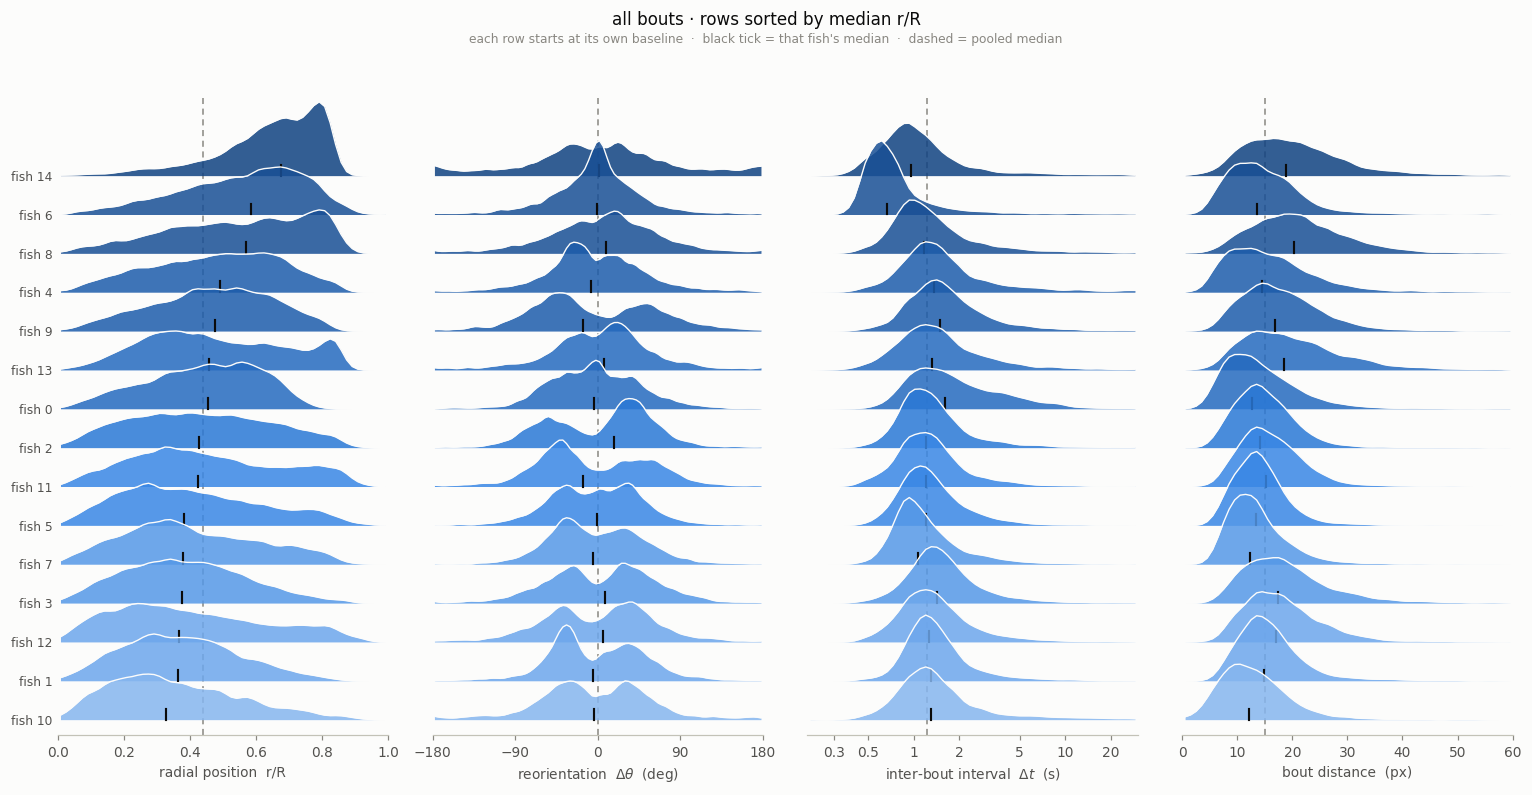

In [881]:
# Per fish distributions general
fig = plot_ridges(df, order_by="radial", title="all bouts · rows sorted by median r/R")
plt.show()

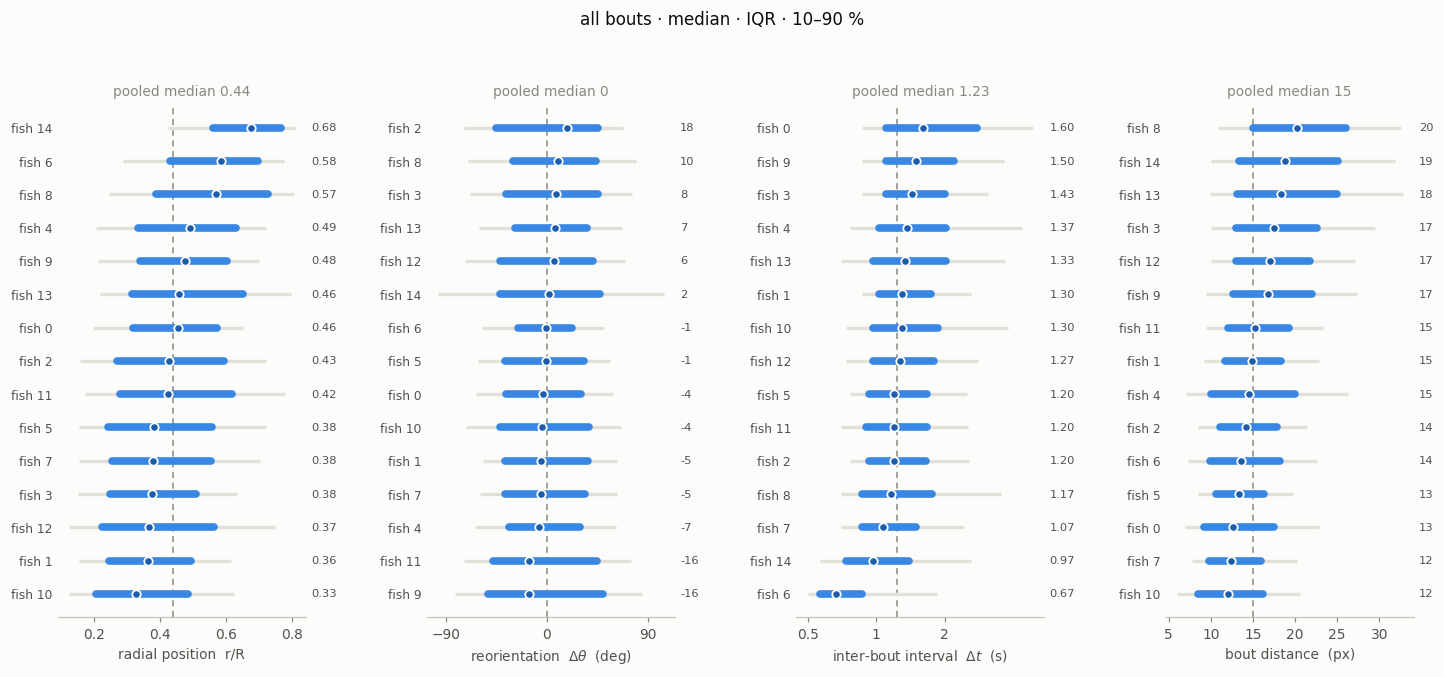

In [882]:
fig = plot_spread(df, title="all bouts · median · IQR · 10–90 %")
plt.show()

In [883]:
show(summary_table(df))

,n_bouts,radial_med,radial_iqr,radial_z,angular_med,angular_iqr,angular_z,dt_med,dt_iqr,dt_z,dist_med,dist_iqr,dist_z
fish,,,,,,,,,,,,,
0,4272,0.455,0.255,0.046,-3.865,67.052,-0.355,1.600,1.675,1.608,12.649,8.252,-1.097
1,5273,0.364,0.247,-0.896,-5.127,73.760,-0.490,1.300,0.700,0.276,14.866,6.680,-0.227
2,5526,0.427,0.326,-0.244,17.824,90.687,1.956,1.200,0.725,-0.168,14.142,6.843,-0.511
3,4816,0.376,0.262,-0.768,8.437,81.435,0.956,1.433,0.900,0.868,17.464,9.633,0.794
4,3258,0.492,0.297,0.425,-7.144,63.057,-0.705,1.367,1.000,0.572,14.560,10.025,-0.347
5,6686,0.381,0.313,-0.713,-0.538,70.174,-0.001,1.200,0.733,-0.168,13.416,5.649,-0.796
6,3137,0.585,0.268,1.387,-0.509,47.889,0.002,0.667,0.300,-2.535,13.601,8.349,-0.723
7,6378,0.380,0.301,-0.729,-5.194,71.113,-0.497,1.067,0.633,-0.759,12.369,6.151,-1.207
8,3199,0.570,0.340,1.228,9.512,73.784,1.070,1.167,0.900,-0.316,20.224,11.044,1.878


Facets for one channel at a time — this is where you go after the strip above flags a
fish. Change `key` to any of `radial` / `angular` / `dt` / `dist`.

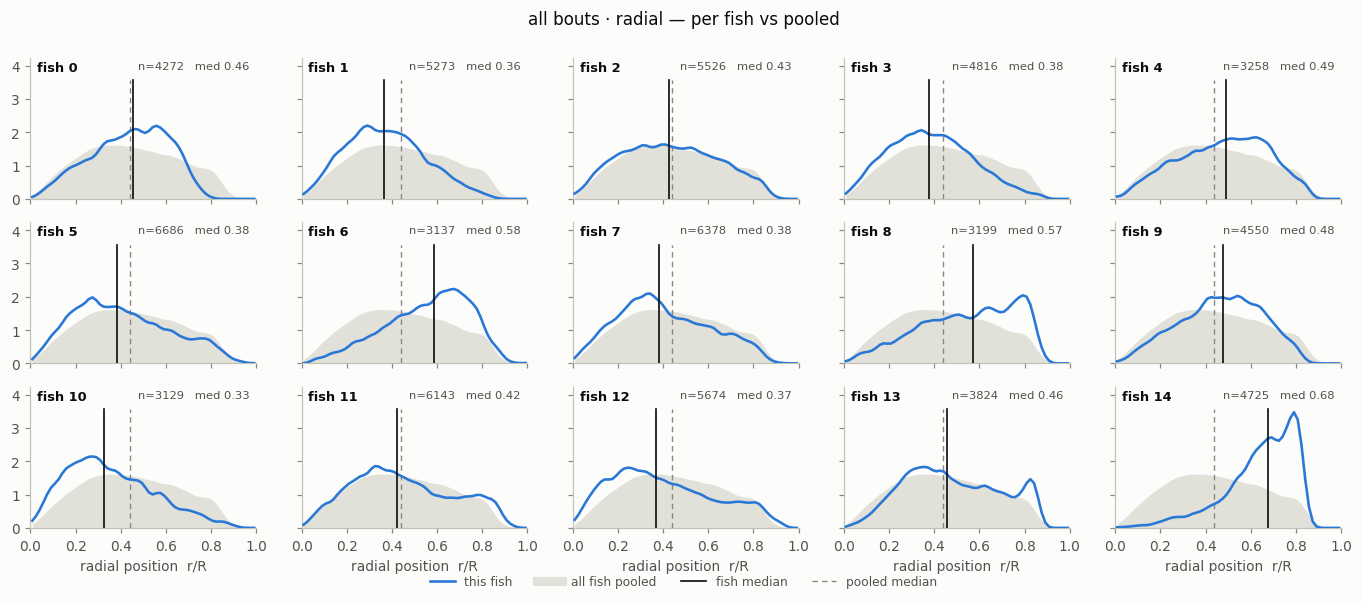

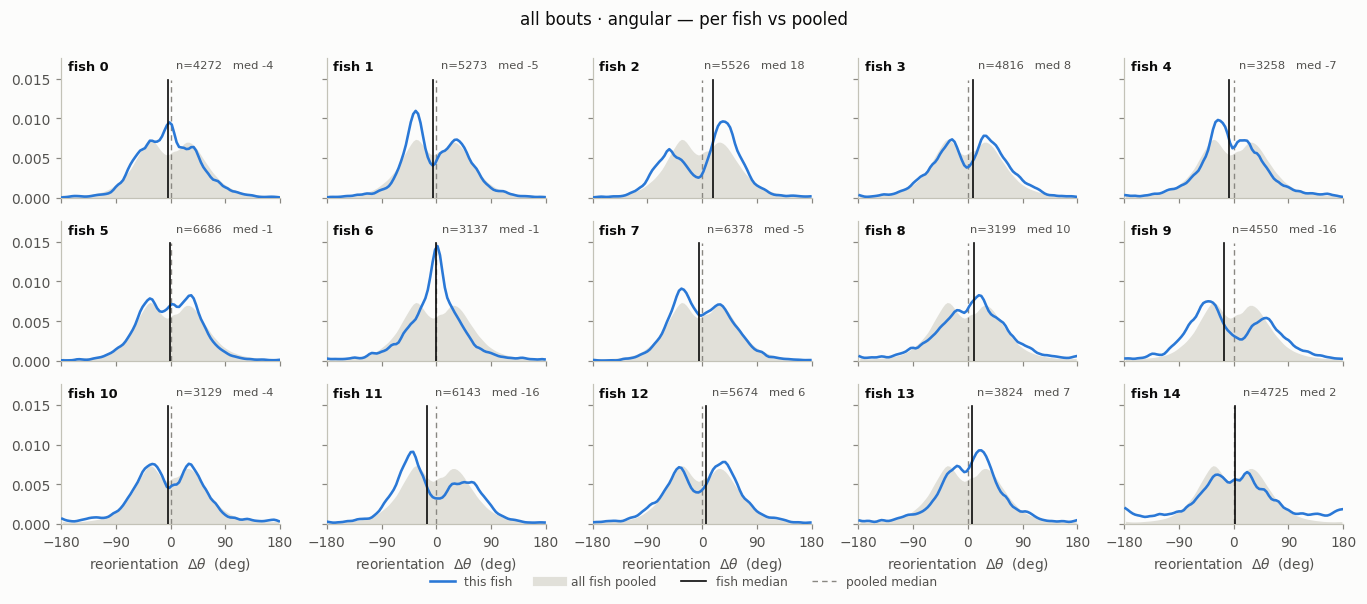

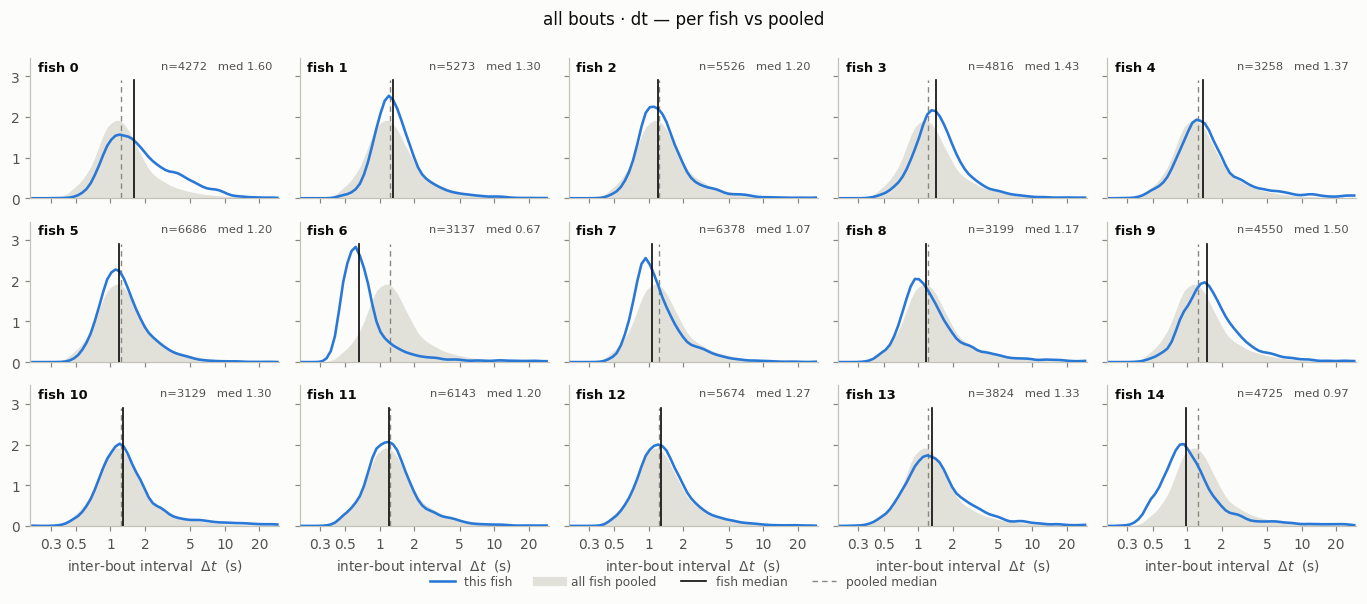

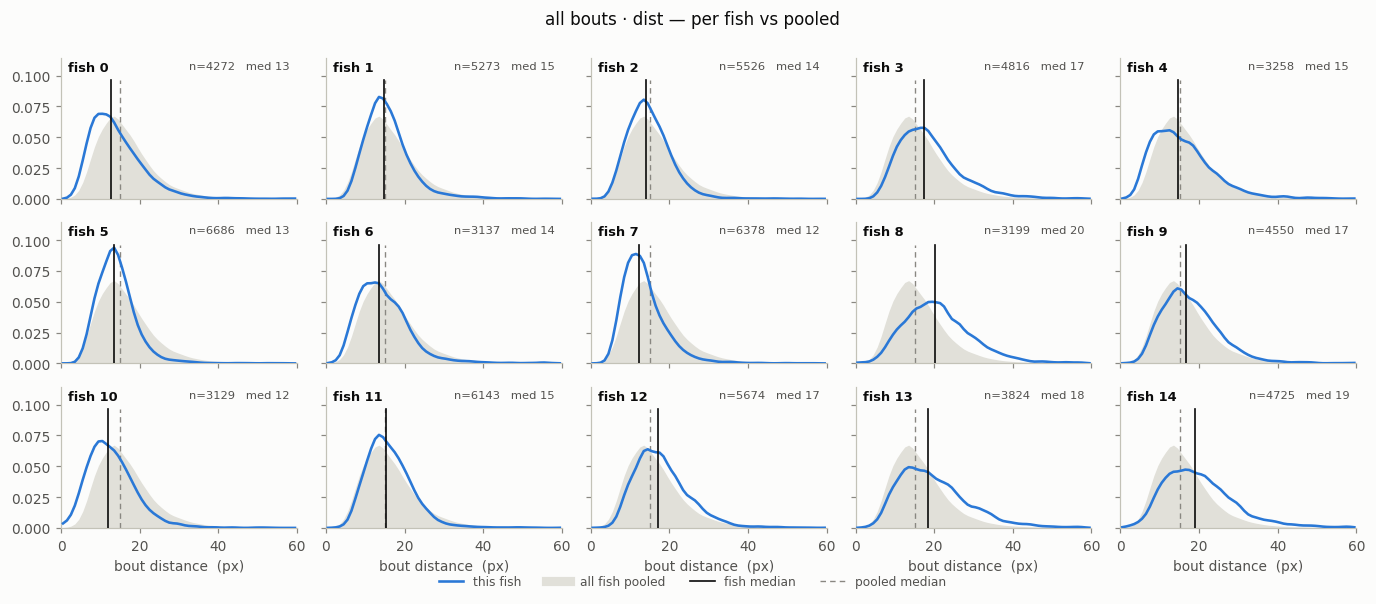

In [884]:
for key in KEYS:
    plot_per_fish(df, key, title=f"all bouts · {key} — per fish vs pooled")
    plt.show()

### 2 · No stimulus

`stimulus == "inter_stim_pause"` — the inter-block pauses. Note this is also where the
long `Δt` tail lives (block boundaries), so the fraction beyond the 30 s axis is
largest here; the printed tail fraction says how much.

no stimulus: 30,542 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.60% · dist 0.26%


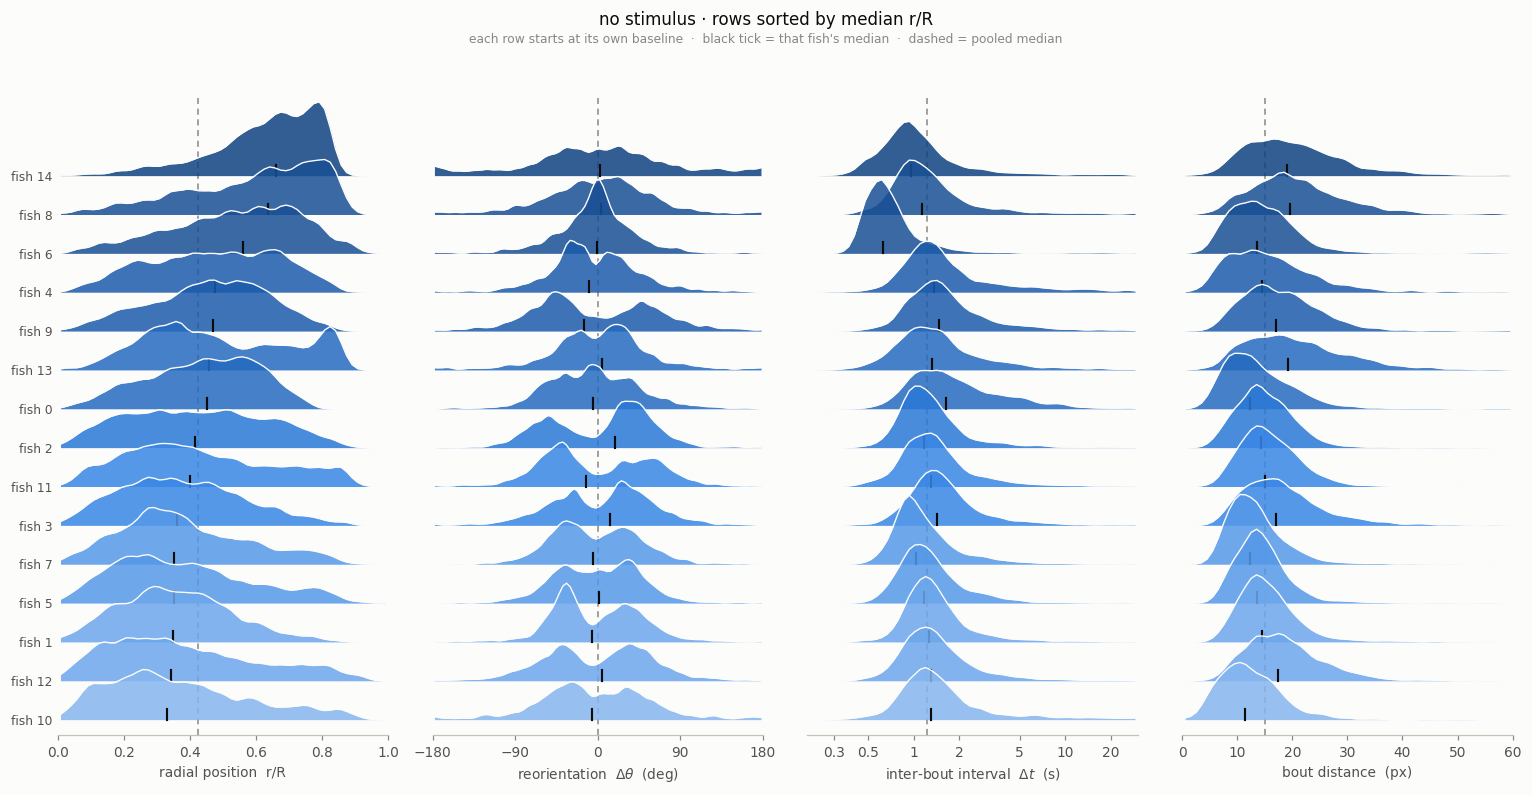

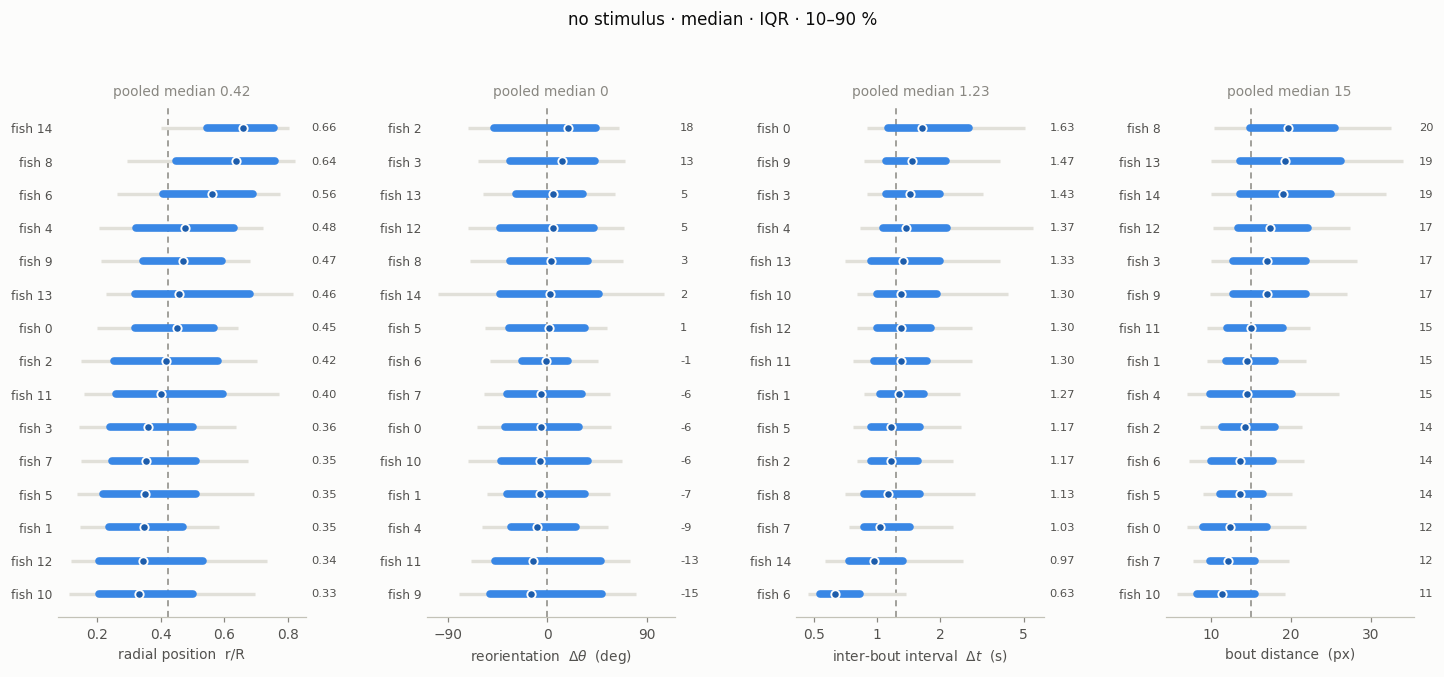

In [885]:
# No stim
d_none = df[df["cond"] == "none"]
head(d_none, "no stimulus")
plot_ridges(d_none, order_by="radial", title="no stimulus · rows sorted by median r/R")
plot_spread(d_none, title="no stimulus · median · IQR · 10–90 %")
plt.show()

### 3 · Moving stimulus

`moving == True` — a `CLsemi` block with non-zero dot speed on one side.

moving dots: 25,673 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.61% · dist 0.38%


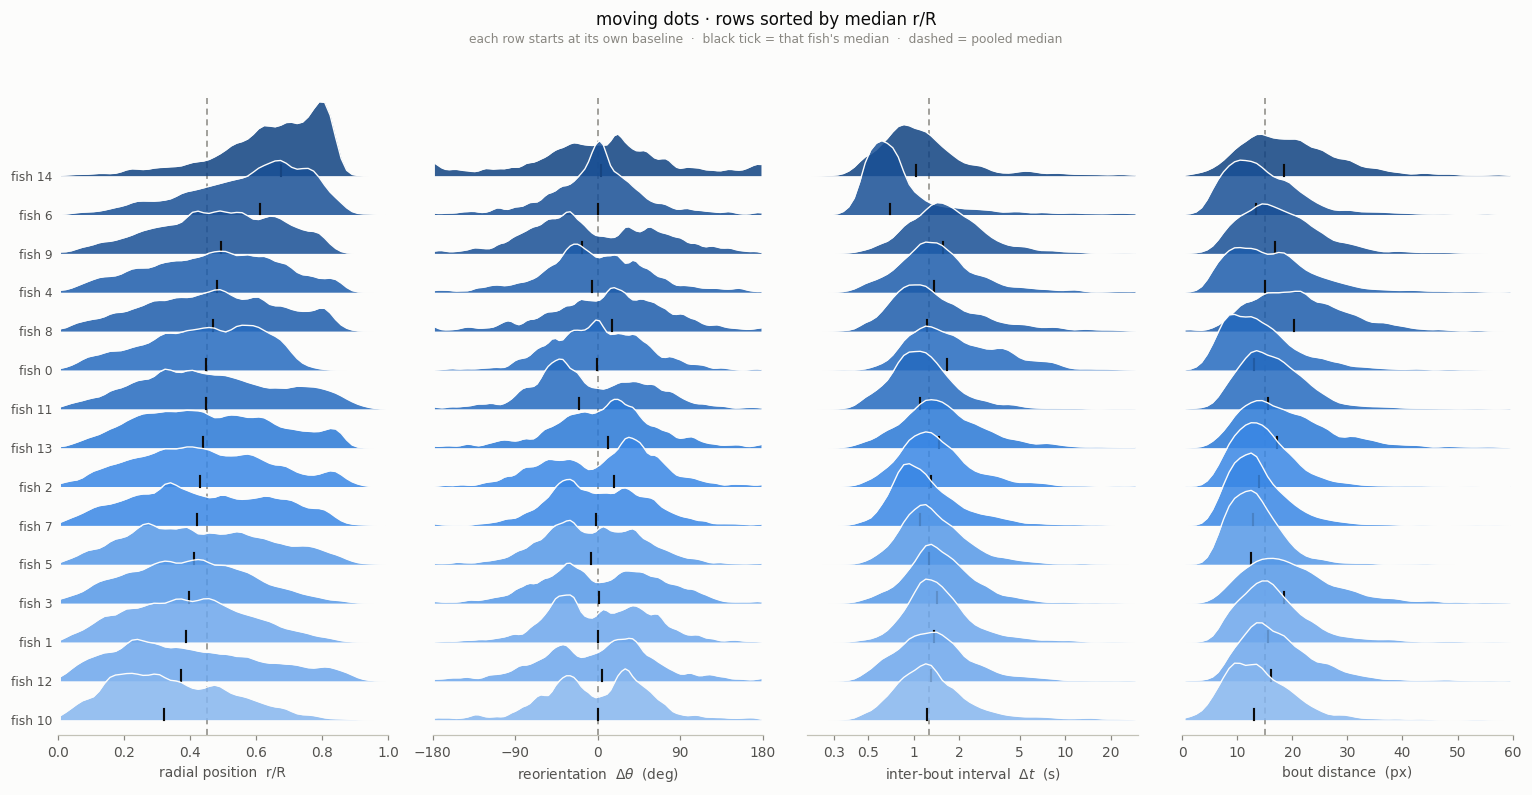

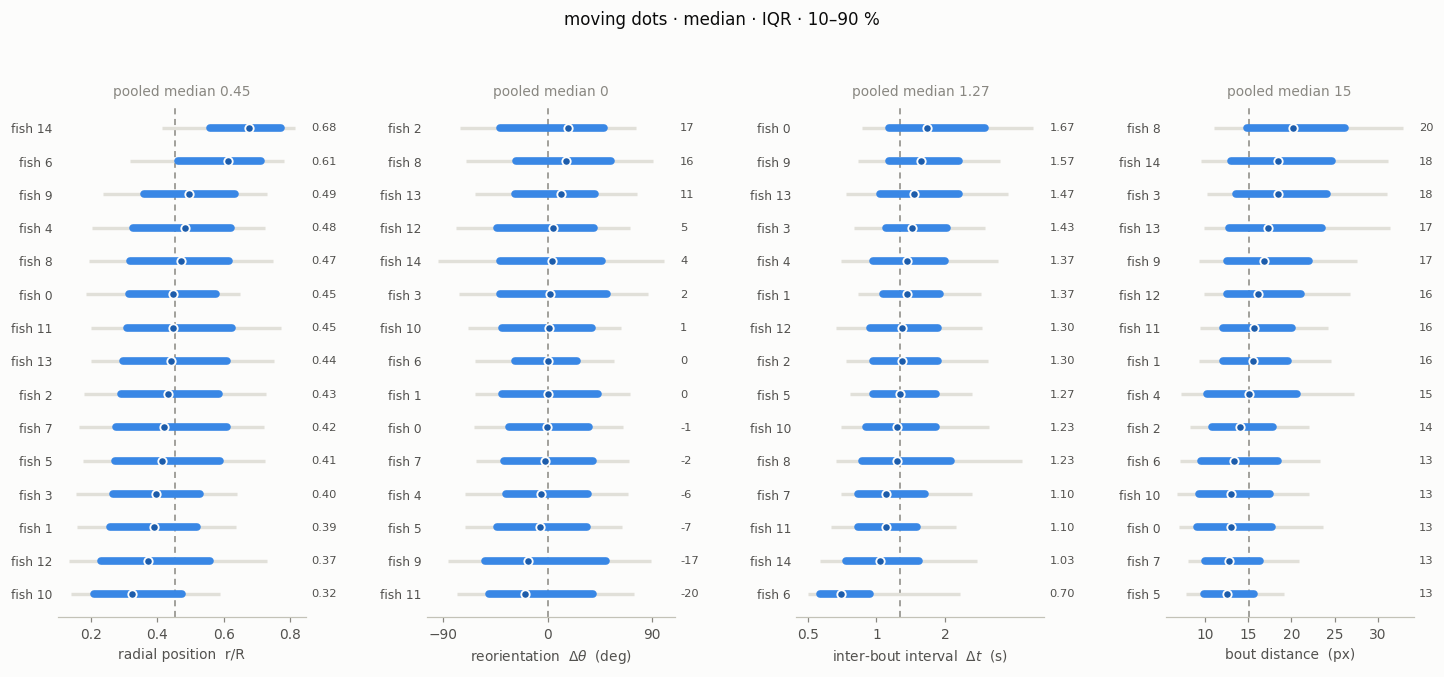

In [886]:
# Moving stim
d_move = df[df["cond"] == "moving"]
head(d_move, "moving dots")
plot_ridges(d_move, order_by="radial", title="moving dots · rows sorted by median r/R")
plot_spread(d_move, title="moving dots · median · IQR · 10–90 %")
plt.show()

### 4 · Static stimulus

A `CLsemi` block with `s0-0` — dots present, not moving.

static dots: 14,375 bouts · 15 fish · off-axis radial 0.00% · angular 0.00% · dt 0.74% · dist 0.27%


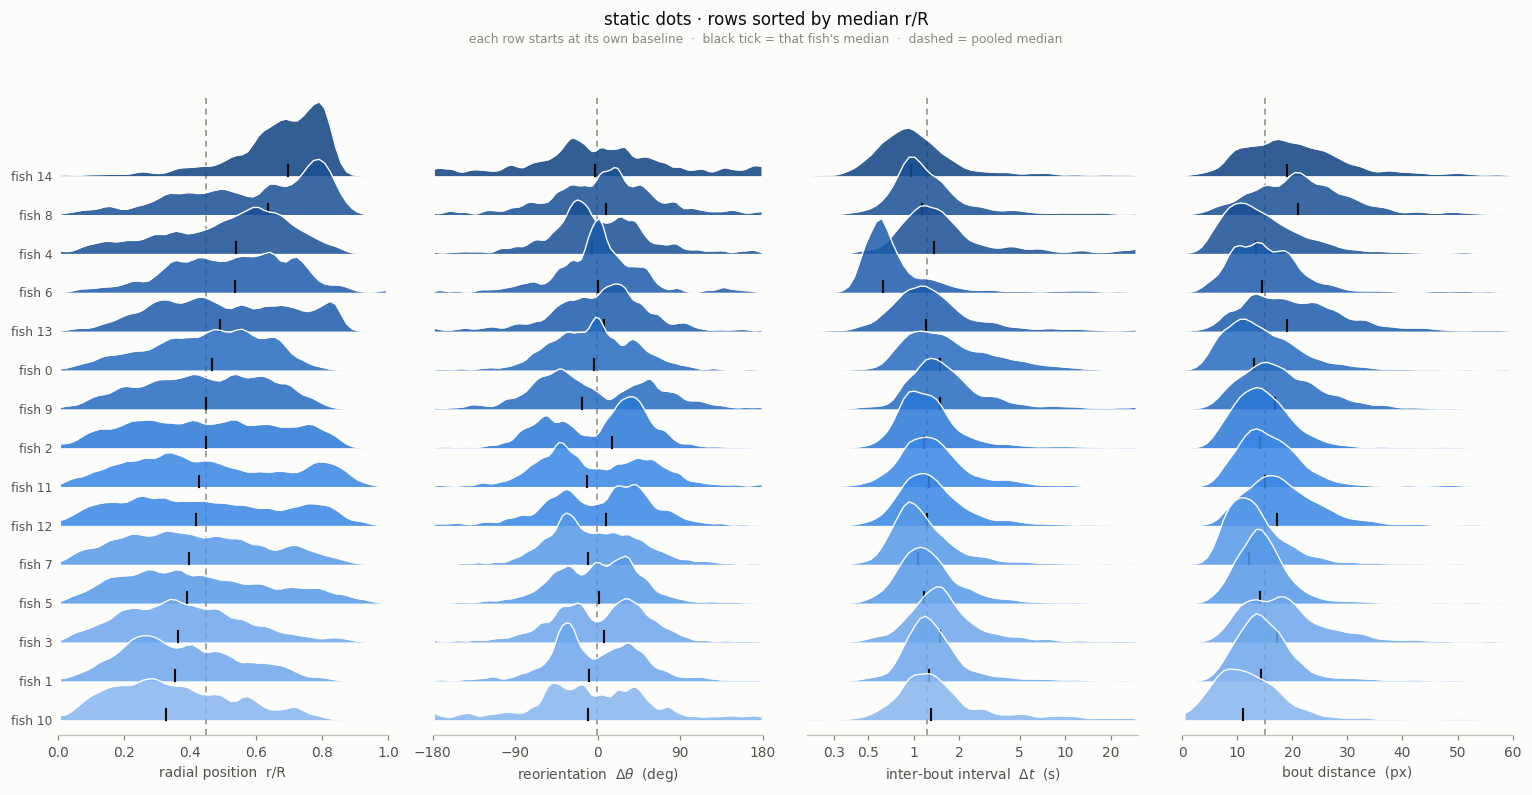

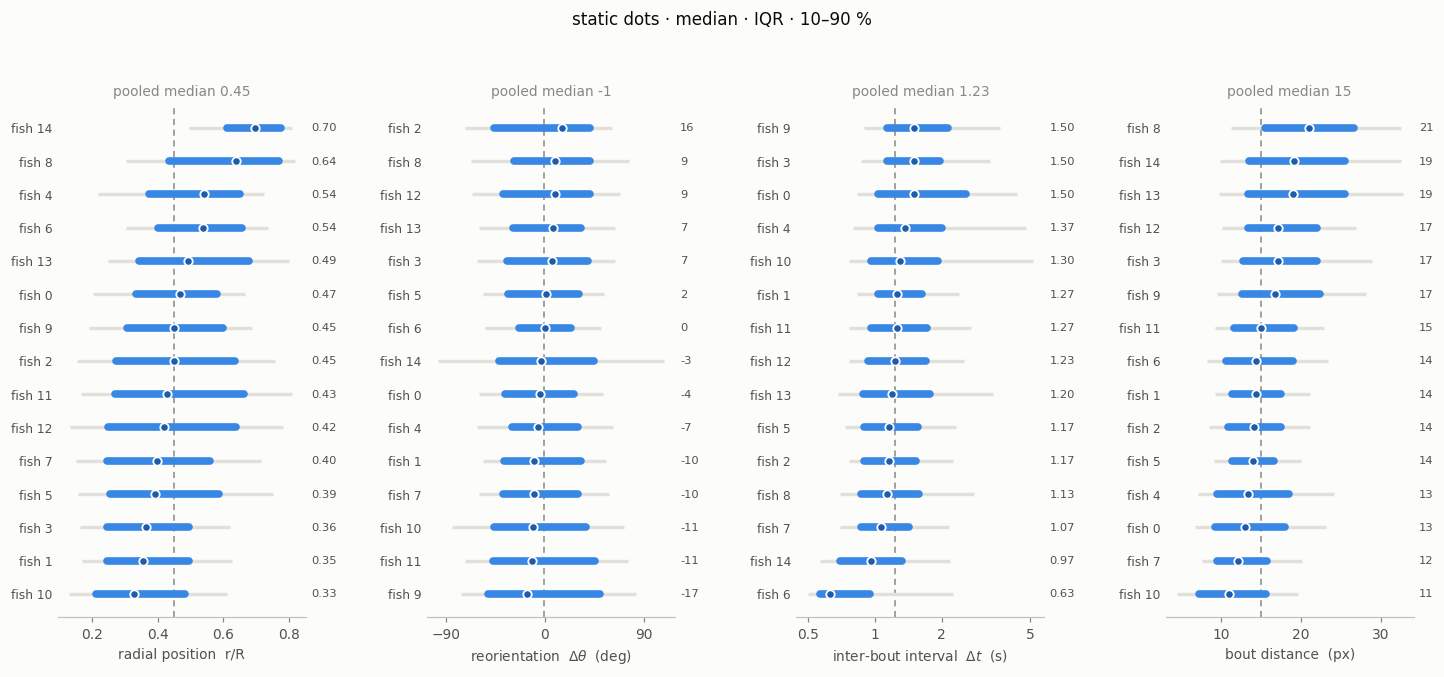

In [887]:
# Static stim
d_stat = df[df["cond"] == "static"]
head(d_stat, "static dots")
plot_ridges(d_stat, order_by="radial", title="static dots · rows sorted by median r/R")
plot_spread(d_stat, title="static dots · median · IQR · 10–90 %")
plt.show()

### 5 · The three conditions, inside each fish

Sections 2–4 compare fish within a condition; this compares conditions within a fish,
which is the paired version of the same question and the one that survives the fact
that the fish differ a lot from each other to begin with.

If a fish's three curves lie on top of one another, that fish is not responding to the
stimulus in that channel.

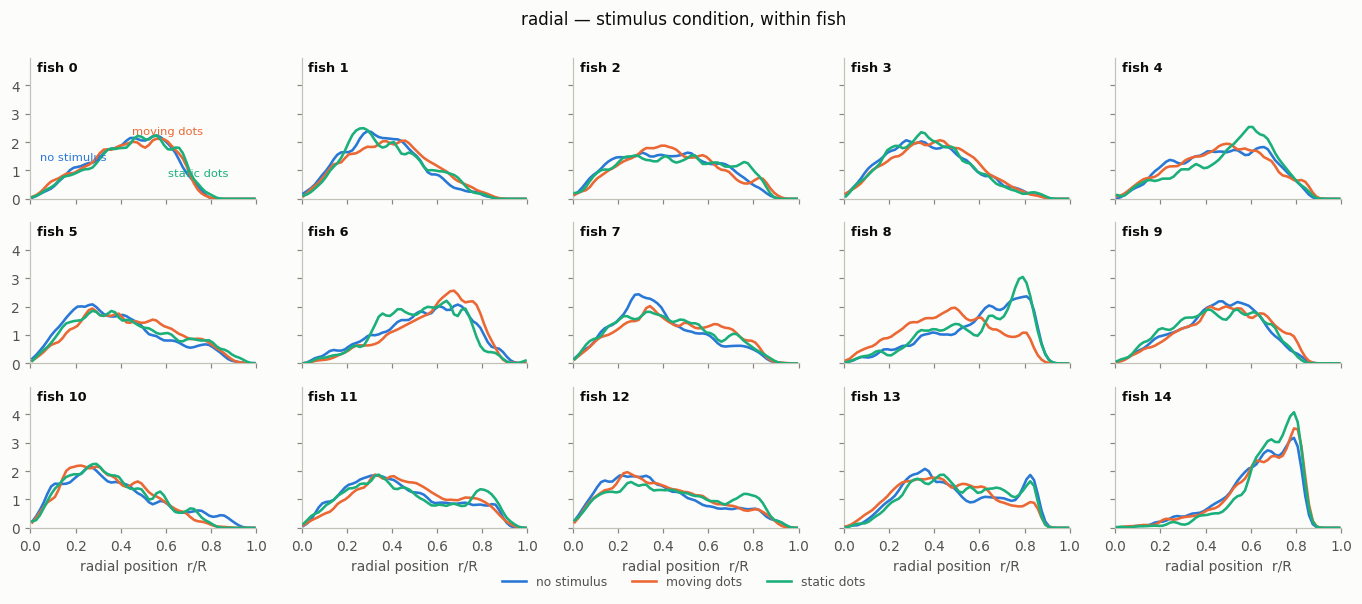

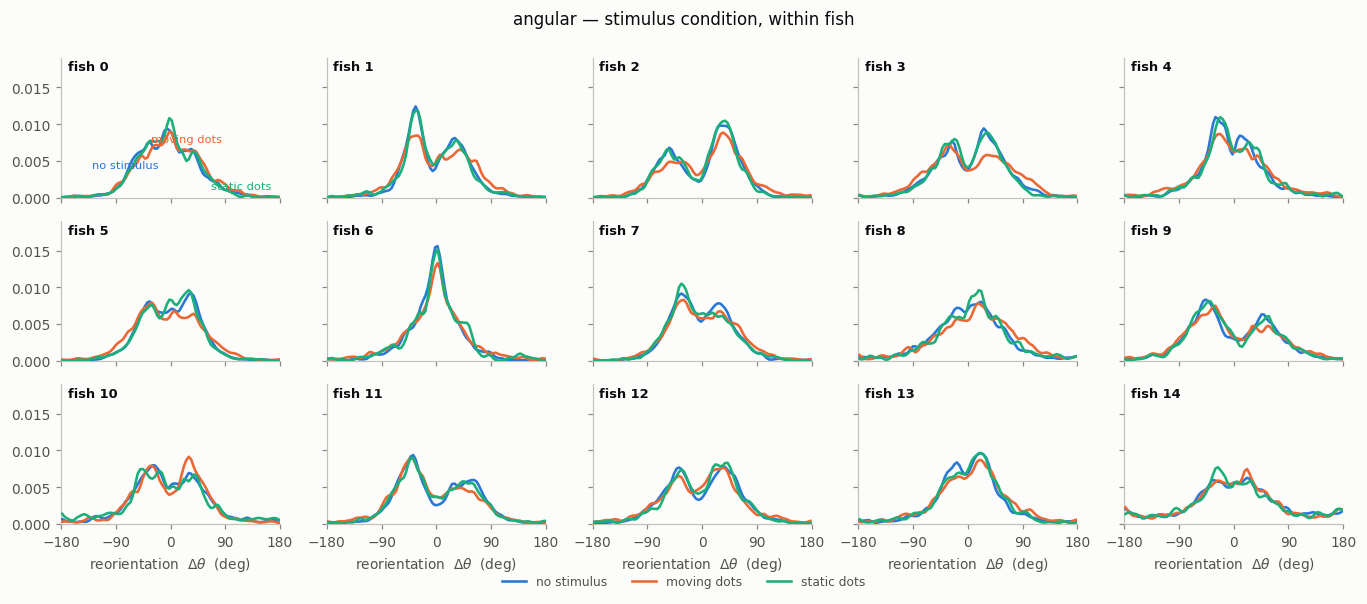

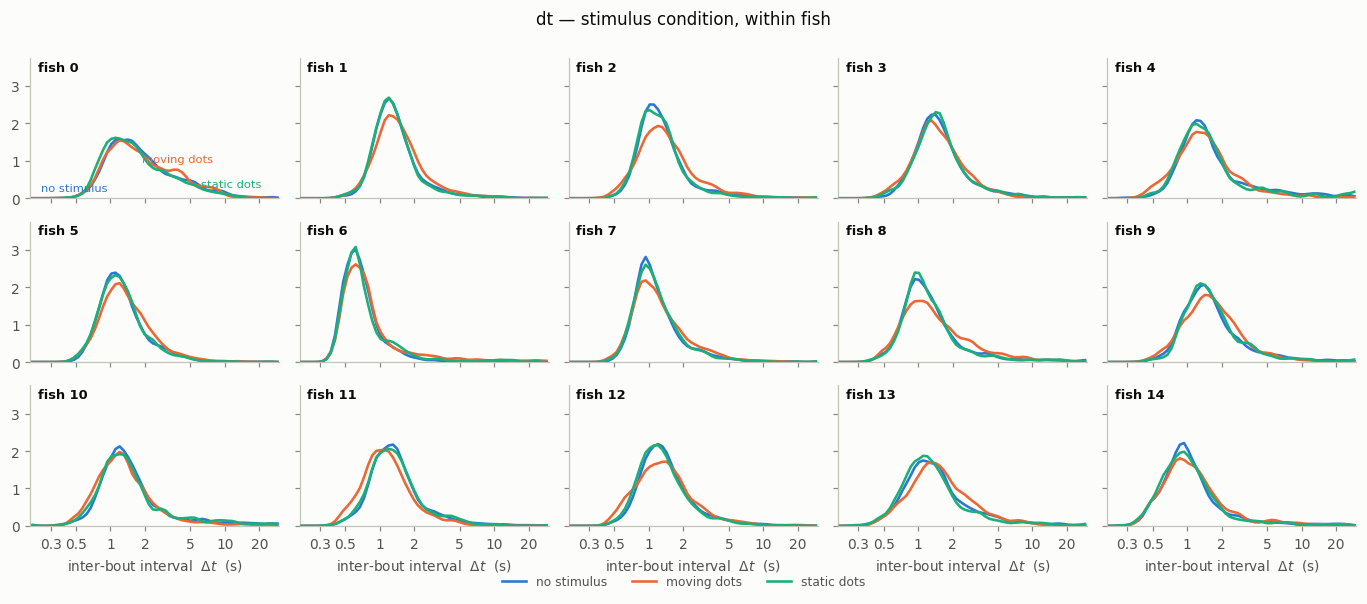

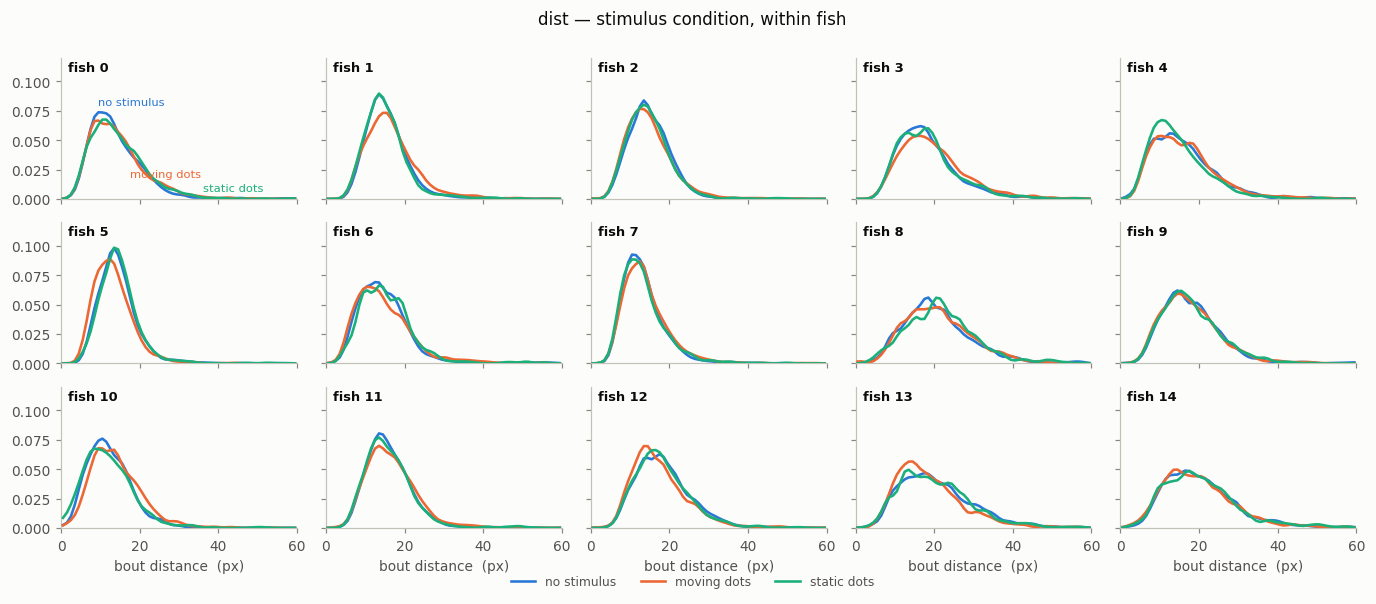

In [888]:
for key in KEYS:
    plot_conditions(df, key, title=f"{key} — stimulus condition, within fish")
    plt.show()

And the same contrast as numbers. Means and the turn fraction, **not** medians: `dt`
and `distance` are quantised by the camera, so their medians move by exactly one frame
(0.033 s) between conditions no matter what the fish did, and the median of a signed
near-symmetric `Δθ` is 0 in every condition by construction.

In [889]:
condition_table(df)

,no stimulus,moving dots,static dots,Δ vs none: moving dots,Δ vs none: static dots
r/R mean,0.438,0.456,0.459,0.018,0.022
|Δθ| mean (deg),44.486,48.264,44.326,3.778,-0.160
P(|Δθ|>10°),0.891,0.889,0.883,-0.003,-0.009
Δt mean (s),2.159,2.263,2.207,0.104,0.048
dist mean (px),16.411,16.660,16.522,0.249,0.111


Pooled across fish, the stimulus effect is small — but the fish differ from each other
by much more than the effect, so the pooled number is the wrong estimator. Below is the
paired version: each fish's condition summary **minus its own** no-stimulus value.
`std` across fish is the honest error bar on the row above.

In [890]:
cd = condition_deltas(df)
display(cd.groupby("vs no stimulus").agg(["mean", "std"]).round(3))

# diverging colour, so 0 must sit on the neutral midpoint -- background_gradient
# spans each column's own min..max, which would put the midpoint wherever the data
# happens to straddle. gmap scales every column to a symmetric [-1, 1] instead.
cd.style.format("{:+.3f}").background_gradient(
    cmap="RdBu_r", gmap=cd / cd.abs().max(), vmin=-1, vmax=1, axis=None)

r/R mean        |Δθ| mean (deg)        P(|Δθ|>10°)         \
                   mean    std            mean    std        mean    std   
vs no stimulus                                                             
moving dots       0.009  0.044           3.900  3.182       0.003  0.020   
static dots       0.018  0.023           0.057  2.190      -0.008  0.011   

               Δt mean (s)        dist mean (px)         
                      mean    std           mean    std  
vs no stimulus                                           
moving dots          0.064  0.603          0.216  1.054  
static dots          0.132  0.501          0.061  0.741

### 6 · Response to the stimulus

§2–§5 ask whether behaviour *changes* when dots are on screen. This section asks whether
the behaviour is **directed at the dots**, in the two ways that can be measured per fish.

#### A · Does the fish close distance on the dots?

x is the clock inside one stimulus block (0 = the dots just appeared, blocks run 60 s);
y is `dot_dist_px`, the distance from the fish to the centroid of the active dots.

Each fish sees ~58 moving and ~33 static blocks and **no two blocks give the same curve**,
so each is one replicate: within a block we take the mean distance per 2 s bin, then
average those block means and band them with a **t-based 95 % CI across blocks**. Bouts
inside one block share a starting position and a dot trajectory, so treating them as
independent draws would shrink every band by roughly √30 and turn noise into a finding.

Two things to read with care:

⚠ **The moving curve is relative geometry.** For static dots the centroid does not move,
so a change in distance is entirely the fish. For moving dots the centroid moves too, so
the fish closing in and the dots sweeping past are not separable in this one number.

⚠ **A bin only sees blocks in which the fish bouted.** Distance is sampled at bouts, so a
fish that goes quiet contributes nothing to the later bins, and the curve is conditioned on
it still being active. A curve that stops early means fewer than 8 blocks still had a bout
that late — most visible for **fish 6**, whose static curve gives out early. That is a real
fact about the fish, but it is a fact about *when it moves*, not about where it is. §6A′
below takes that case apart.

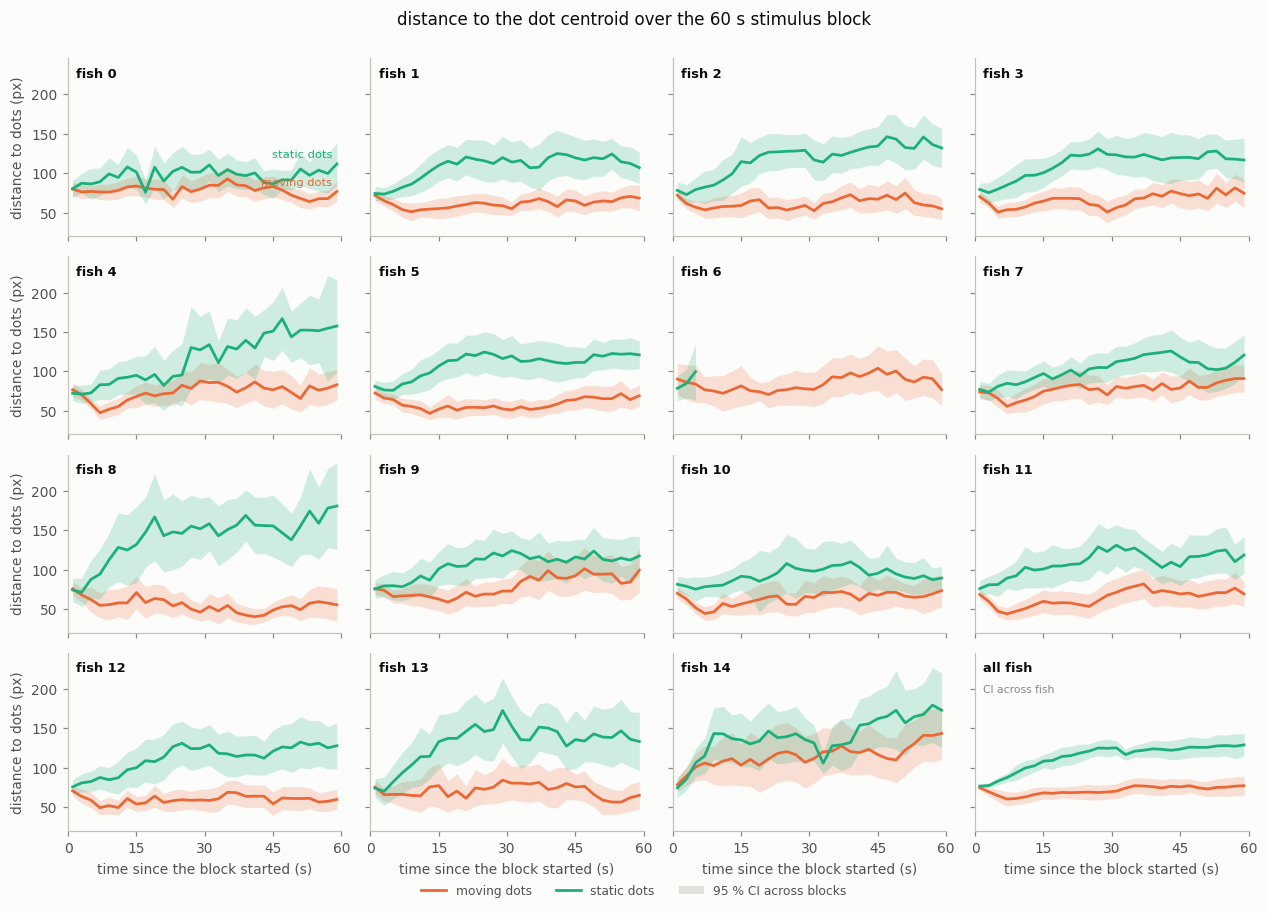

In [891]:
# Distance to the stimulus centroid over the block, per fish, moving vs static
plot_approach(df)
plt.show()

#### A′ · Why a curve stops early — the raw speed trace

**Fish 6's static curve gives out early.** A curve stops when fewer than 8 blocks still
have a bout in the bin, and that has two very different possible causes: the **fish**
stopped swimming, or the **detector** stopped accepting its bouts. The plot below is
section 5 of `segment_bouts.ipynb` — raw speed with the detected bouts on top — pointed
at the blocks in question, which tells the two apart at a glance.

Detection is re-run exactly as `scripts/segment_bouts.py` ran it: over the **whole
continuous recording**, so the threshold is `mean(v) + 1·SD` across all 174 minutes, not
across the block. Re-deriving it per block would invent a different threshold and draw
bouts the shipped CSV does not contain. It reproduces all 3137 shipped bouts for fish 6
frame for frame. Peaks that cleared the threshold but failed the displacement gate are
drawn separately as red ×, because a trace full of those would mean the detector, not the
fish. *(Reads one ~115 MB per-frame CSV — a few seconds.)*

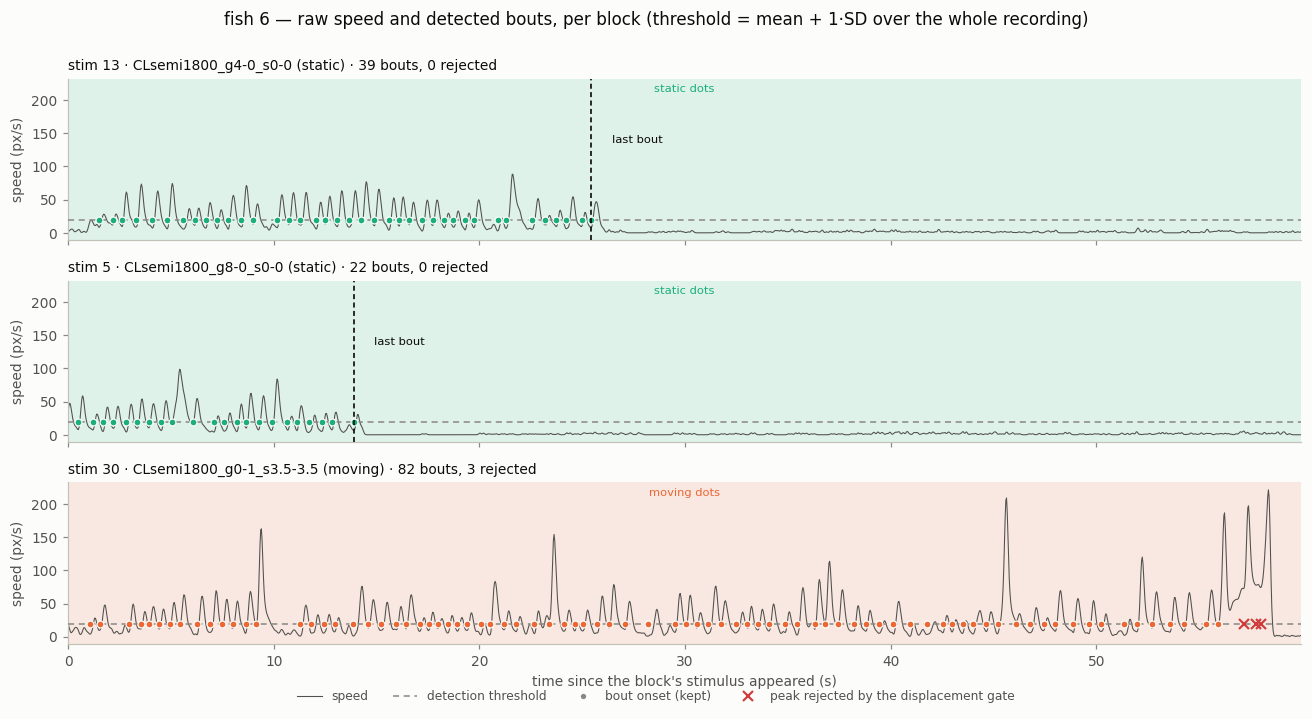

In [892]:
# Two static blocks where fish 6 goes quiet, and its busiest moving block for contrast
quiet = pick_blocks(df, 6, "static", n=2, min_bouts=15, last_before=30)
busy = pick_blocks(df, 6, "moving", n=1, min_bouts=15)
plot_bout_trace(6, quiet + busy)
plt.show()

In [893]:
block_activity(df, 6, quiet + busy)

window_s  mean_speed  max_speed  frac_over_thr
block   window                                                          
stim 13 before last bout      25.4       23.50      88.47         0.4450
        after                 34.5        1.82      46.77         0.0097
stim 5  before last bout      13.9       24.06      98.81         0.4689
        after                 46.0        1.36      30.73         0.0036
stim 30 before last bout      55.9       24.24     209.17         0.4386
        after                  4.0       62.86     221.43         0.6475

#### B · Does the fish turn toward the dots?

One bar per fish per condition:

```
P(turn toward) = P( sign(Δθ) == sign(φ) )      over turn bouts, |Δθ| > 10°
```

where `φ` is the egocentric bearing to the dot centroid. **0.5 is chance** — a fish that
turns without regard to where the dots are. Forward bouts are excluded because a forward
bout has no direction to be "toward" anything. Whiskers are the 95 % CI across blocks,
the same replicate unit as panel A.

Bars are anchored on the 0.5 chance line rather than on zero, because 0.5 — not 0 — is
what "no response" scores, so bar length reads as the departure from chance.

**Sign convention, checked rather than assumed.** `stim_angle_rad` and `dtheta_deg` are
both CCW-positive in the same frame (`segment_bouts.stim_angle_at` and the
`theta_i − theta_{i-1}` reorientation), so positive means *the fish's left* for both and
`sign(Δθ) == sign(φ)` is literally "turned toward". Note `evaluate.symbols_from_dtheta`
names `Δθ < −10` "Left" — the opposite naming; nothing here uses it.

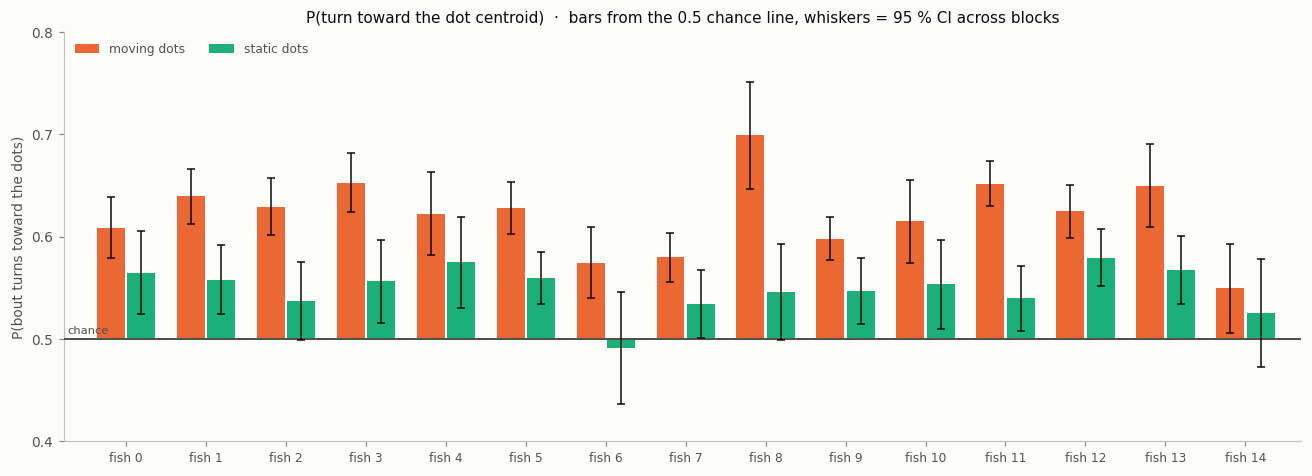

In [894]:
# P(bout turns toward the dot centroid), per fish, moving vs static
plot_toward_bars(df)
plt.show()

In [895]:
toward_table(df)

,moving dots,moving dots 95% CI,moving dots n blocks,static dots,static dots 95% CI,static dots n blocks,moving − static
fish,,,,,,,
0,0.609,"[0.579, 0.639]",60,0.565,"[0.524, 0.605]",35,0.044
1,0.639,"[0.613, 0.666]",58,0.558,"[0.524, 0.592]",32,0.081
2,0.629,"[0.601, 0.657]",58,0.537,"[0.499, 0.575]",32,0.092
3,0.653,"[0.624, 0.681]",59,0.556,"[0.516, 0.597]",34,0.096
4,0.622,"[0.582, 0.663]",52,0.575,"[0.530, 0.619]",26,0.048
5,0.628,"[0.602, 0.654]",60,0.560,"[0.534, 0.585]",35,0.068
6,0.575,"[0.540, 0.609]",47,0.491,"[0.436, 0.546]",15,0.083
7,0.580,"[0.556, 0.604]",58,0.534,"[0.501, 0.567]",32,0.046
8,0.699,"[0.647, 0.751]",45,0.546,"[0.499, 0.593]",23,0.153


### 7 · Watch it — is fish 6 actually all right?

§6A′ says the speed trace flatlines and the detector rejects nothing, which means the
fish stopped swimming. It does **not** rule out the boring explanations: a fish wedged
against the wall, or tracking that froze on a stale coordinate.

So watch the two blocks at **real speed, 30 fps**. Top row is the dish with the static
dots and the fish as a heading arrow trailing 2 s of path; bottom row is that block's
speed trace with a cursor, so the picture and the number never drift apart. Bout onsets
and the trace are the same verified reproduction of `scripts/segment_bouts.py` used above.

Writes `mp4_fish_6check.mp4` to the repo root (~60 s of video, a couple of minutes to
render). No system `ffmpeg` is needed — it falls back to the binary bundled in the
`imageio-ffmpeg` wheel, the same fallback `bout_video.py` uses.

**Naming a block.** Every function here takes the same label the tables print —
`"stim 13"`, `"pause 76"` — so you can paste one straight out of `worst_gaps`. A bare
integer is also accepted, but it is the *internal grid id*, which counts pause and
stimulus blocks together: `"stim 9"` is grid id **19**, and grid id 9 is a different
block (`"stim 4"`). Use the labels and the question does not arise.

In [896]:
# The two static blocks from §6A' where fish 6 goes quiet.
# Real time: fps=FPS (30). Pass e.g. fps=60 to watch it at 2x, max_frames=... to preview.
# make_block_video(6, ["stim 13", "stim 5"], ROOT / "mp4_fish_6check.mp4")

# To watch it inline instead of in a player:
#   from IPython.display import Video; Video("../mp4_fish_6check.mp4", width=900)

The same for **fish 8** (54 % of its session quiet). These five are picked the way §6A′
picks them — blocks with at least 12 bouts whose last bout falls before 45 s — so each one
shows the fish swimming *and then stopping*, rather than being silent throughout. Its five
single worst gaps (`stim 9`, `40`, `23`, `13`, `43`) are mostly whole-block silence, which
is less to look at; pass them instead if you want those.

As **still traces, not video** — seconds instead of minutes, and it is the speed trace you
actually read the answer off. `extend_s=120` carries each row two minutes past its block,
so a row spans roughly three periods: the block itself, the 50 s pause, and the next
stimulus block. Every period is tinted and named (moving dots / static dots / pause), with
a rule at each boundary, so you can see straight away whether a stop ends when the
stimulus changes. §9 says it usually does not.

`make_block_video(8, fish8, ..., extend_s=120)` renders the same windows as an mp4 if you
want to watch one.

['stim 34', 'stim 60', 'stim 39', 'stim 21', 'stim 53']


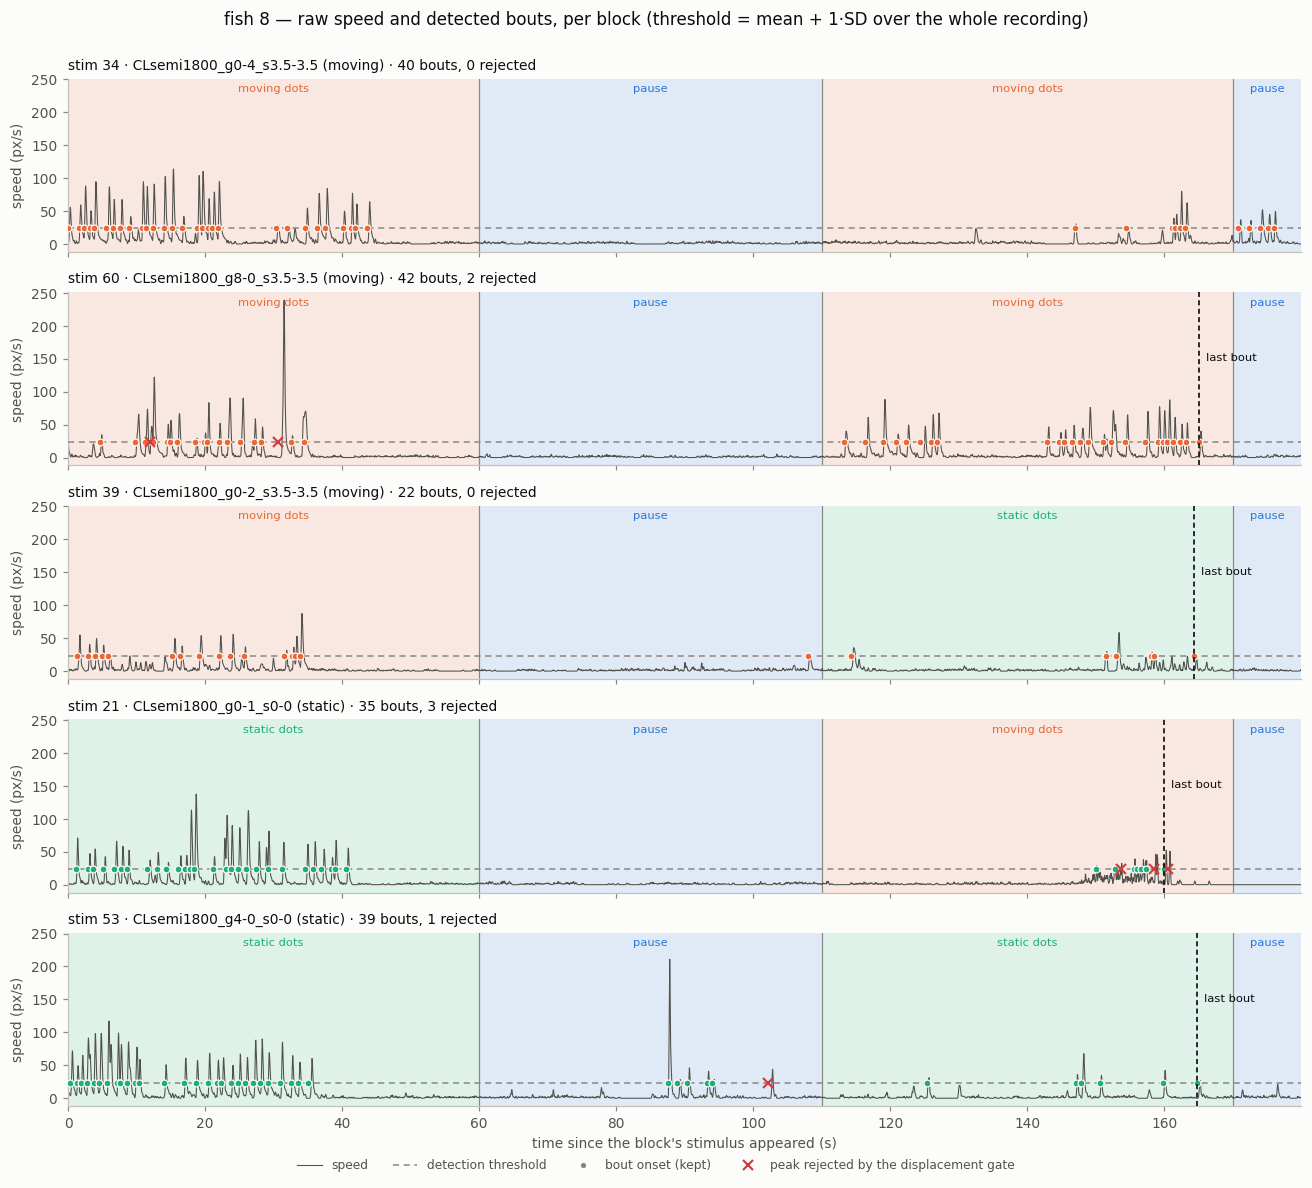

In [897]:
fish8 = pick_blocks(df, 8, "moving", n=3, min_bouts=12, last_before=45) \
      + pick_blocks(df, 8, "static", n=2, min_bouts=12, last_before=45)
print(fish8)
plot_bout_trace(8, fish8, extend_s=120)
plt.show()

And the other §9 shape — blocks where the fish stops **in the middle** and then starts
again. `pick_pause_blocks` takes the blocks with the longest internal pause that still has
at least 3 bouts after it, so the restart is actually on screen. A short extension here,
just enough to show what the fish does once this block ends.

['stim 23', 'stim 50', 'stim 7']


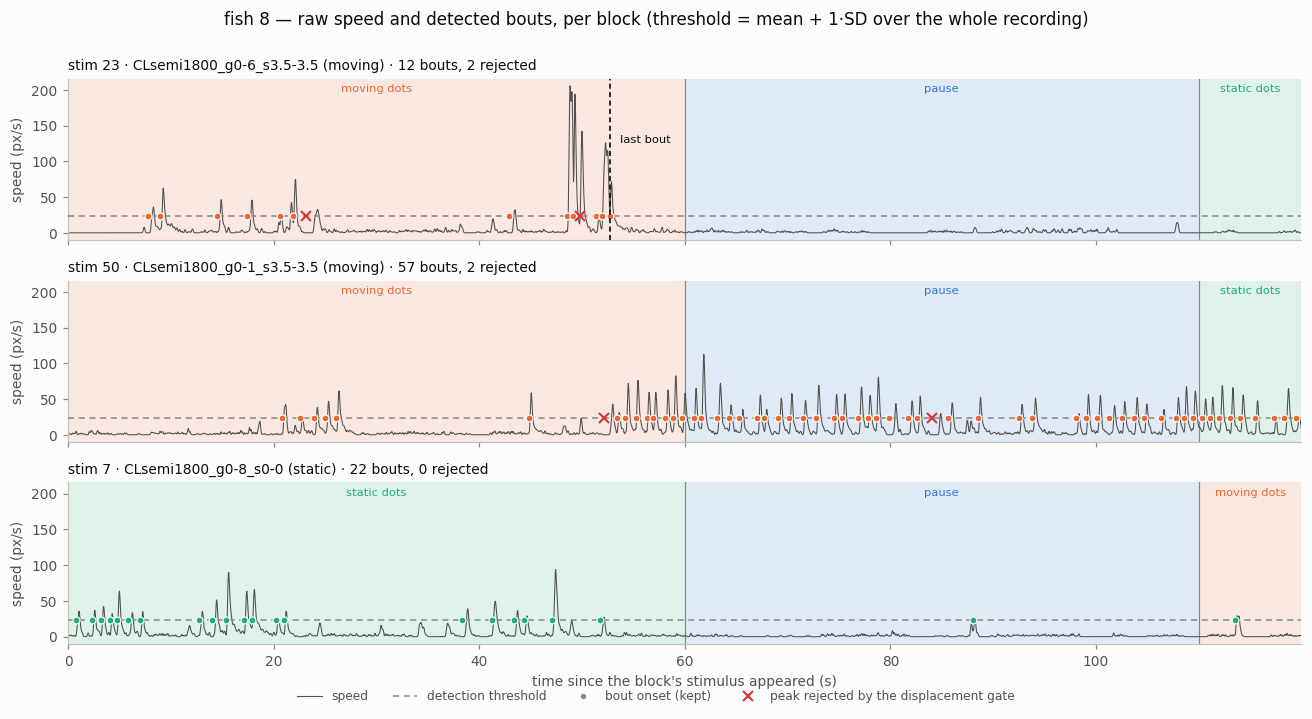

In [898]:
fish8_mid = pick_pause_blocks(df, 8, n=3, min_bouts=12, min_pause=10, min_after=3)
print(fish8_mid)
plot_bout_trace(8, fish8_mid, extend_s=60)
plt.show()

### 8 · Who else stops, and when

Fish 6 is not a special case, so this sweeps **every fish and every block** for stretches
longer than 10 s with no bout. A gap is simply a bout whose `dt_s` exceeds the threshold
— the same column the rest of the notebook uses, so this cannot disagree with it. Gaps are
not cut at block boundaries: a fish that stops mid-block and resumes two blocks later is
one gap, reported against the block it **started** in, since that is the block whose curve
it damages.

The raster is the answer to "which fish, and when": one row per fish, worst at the top,
one bar per stretch drawn at its real place and width in session time.

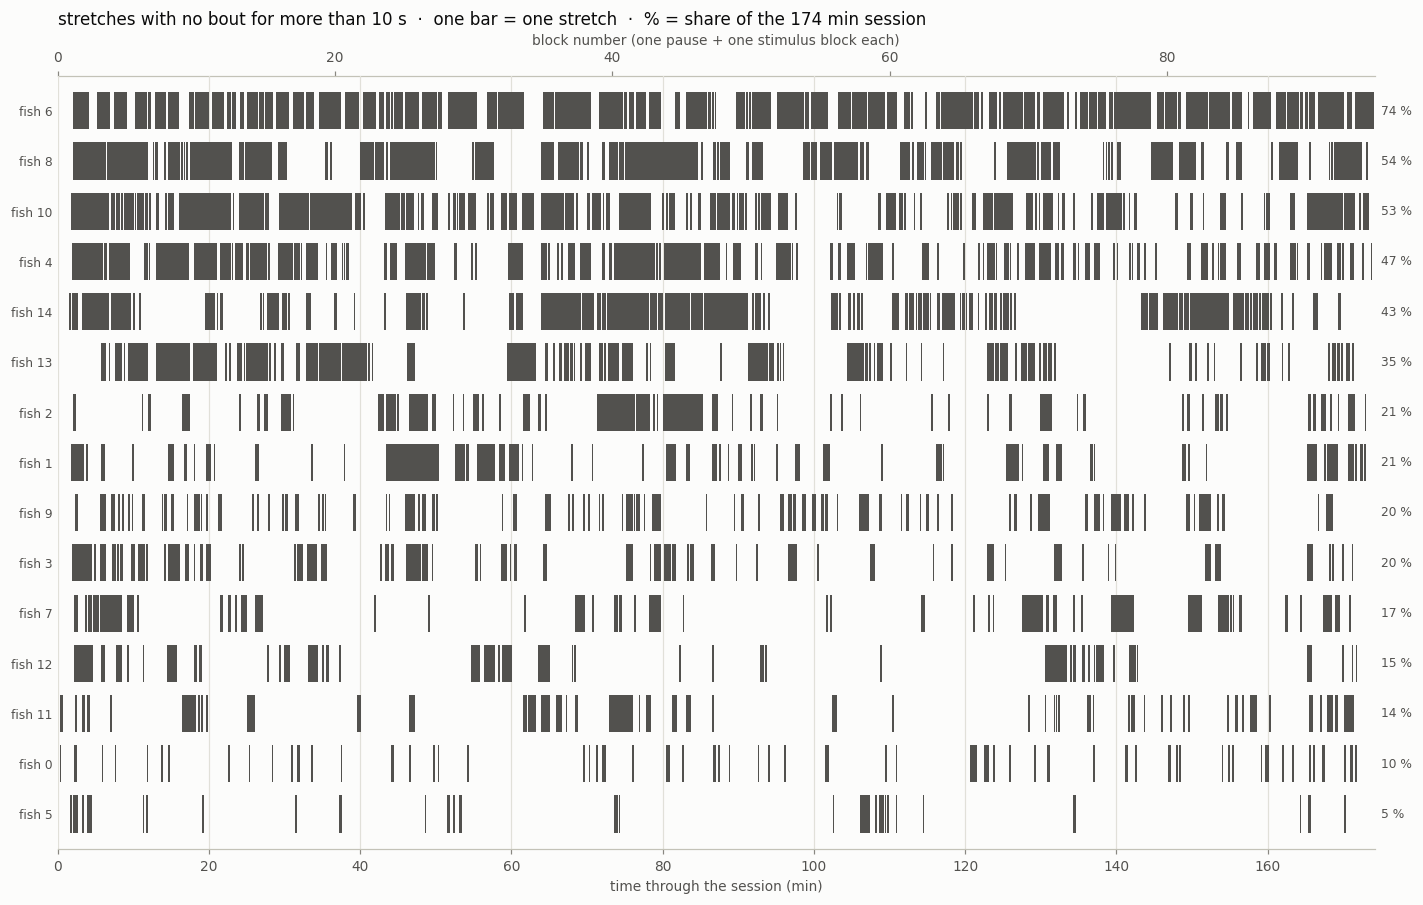

,bouts,n_gaps,quiet_min,pct_of_session,longest_s,longest_in
fish,,,,,,
6,3137,138,129.4,74.3,294.0,pause 76
8,3199,108,93.2,53.5,334.0,stim 9
10,3129,143,91.6,52.6,303.0,stim 0
4,3258,143,82.2,47.2,250.0,pause 7
14,4725,135,74.7,42.9,320.0,stim 34
13,3824,102,60.7,34.9,234.0,pause 32
2,5526,61,37.2,21.4,288.0,stim 43
1,5273,62,36.5,21.0,426.0,stim 23
9,4550,98,35.1,20.1,88.0,stim 70


In [899]:
# Every no-bout stretch > 10 s, all fish, all blocks
plot_quiescence(df, min_s=10)
plt.show()
quiescence_summary(df, min_s=10)

The same thing as one number per fish — the share of the session spent **active**, i.e. not
inside a no-bout stretch. It is the complement of the raster's right-hand column.

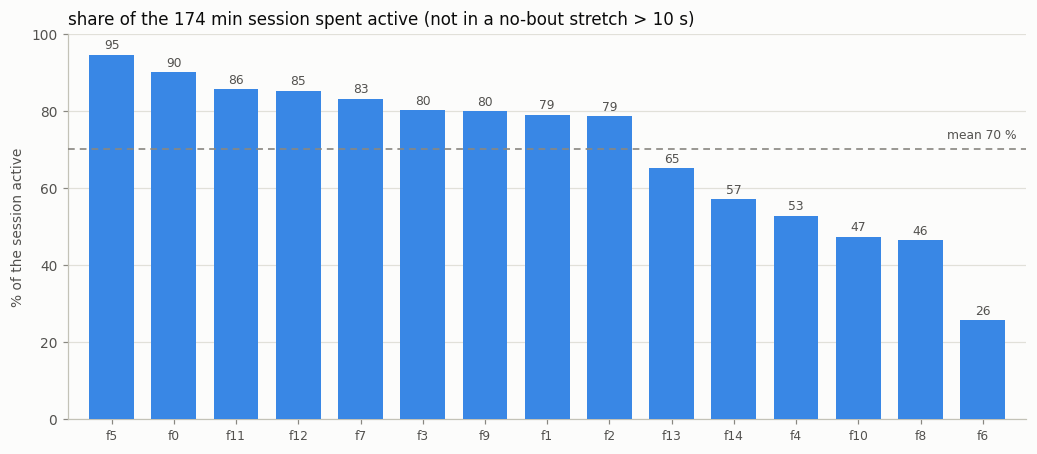

In [900]:
plot_active_share(df, thr=10)
plt.show()

#### What it costs to drop those blocks

A block counts as hit when **any** part of it falls inside a no-bout stretch — gaps are
intersected with every block they run through, not charged only to the one they start in,
because a fish that goes quiet in one block and wakes two blocks later has ruined all
three. Percentages are of that fish's blocks of that condition (95 pause, 60 moving, 35
static); the last column is the share of its **bouts** that go with them.

`min_cover` relaxes it: `0.0` is "any overlap at all" (the strict reading), `0.5` keeps a
block unless more than half of it is silent — worth comparing, the two differ by ~2×.

In [901]:
loss = block_loss(df, min_s=10, min_cover=0.0)
print(f"any overlap  : {loss.loc['ALL', 'all blocks']:.1f} % of blocks, "
      f"{loss.loc['ALL', 'bouts lost']:.1f} % of bouts")
print(f"> 50 % of the block: "
      f"{block_loss(df, min_s=10, min_cover=0.5).loc['ALL', 'all blocks']:.1f} % of blocks, "
      f"{block_loss(df, min_s=10, min_cover=0.5).loc['ALL', 'bouts lost']:.1f} % of bouts")
loss

any overlap  : 52.8 % of blocks, 30.6 % of bouts
> 50 % of the block: 28.4 % of blocks, 6.8 % of bouts


,none,moving,static,all blocks,bouts lost
fish,,,,,
0,41.1,41.7,42.9,41.6,36.6
1,43.2,36.7,48.6,42.1,25.3
2,41.1,43.3,45.7,42.6,25.2
3,44.2,38.3,48.6,43.2,28.3
4,82.1,75.0,82.9,80.0,60.6
5,16.8,21.7,14.3,17.9,11.0
6,92.6,96.7,100.0,95.3,83.6
7,30.5,33.3,45.7,34.2,19.6
8,71.6,80.0,71.4,74.2,39.9


#### §6A again, with those blocks removed

**§6A above is unchanged** — it still runs on the full dataset. This repeats it on the
cleaned one so the two can be compared; the overlay below puts the pooled version of each
side by side, which is the quick read on whether the conclusion moves.

Read the surviving-block counts printed above the figure first — **this does not remove
the bias, it makes it visible**. The blocks that survive are exactly the ones where the
fish stayed active, so the cleaned curves describe *fish that were swimming*, not fish in
general. For the worst fish there is nearly nothing left to plot, which is itself the
honest answer.

kept 48,960 of 70,590 bouts (69.4 %)  ·  662 of 1,425 stimulus blocks (46.5 %)
surviving stimulus blocks per fish (of 60 moving / 35 static):
         moving  static  moving %  static %
fish_id                                    
0            35      20        58        57
1            38      18        63        51
2            34      19        57        54
3            37      18        62        51
4            15       6        25        17
5            47      30        78        86
6             2       0         3         0
7            40      19        67        54
8            12      10        20        29
9            36      10        60        29
10           12       3        20         9
11           40      21        67        60
12           39      29        65        83
13           24      13        40        37
14           20      15        33        43


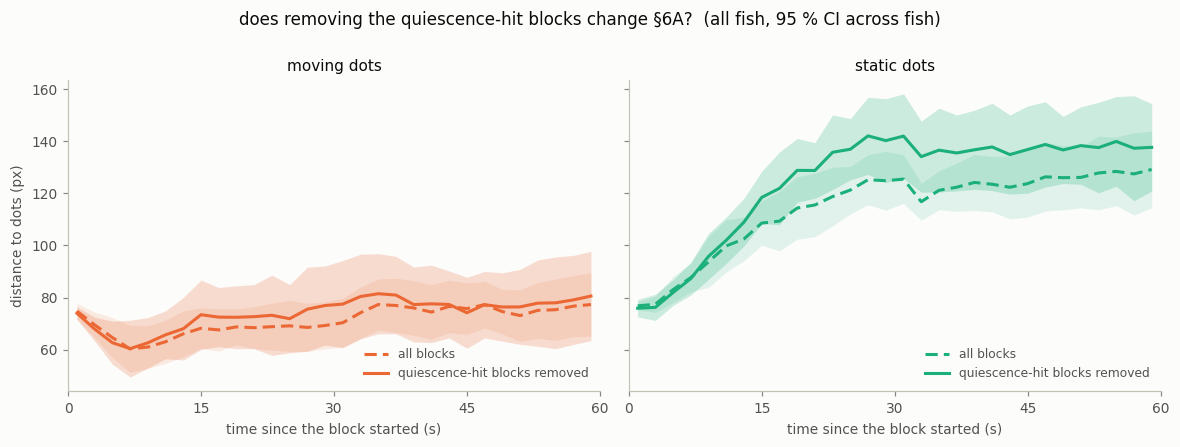

In [902]:
df_clean = drop_quiet_blocks(df, min_s=10, min_cover=0.0)
plot_approach_impact(df, df_clean, min_blocks_after=4)
plt.show()

`min_blocks=4`, not the default 8. The floor is an **absolute** block count, so it means
something different once cleaning has cut a fish from 35 blocks to 10: fish 9's static
bins then hold 4–10 blocks with a median of exactly 8, so the count flickers across the
floor and punches holes in an otherwise continuous curve. Those gaps are the threshold,
not the fish. Four keeps the CI honest at this sample size — raise it back to 8 to see the
effect.

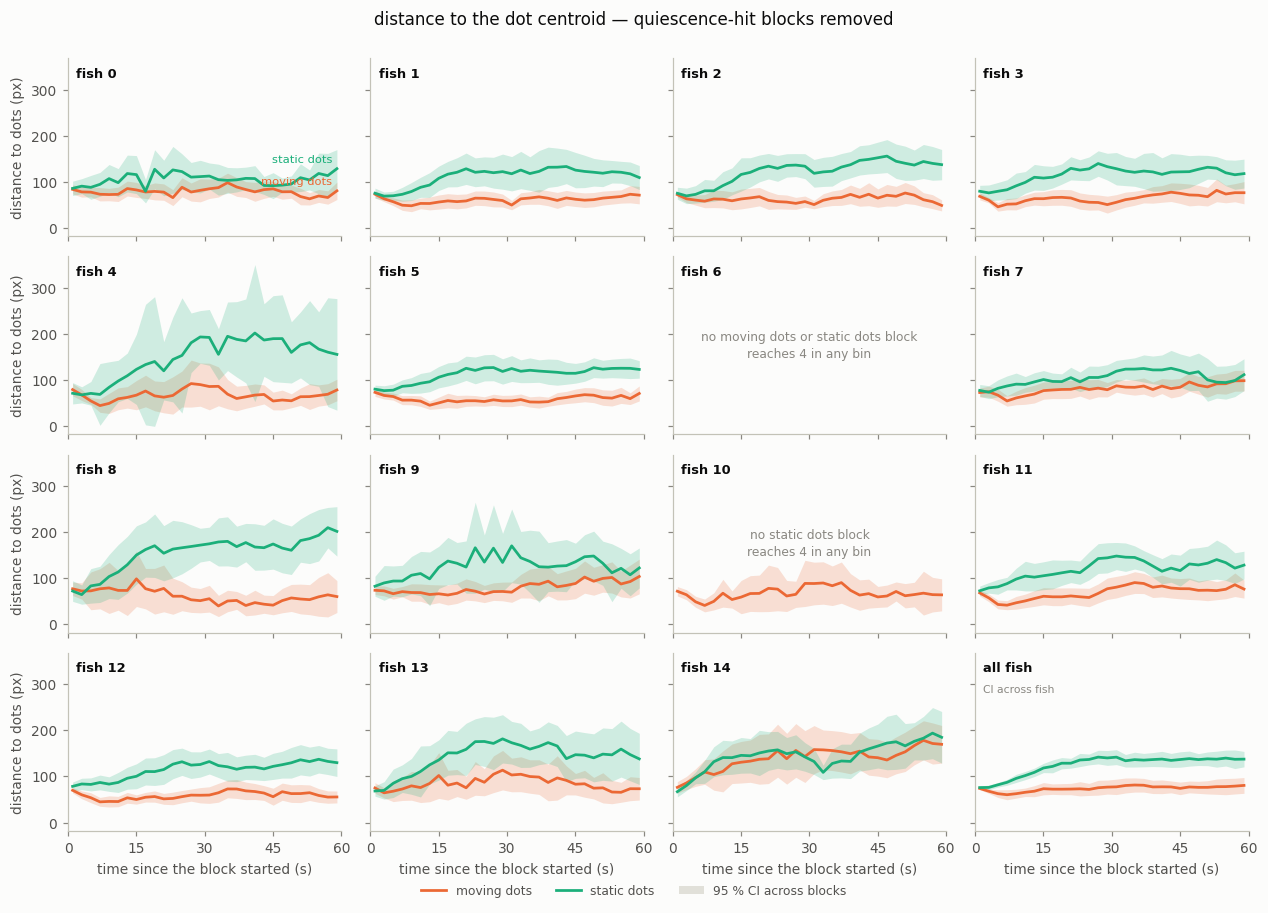

In [903]:
plot_approach(df_clean, min_blocks=4,
              title="distance to the dot centroid — quiescence-hit blocks removed")
plt.show()

And the individual worst stretches, with the block each one starts in and how far into
that block the fish went quiet.

In [904]:
worst_gaps(df, n=15, min_s=10)

,fish_id,block,cond,into_block_s,start_min,gap_s,stimulus
0,1,stim 23,moving,20.9,43.347778,426.5,CLsemi1800_g0-6_s3.5-3.5
1,8,stim 9,moving,10.6,17.510000,334.5,CLsemi1800_g0-1_s3.5-3.5
2,14,stim 34,moving,44.1,63.901667,319.5,CLsemi1800_g0-4_s3.5-3.5
3,10,stim 0,moving,53.3,1.722222,303.2,CLsemi1800_g4-0_s3.5-3.5
4,6,pause 76,none,17.7,139.628333,293.5,inter_stim_pause
5,2,stim 43,moving,55.4,80.590000,288.3,CLsemi1800_g0-8_s3.5-3.5
6,8,stim 40,static,54.3,75.071111,279.0,CLsemi1800_g0-4_s0-0
7,14,stim 46,moving,21.2,85.520000,277.7,CLsemi1800_g6-0_s3.5-3.5
8,10,pause 90,none,15.9,165.265556,269.7,inter_stim_pause
9,8,stim 23,moving,52.7,43.878333,256.6,CLsemi1800_g0-6_s3.5-3.5


**Is this quiescence or lost tracking?** The distinction decides whether these fish have a
behavioural problem or the data does. The check below reads the raw position column of
every per-frame file and reports untracked (NaN) runs — *measured: every fish has exactly
one NaN run and it sits at frame 0, before tracking locks on*, so no mid-session dropout
can account for any gap above. ~4 s per fish; pass a short list to spot-check instead.

In [905]:
tracking_check([6, 8, 10, 4, 14])       # tracking_check() for all 15 (~1 min)

  fish  6:   338 untracked frames in 1 run(s), longest 11.3 s at t=0.0 s
  fish  8:   276 untracked frames in 1 run(s), longest 9.2 s at t=0.0 s
  fish 10:   120 untracked frames in 1 run(s), longest 4.0 s at t=0.0 s
  fish  4:   120 untracked frames in 1 run(s), longest 4.0 s at t=0.0 s
  fish 14:   181 untracked frames in 1 run(s), longest 6.0 s at t=0.0 s


,nan_frames,n_runs,longest_s,longest_at_s,all_at_start
fish,,,,,
6,338,1,11.3,0.0,True
8,276,1,9.2,0.0,True
10,120,1,4.0,0.0,True
4,120,1,4.0,0.0,True
14,181,1,6.0,0.0,True


### 9 · When does a fish stop, and does it come back?

Three questions about the *shape* of a stop, over the 95 stimulus blocks per fish. A block
with no bouts at all never appears in the bout table, so both cells work from
`block_profile`, which puts those blocks back in — they are exactly the ones being asked
about.

**Does it stop at the end of a block?** Sometimes, but it is not the usual pattern: the
median silent tail is only ~1 s, so a fish normally bouts right up to the last second.
**Does it stop and start again?** Yes, and this is the more common shape.

In [906]:
stops = stop_summary(df, thr=10)
stops

STIMULUS blocks, n=1425  (threshold 10 s)
  silent for the whole block                   5.5 %
  of the blocks it did bout in:
    last bout more than  5 s before the end   22.7 %
    last bout more than 10 s before the end   15.0 %
    last bout more than 20 s before the end    8.4 %
    median silent tail                         1.2 s   (mean 5.3 s)
  STOPPED AND RESTARTED inside the block      23.8 %  (1.15 pauses each, longest median 14.6 s, max 51.9 s)


,blocks,silent_all_pct,ends_early_pct,median_tail_s,mid_pause_pct,median_mid_pause_s
fish,,,,,,
0,95,0.0,2.1,1.5,22.1,11.8
1,95,5.3,6.7,0.9,18.9,11.4
2,95,4.2,7.7,1.0,20.9,13.7
3,95,1.1,9.6,1.4,18.1,16.9
4,95,9.5,29.1,2.0,39.5,13.5
5,95,0.0,3.2,0.7,7.4,12.5
6,95,16.8,39.2,5.8,40.5,23.5
7,95,4.2,4.4,0.8,17.6,13.4
8,95,16.8,32.9,4.0,32.9,15.7


**Does the next block wake it up?** Compare the latency from a block's onset to the first
bout in it, after a block the fish stopped in versus after a normal one. The curve is an
ECDF over *all* such blocks, so where it plateaus below 100 % is the share in which the
fish never bouted at all.

⚠ The schedule strictly alternates, so "the next block is a stimulus" also means "it went
quiet during a pause", and vice versa. Read the `dots appear` / `dots vanish` rows as
descriptions, not as a clean test of which transition rouses a fish.

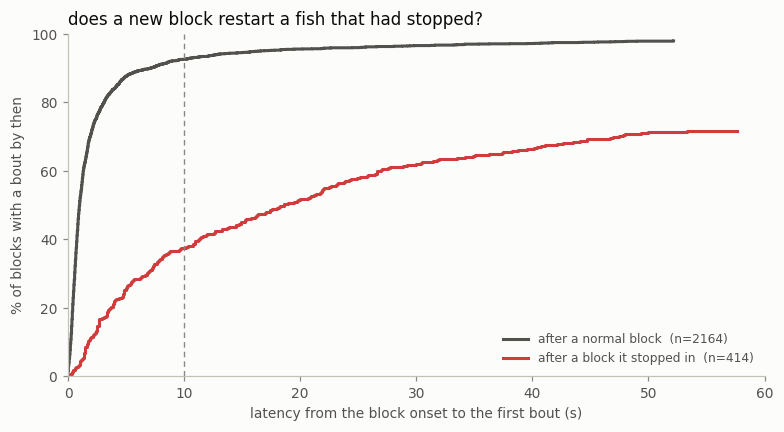

n  median_s  pct_under_2s  \
previous block              next block                                    
after a block it STOPPED in any           414.0      8.60          11.1   
                            dots appear   213.0      7.00          14.6   
                            dots vanish   201.0     14.43           7.5   
after a normal block        any          2164.0      0.97          70.9   
                            dots appear  1033.0      1.30          64.5   
                            dots vanish  1131.0      0.77          76.7   

                                         pct_under_5s  pct_no_bout  
previous block              next block                              
after a block it STOPPED in any                  25.4         28.3  
                            dots appear          36.2         12.7  
                            dots vanish          13.9         44.8  
after a normal block        any                  87.6          2.1  
                            dots appear          87.5          0.7  
                            dots vanish          87.6          3.4

In [907]:
plot_restart(df, thr=10)
plt.show()
restart_table(df, thr=10)

### 10 · One fish, the whole session

Everything above is per block or pooled. This is the raw 174 minutes for a single fish,
wrapped over rows so it is legible — the picture behind the statistics: long dead stretches
alternating with active ones.

Raw 30 fps speed, no downsampling, so **a dead period is a flat line and an active one is a
band of bout peaks**. Two channels that do not fight: the background tint is what was on
screen, and the black bar along the bottom is a stretch of more than 10 s with no bout —
the same gaps §8 counts. At ~8 blocks per row the periods are tinted but not named
individually; the legend carries that.

Change `FISH_ID` to any of 0–14. Fish 6 is the extreme (74 % dead), fish 5 the mildest
(5 %) — worth flipping between the two.

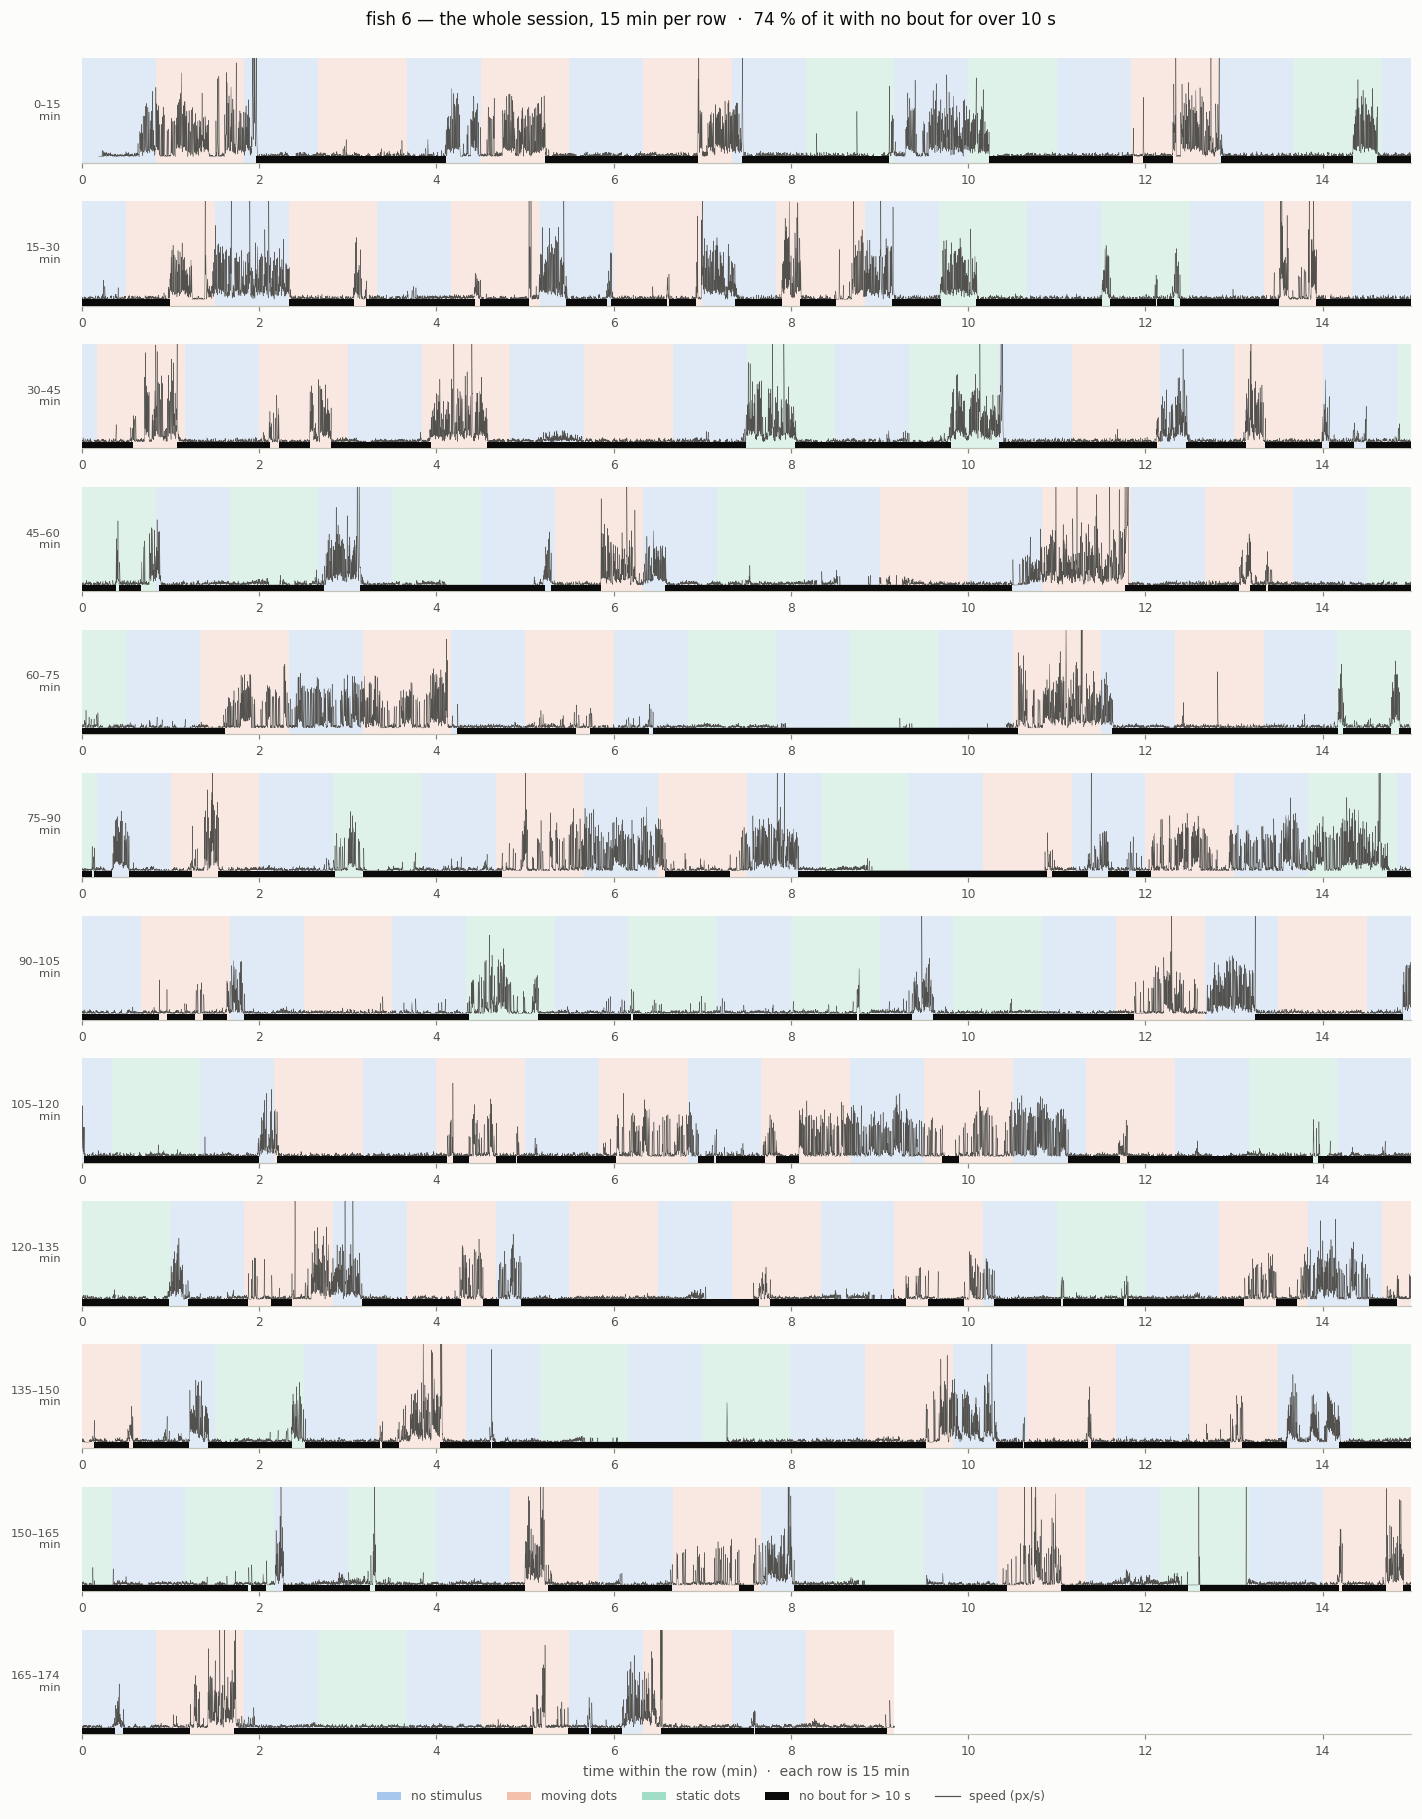

In [908]:
FISH_ID = 6            # 5 is the most active fish, 6 the least
plot_session(df, FISH_ID, row_min=15, thr=10)
plt.show()

### 11 · Where is the fish when it is dead, and where when it is active?

The occupancy heat map from `segment_bouts.ipynb`, split in two by the §8 definition:

* **dead** — every frame inside a no-bout stretch longer than 10 s (`dt_s > 10`), taken
  strictly *between* the two bouts that bracket it, since those endpoints are themselves
  bouts;
* **active** — every other frame between the fish's first and last bout.

Frames outside that span (the recording starts before the first bout, and can run on after
the last) belong to neither and are excluded rather than quietly binned.

Red is the **physical** 100 mm dish wall from the raw `ROIdef`, not the trajectory-derived
`data/data/ROIdef.csv` — the same geometry §1's `radial` channel uses.

⚠ **The two figures are not the same kind of picture.** A dead frame is a stationary fish,
so the dead map is dwell time over a handful of resting spots, and its `p99/R` says how far
out those spots sit — not how much of the dish got used. The active map is where the fish
actually swims. Each panel is log-normalised on its own, so compare **shape** between the
two figures, not intensity.

The first cell reads all 15 per-frame CSVs (~1 min); the second is instant off the cache.

dead: 29.9 % of tracked frames on average, mean p99/R = 0.76


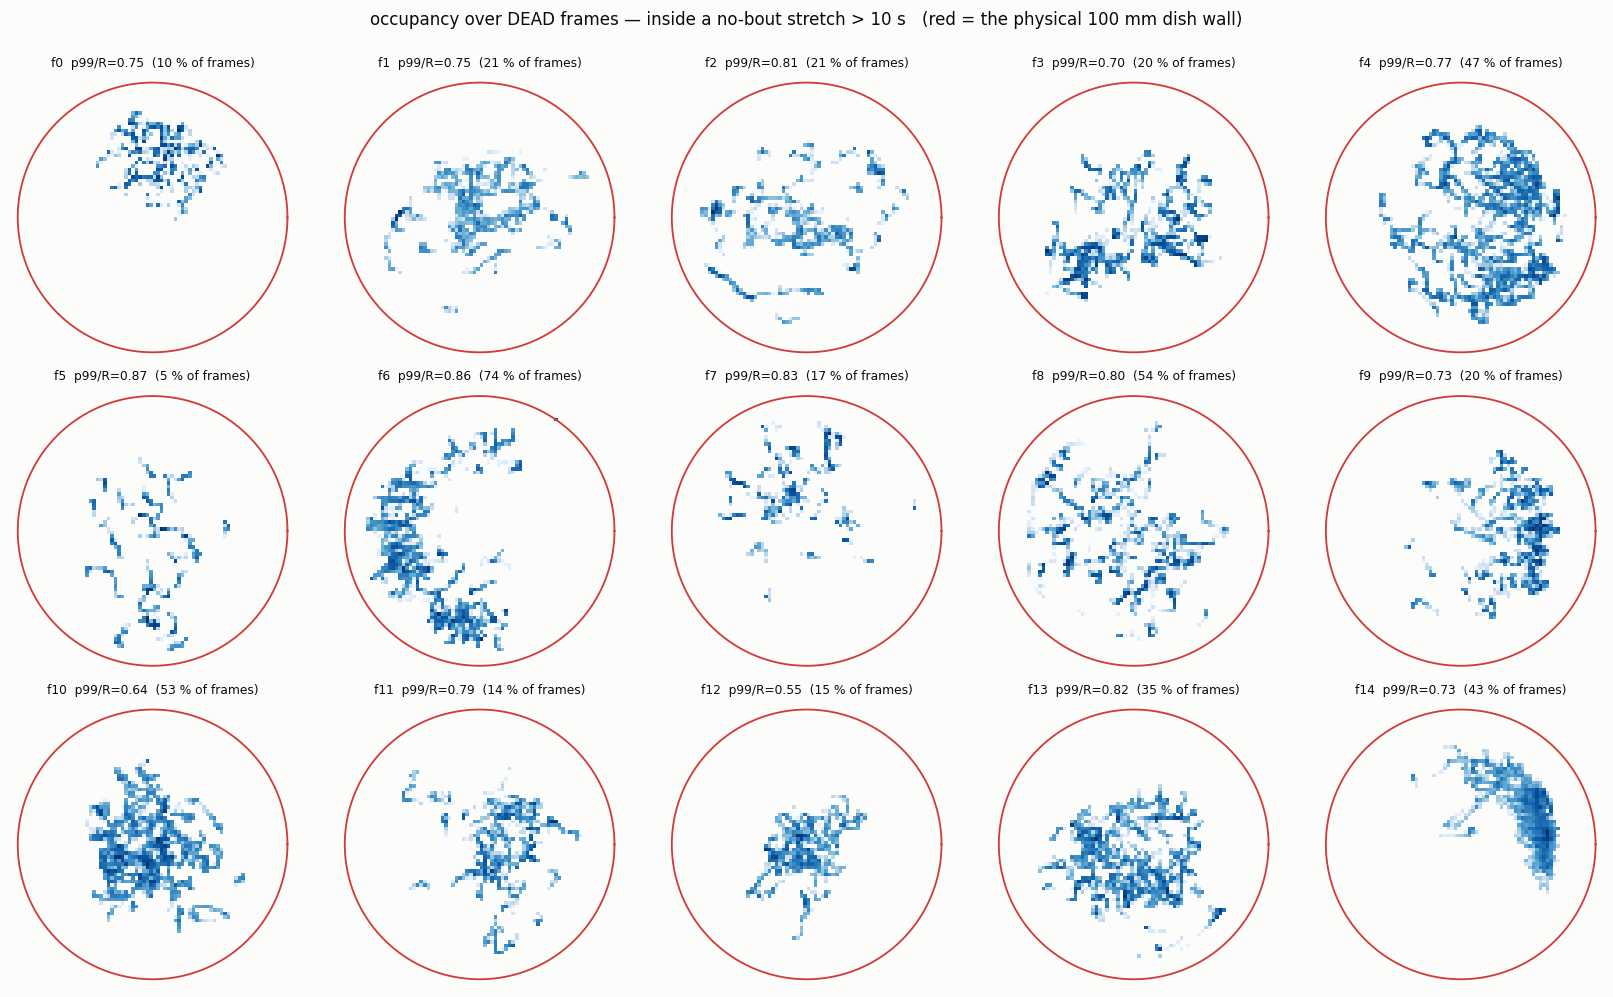

In [909]:
# Occupancy during DEAD periods — where a fish sits once it has stopped
plot_occupancy(df, which="dead", thr=10)
plt.show()

active: 69.5 % of tracked frames on average, mean p99/R = 0.83


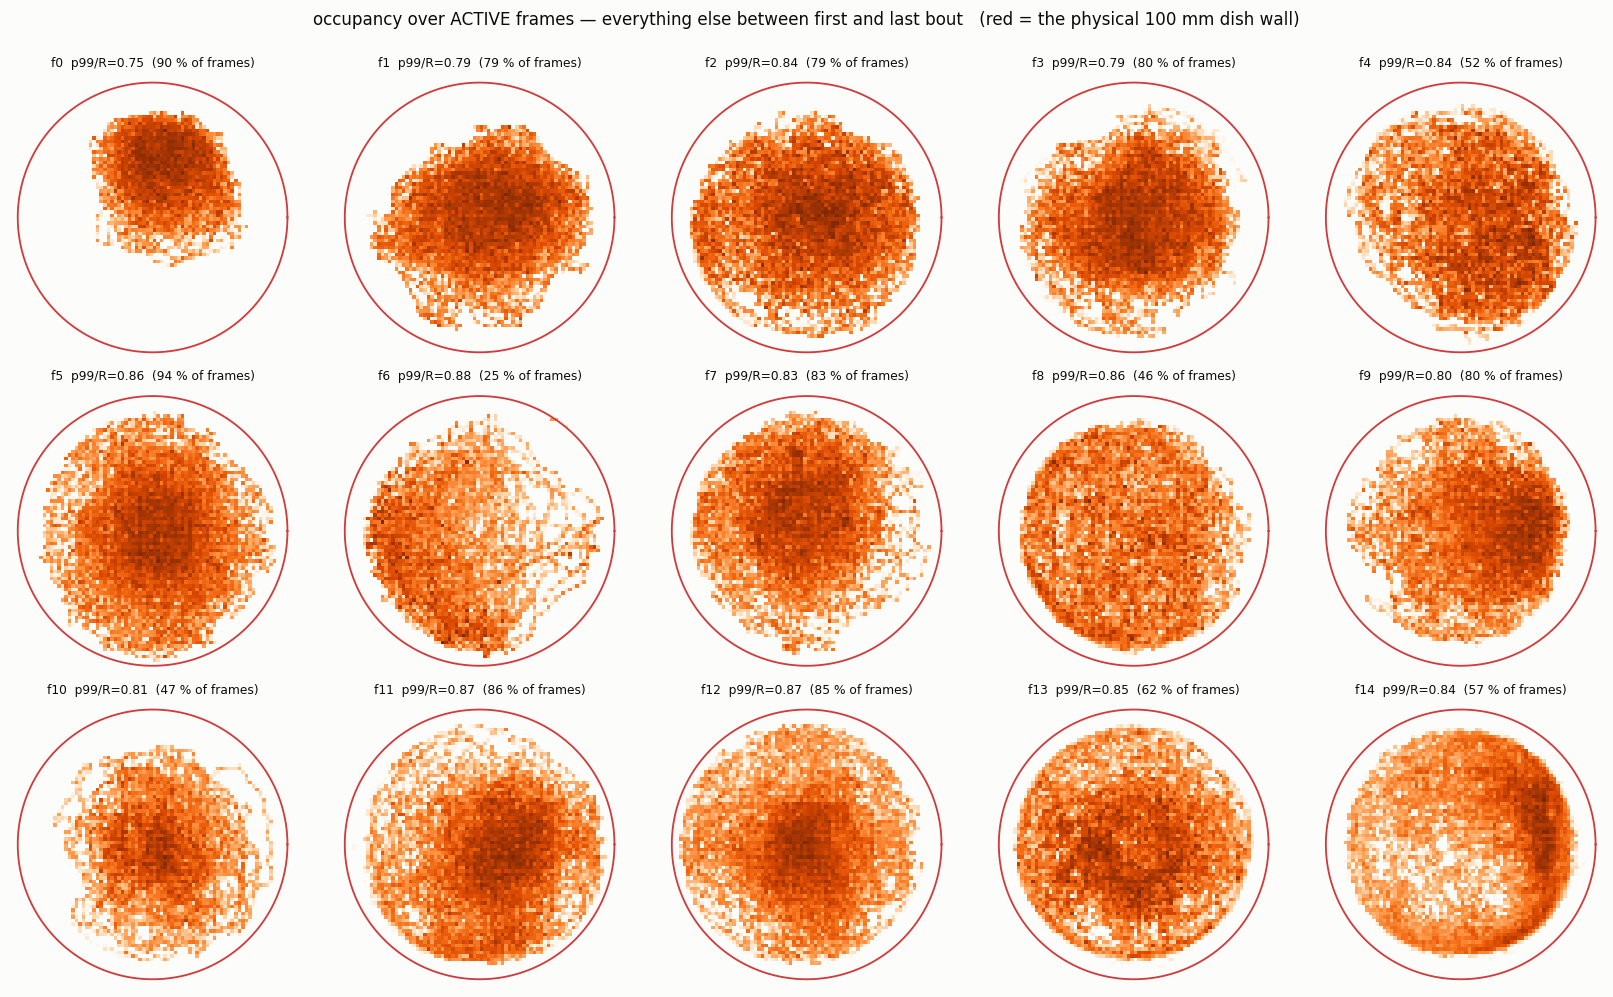

In [910]:
# Occupancy during ACTIVE periods — where it goes while it is swimming
plot_occupancy(df, which="active", thr=10)
plt.show()

### 12 · The `Δt` tail, per fish

§1's `dt` panel is a **density** on a **0.2–30 s** axis. That is the right picture for the
bouting mode and the wrong one for the long breaks: it renormalises, and it stops an order
of magnitude short of the data, which runs to 426 s. So the weight in the tail is not that
it is small — it is off the page.

This is the same variable as raw counts over the whole range. Both axes are log: x because
`Δt` spans four decades, and **y because the counts do too** — a mode bin holds several
hundred bouts and a tail bin holds one to ten, so on a linear count axis the tail lies flat
on the floor, which is exactly how it goes unnoticed. Everything in the shaded region is a
"dead" stretch by the §8 definition; each panel gives the count beyond it and that fish's
longest interval.

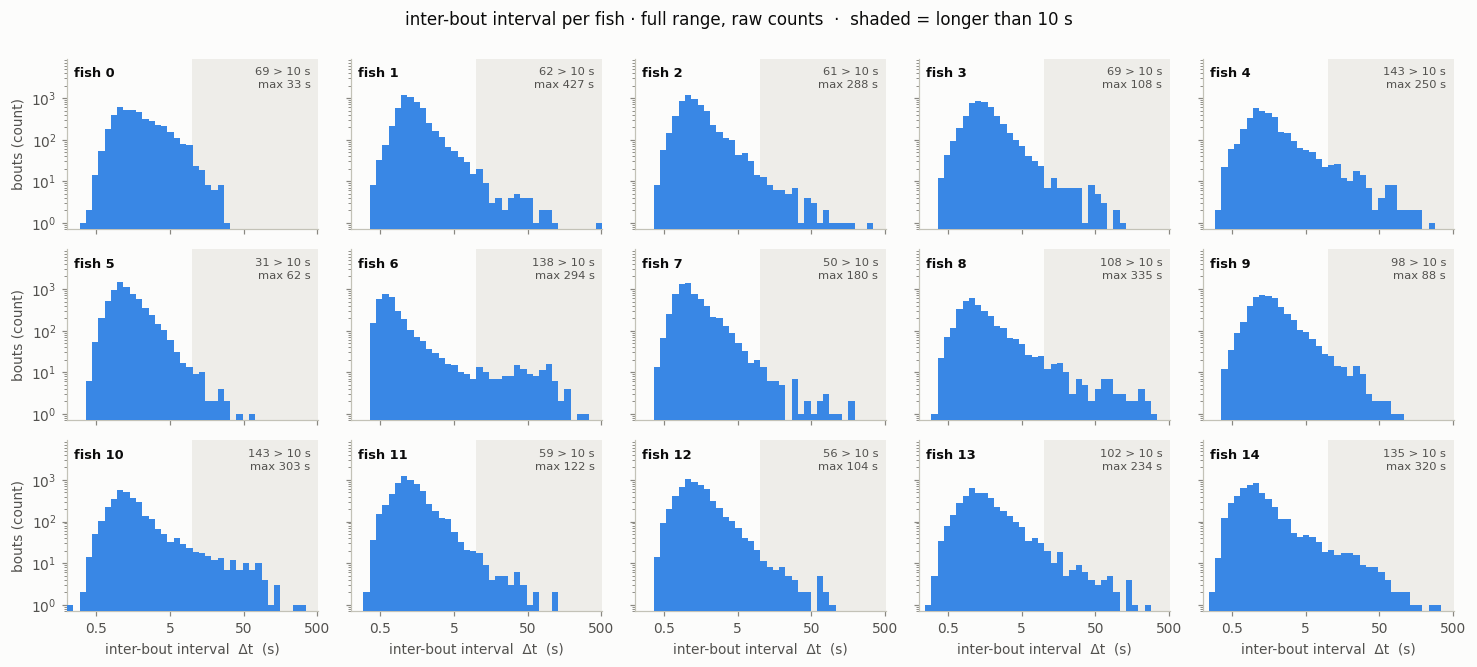

In [911]:
plot_dt_hist(df, thr=10)
plt.show()

The same variable split at the threshold. ⚠ **That split is circular** — a "dead" stretch
*is* a `Δt` above the threshold — so it reassigns no bout and contains nothing the figure
above does not. What it buys is resolution: each half gets its own bins and y scale
instead of one squashing the other.

Below the line: the bouting rhythm on its own, 40 bins over 0.2–10 s.

Note what "max" can mean here. The largest interval *inside this subset* is just the 10 s
threshold for every fish (9.4–10.0 s) — it is the cut, not the fish. So each panel gives
the **p95** instead, marked with a dashed line, which is where that fish's bouting rhythm
actually tails off and varies 3× across fish (2.1 s for fish 6 to 6.1 s for fish 0); the
fish's true longest interval is printed at the bottom right, pointing off the axis, since
by construction it lives in the *dead* figure.

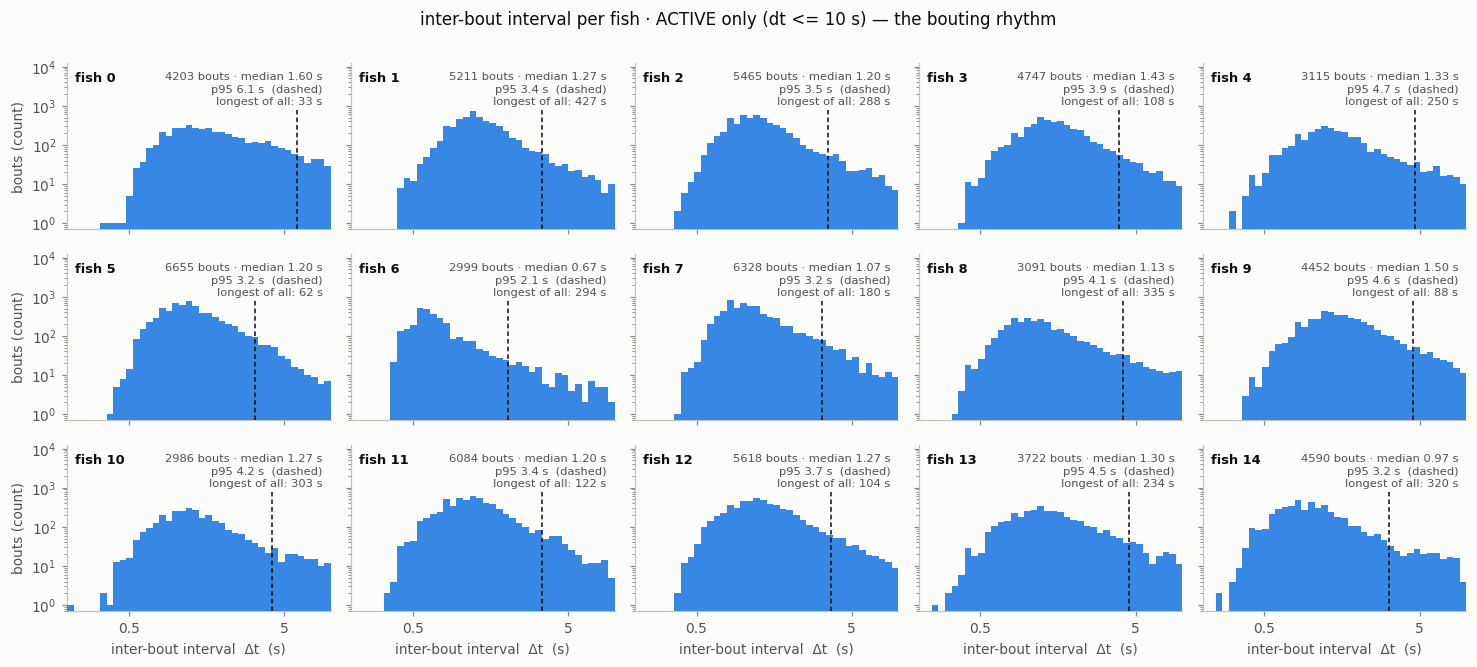

In [912]:
plot_dt_hist(df, thr=10, subset="active")
plt.show()

Above it: how long the breaks actually last, 40 bins over 10–512 s. This is the one that
matters for modelling — it is the shape a single `Δt` head has to reproduce and cannot.

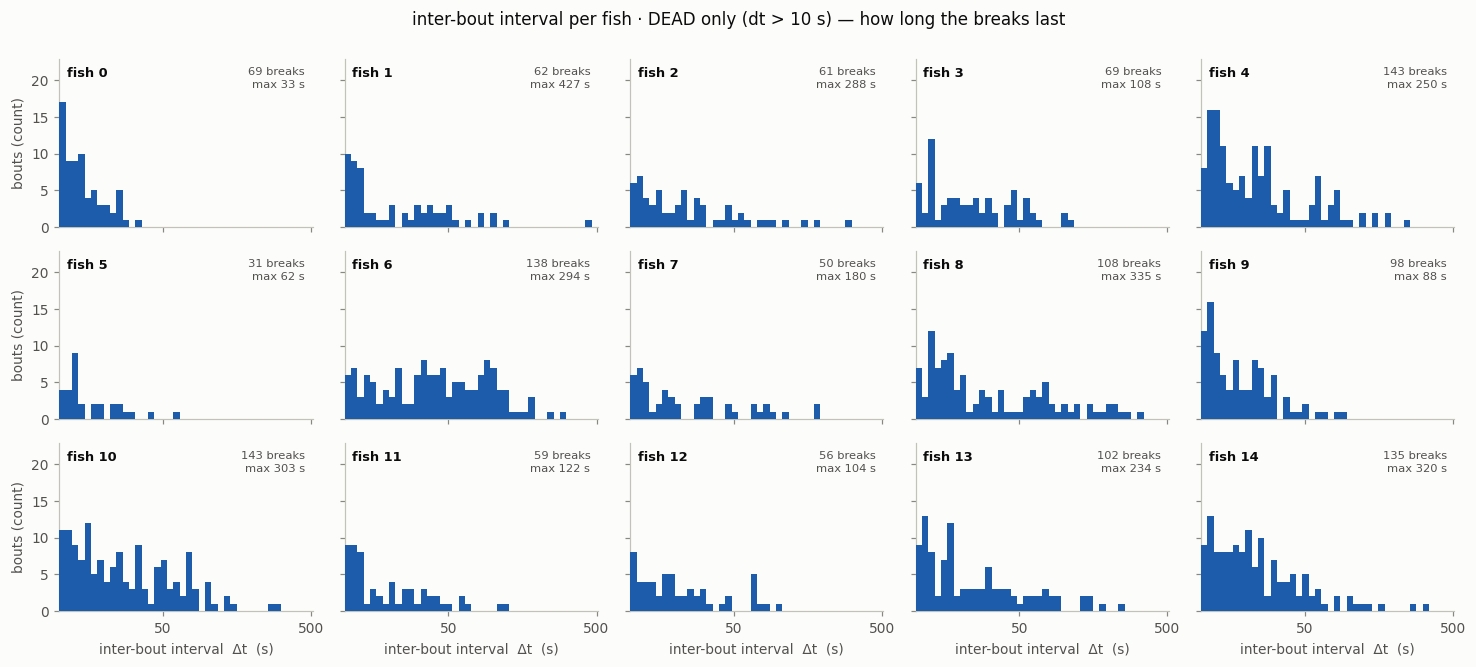

In [913]:
plot_dt_hist(df, thr=10, subset="dead")
plt.show()

### 13 · The distance head, same three ways

⚠ **This split is not circular, unlike §12's.** A bout's distance is a different variable
from its `Δt`, so "dead" genuinely selects a different set of rows — the bouts that *start*
a long break — and the shape really can differ. Bin edges are held fixed across the three
figures so they can be laid side by side.

⚠⚠ **But read the dead panels for what they are.** `distance_px` is measured onset to
onset, so on a row whose `Δt` is 300 s it is the drift *across the break*, not a bout. A
fatter tail there says something about the gap, not about how the fish swims. (10 bouts
with exactly zero displacement fall off the log axis.)

Each panel gives that fish's **max**. A big one is not automatically suspect: distance is
onset-to-onset and is *not* covered by `segment_bouts`' displacement gate, which only looks
at a ±0.5 s window around the onset — so 145 px is unremarkable when `Δt` is 86 s. What
decides is the implied speed, and any bout over **50 mm/s** (about the ceiling for a larval
zebrafish burst) is marked with a red ▾ and counted. There are exactly **two in the whole
dataset**, both fish 5.

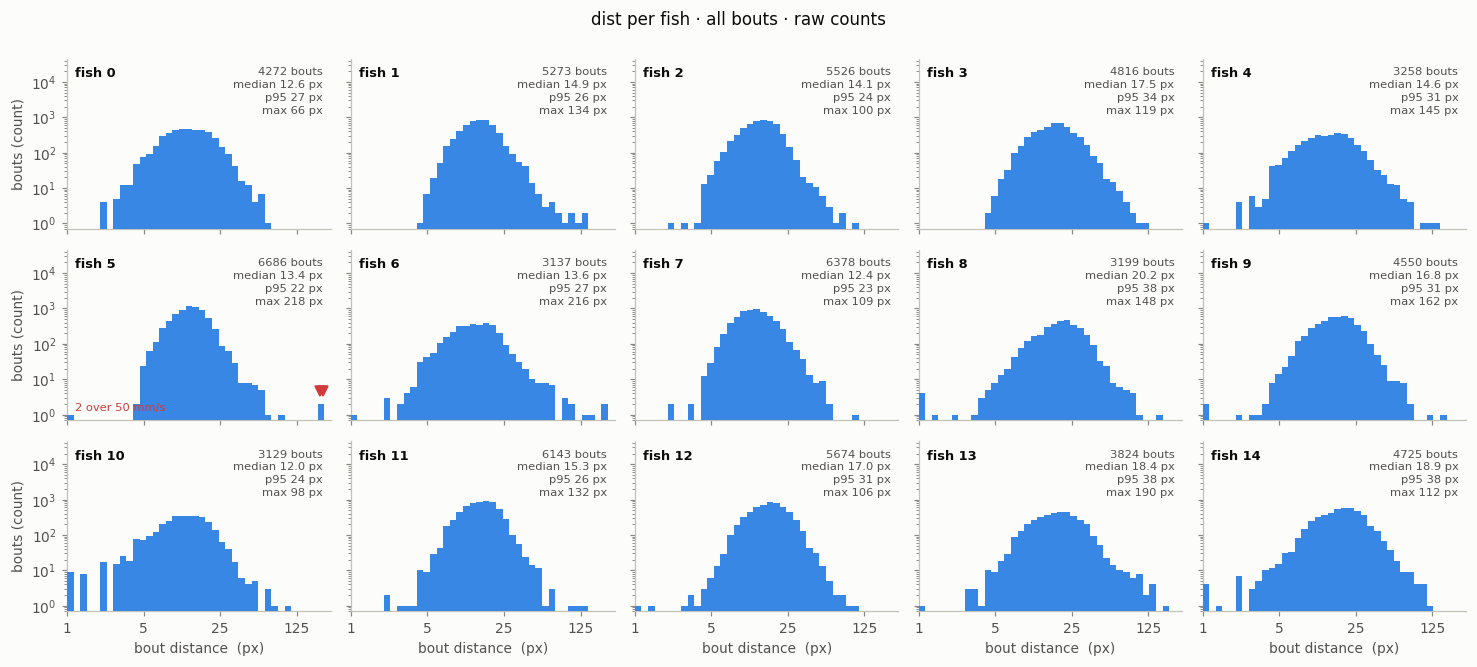

In [914]:
plot_head_hist(df, "dist", subset="all", thr=10)
plt.show()

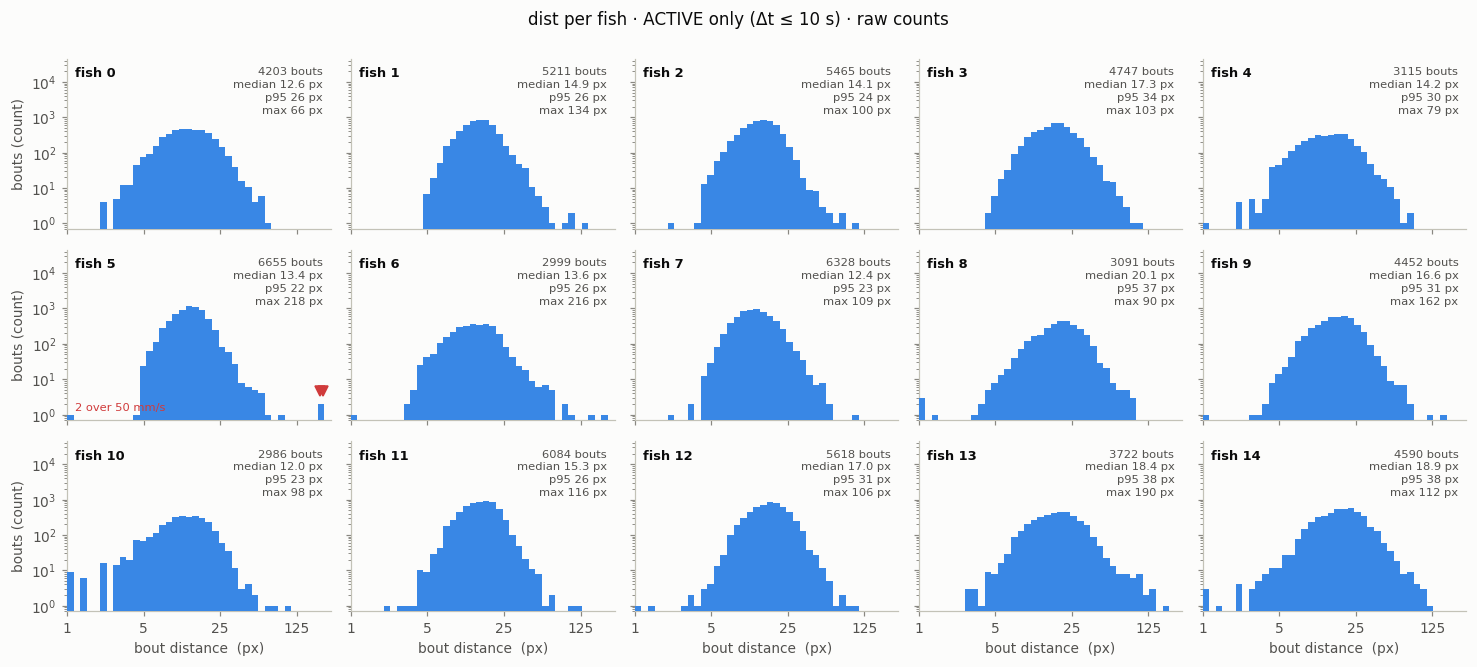

In [915]:
plot_head_hist(df, "dist", subset="active", thr=10)
plt.show()

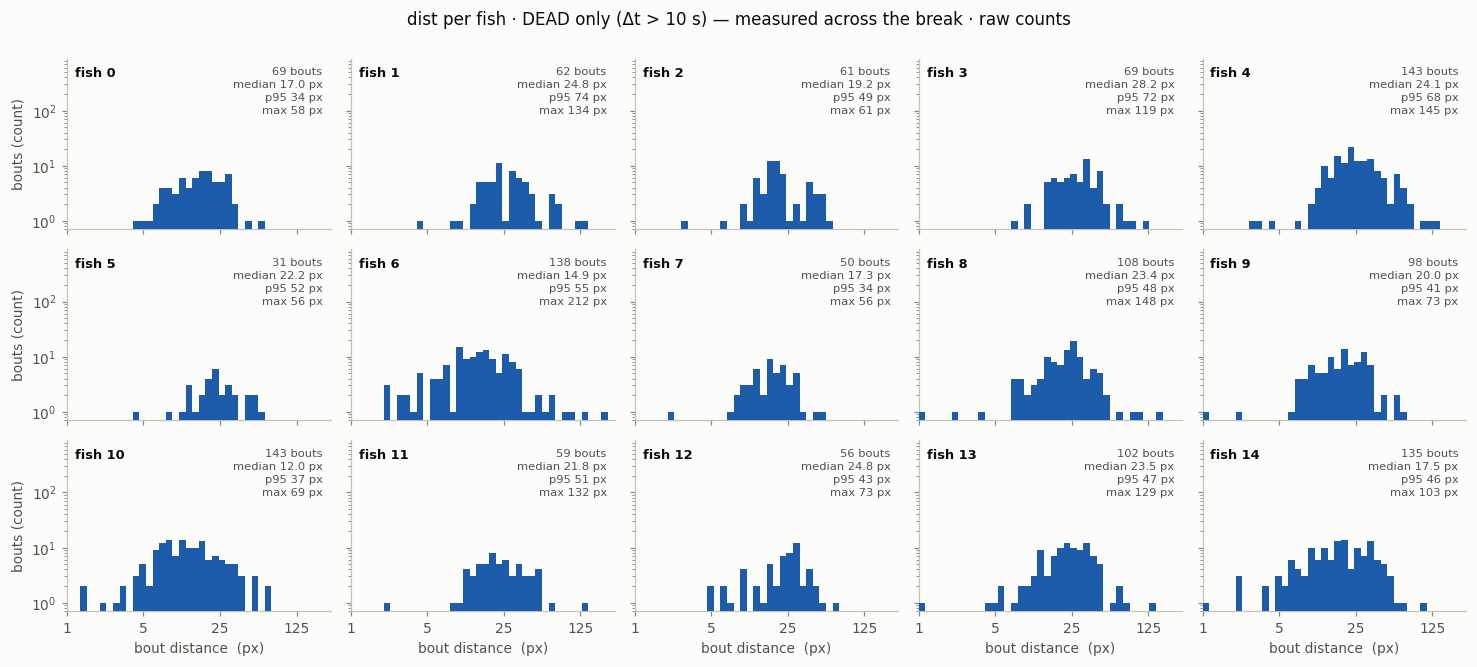

In [916]:
plot_head_hist(df, "dist", subset="dead", thr=10)
plt.show()

#### Look at the two impossible ones

Both are fish 5, both in **`pause 32`**, back to back at t = 1.3 s and 2.1 s. Checking the
raw frames settles what they are — **a single bad frame**:

```
frame 105639   x=174  y=139     <- onset of the first bout
frame 105663   x=300  y=299     <- onset of the second; 217 px in ONE frame = 1814 mm/s
frame 105664   x=164  y=129     <- straight back, 218 px
```

The tracker loses the fish for exactly one frame, reports a position at the dish edge, and
recovers immediately. That one frame poisons **two** bout rows: the earlier bout's
`distance` because its next onset happens to land on the glitch, and the glitch frame's own
bout. The ~180° `Δθ` is the out-and-back.

**Why this one slipped past the displacement gate.** Most teleports are in fact caught, and
by the *lower* gate rather than the upper one: the fish returns to where it was, so net
displacement over the ±0.5 s window is ≈ 0 and the candidate is rejected as sub-threshold.
This pair got through because the glitch frame *became an onset itself*, so the distance is
measured onset-to-onset from a spurious position to a real one — a channel neither gate
inspects. Catching that needs a per-frame speed limit.

The clip is 8 s (`start_s` + `max_frames` trim the window; the speed panel still shows the
whole block with the cursor running through the trimmed part). The excursion itself lasts
one frame, but the 2 s trail draws it as a line out to the rim and back, so it is easy to
catch at normal speed — pass `fps=5` to crawl through it.

In [917]:
# The 8 s around the two physically impossible bouts (fish 5, pause 32, t = 1.3 and 2.1 s)
# make_block_video(5, ["pause 32"], ROOT / "mp4_fish_5_impossible.mp4",
#                  start_s=0, max_frames=8 * 30)

#### The same thing in other fish

Fish 5 is not special. The §13 check only catches a glitch that happens to land **on** a
bout onset — 2 rows in 70,590. Looking at the raw per-frame positions instead, where the
artefact actually lives, **every fish has them**: the largest single-frame step per fish
runs from 23 px (fish 7, 190 mm/s) to 226 px (fish 6, **1883 mm/s**), and each fish has
20–63 frames over 100 mm/s across the session.

`worst_jumps` returns the biggest jump per fish with the block and time, so the three
clips below are the three worst outside fish 5. `snap_back` is the next frame's step: near
zero means the position teleported and came straight back, which is the tracking signature.
A real fast swim would keep going.

**How much does this actually contaminate the bouts?** Not much, and it is worth being
precise: **558** frames across the 15 fish exceed 100 mm/s, but only **51 bouts (0.07 %)**
have an onset within 5 frames of one. The reason most glitches produce no bout is the
*lower* displacement gate — the position returns immediately, so net displacement over the
±0.5 s window is ≈ 0 and the candidate is thrown out as sub-threshold. The gate that looks
useless on the upper end is doing the work on the lower one.

Fish 6's `stim 88` below is the worst case rather than the typical one: it is a block in
which the fish barely moved, so the only two bouts detected in the whole 60 s are both
sitting on 1300 px/s spikes.

In [918]:
# jumps = worst_jumps(n=3, exclude=(5,))
# print(pd.DataFrame(jumps).to_string(index=False))

# for j in jumps:      # 8 s centred on each jump
#     make_block_video(j["fish"], [j["block"]], ROOT / f"mp4_jump_f{j['fish']}.mp4",
#                      start_s=max(0, j["t_s"] - 4), max_frames=8 * 30)

### 14 · The turn head, same three ways

Same three views for `Δθ`. Linear x — unlike `Δt` and distance this variable is bounded at
±180°, so there is no tail to go looking for; y is still log because the counts span
decades. The same caveat applies with more force: `dtheta` is the change in travel
direction between consecutive onsets, so on a dead row it is the net reorientation over
minutes and should look near-uniform.

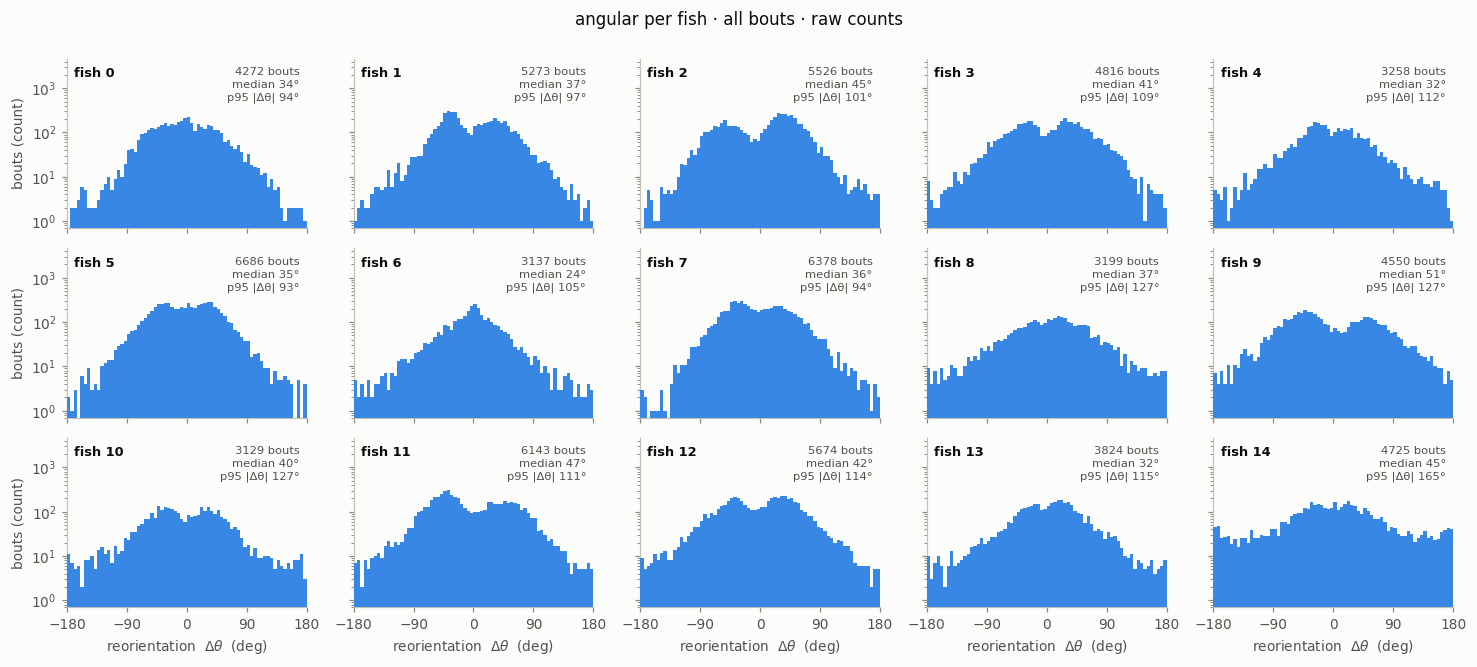

In [919]:
plot_head_hist(df, "angular", subset="all", thr=10)
plt.show()

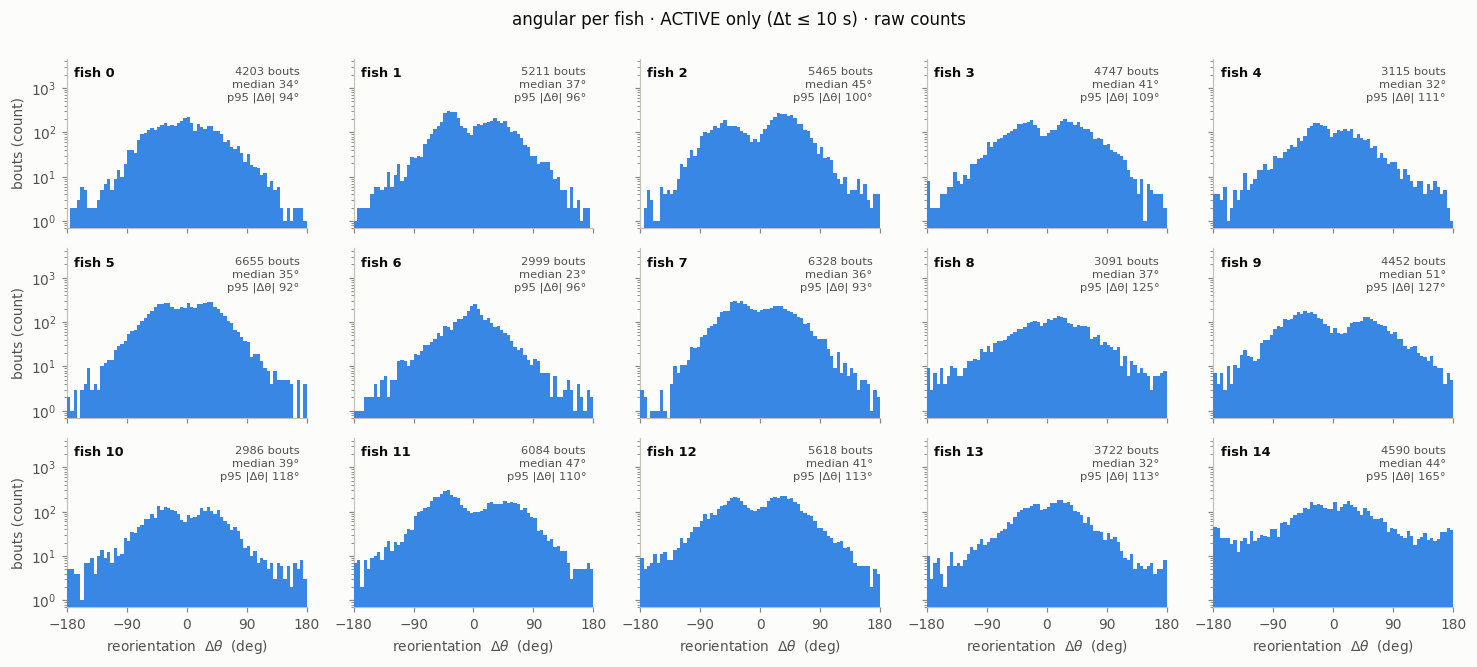

In [920]:
plot_head_hist(df, "angular", subset="active", thr=10)
plt.show()

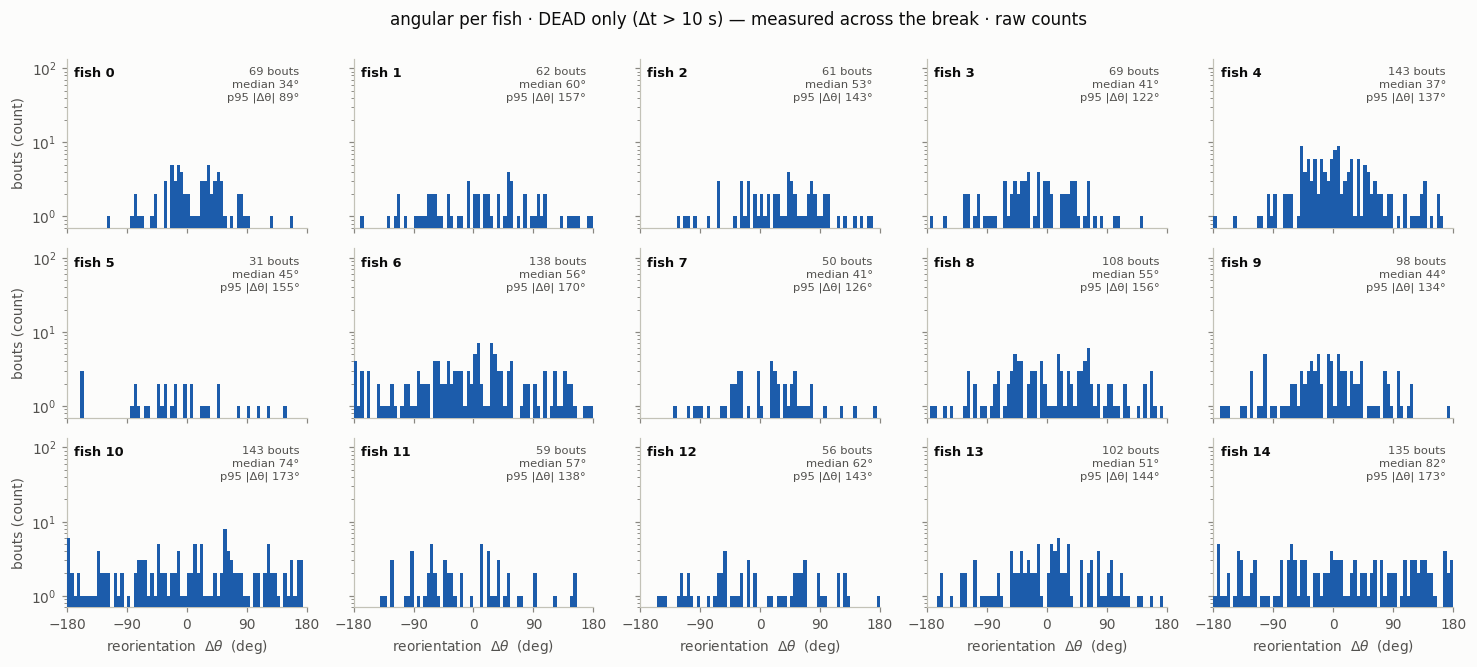

In [921]:
plot_head_hist(df, "angular", subset="dead", thr=10)
plt.show()

#### Where do the ±180° turns happen?

**In the outer dish — but "at the wall" overstates it.** Using only bouts whose two legs
both stay under 10 s (so nothing is measured across a pause):

| | \|Δθ\| > 150° | rest |
|---|---|---|
| median r/R | **0.764** | 0.435 |
| in the 5 mm wall shell | 36 % | 13 % |
| at r/R > 0.85 | **8.6 %** | 1.2 % |

So the effect is a strong, graded radial one — reversals concentrate in the outer half —
rather than contact with the boundary: only about a third are in the wall shell and under
a tenth are within 15 % of the radius of it. Their q25–q75 is 0.58–0.82.

It is not one odd fish either: the shift holds **within 13 of the 14** fish individually
(+0.105 to +0.436), only fish 10 (the most central fish) going the other way, and it is
still 0.737 vs 0.420 with fish 14 excluded entirely.

And it is not the fish sitting still — the median shorter leg at |Δθ| > 150° is **12.2 px
against 12.5 px** elsewhere. The displacement is ordinary; only its direction reverses.

`pick_reversal_block` finds an **active** block (≥25 bouts, no gap over 10 s — otherwise
the winner is always a quiet block whose "turns" span a pause) and ranks by how much
further out the reversals sit than that fish's own typical position in the same block. The
path plot draws each one as a hairpin: leg in, leg out.

 fish   block  n  n_rev  r_rev  r_other  contrast                     stim
   12 stim 78 51      5   0.81     0.64     0.171 CLsemi1800_g6-0_s3.5-3.5
    7 stim 72 44      4   0.80     0.63     0.165 CLsemi1800_g0-4_s3.5-3.5
   13 stim 26 57      4   0.81     0.67     0.144     CLsemi1800_g4-0_s0-0
    2 stim 78 58      6   0.83     0.71     0.127 CLsemi1800_g6-0_s3.5-3.5
   13 stim 31 53      4   0.86     0.75     0.107 CLsemi1800_g1-0_s3.5-3.5


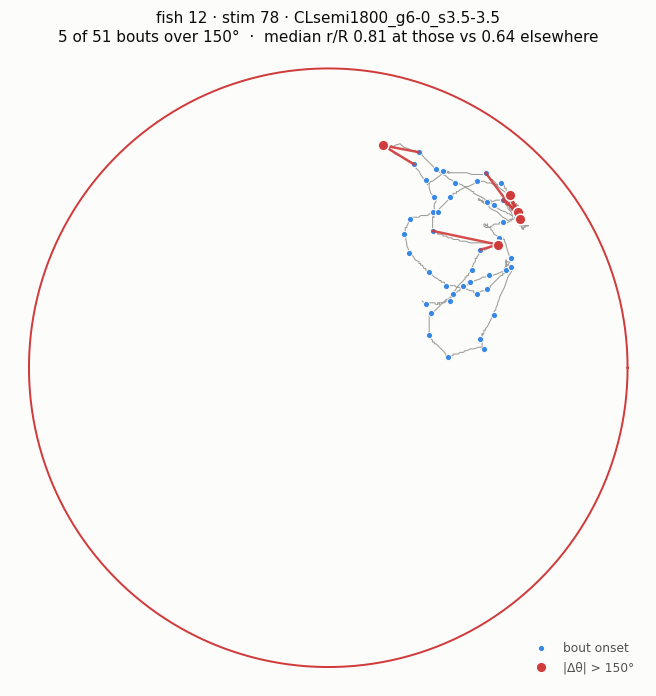

In [922]:
cands = pick_reversal_block(df, thr_deg=150, min_bouts=25, max_gap=10, exclude=(14,))
print(pd.DataFrame(cands[:5]).to_string(index=False))

best = cands[0]
plot_block_path(df, best["fish"], best["block"], thr_deg=150)
plt.show()

# and the same block as video, if you would rather watch it
# make_block_video(best["fish"], [best["block"]], ROOT / "mp4_reversals.mp4")

#### Are there really that many sharp turns?

Yes, and they are not evenly spread. Over the gap-free rows:

| threshold | share of bouts | median shorter leg | body axis agrees |
|---|---|---|---|
| \|Δθ\| ≤ 90° | 90.8 % | 12.6 px | **92 %** |
| > 90° | 9.2 % | 11.4 px | 59 % |
| > 120° | 3.6 % | 12.0 px | 52 % |
| > 150° | 1.4 % | 13.0 px | 51 % |
| > 170° | 0.5 % | 13.4 px | 51 % |

Two things to take from it. The **displacement never shrinks** — a 170° turn moves the fish
as far as a straight one — so none of this is a stationary-fish artefact. But the body-axis
cross-check **collapses from 92 % to ~51 %** as soon as the turn passes 90°, and stays there.

That is not proof they are wrong. `dtheta_ori` is measured from body orientation at the
speed *peak*, i.e. mid-turn, while `dtheta` is the net displacement direction over the whole
interval — during a large turn those genuinely differ, and the flip-correction in
`segment_bouts` resolves the head/tail ambiguity using travel direction, so the two are not
independent. It does mean **the sharp end of the turn distribution is the least trustworthy
part of it**, and worth treating separately from the ±30° lobes.

There is weak sequential structure too, which noise would not produce: after a >150° turn
the next turn goes the *same* way 58.5 % of the time, against 52.5 % after an ordinary turn.

The block below is the extreme case. Note the whole top-8 list is **fish 14** — sharp turns
are overwhelmingly one animal's habit (8.4 % of its bouts over 150°, vs 0.45–2.6 % for the
other fourteen), and in this block its reversal legs are **26 px**, twice the dataset median.
Large, deliberate, repeated turns — not noise.

 fish   block  n  n_rev  r_rev  r_other  contrast                     stim
   14 stim 76 62     16   0.78     0.77     0.003     CLsemi1800_g0-8_s0-0
   14 stim 13 66     15   0.81     0.79     0.017     CLsemi1800_g4-0_s0-0
   14 stim 59 65     15   0.82     0.78     0.033 CLsemi1800_g0-6_s3.5-3.5
   14 stim 70 62     13   0.80     0.77     0.036 CLsemi1800_g8-0_s3.5-3.5
   14  stim 9 71     10   0.80     0.76     0.037 CLsemi1800_g0-1_s3.5-3.5
   14 stim 75 61     10   0.67     0.60     0.075 CLsemi1800_g1-0_s3.5-3.5


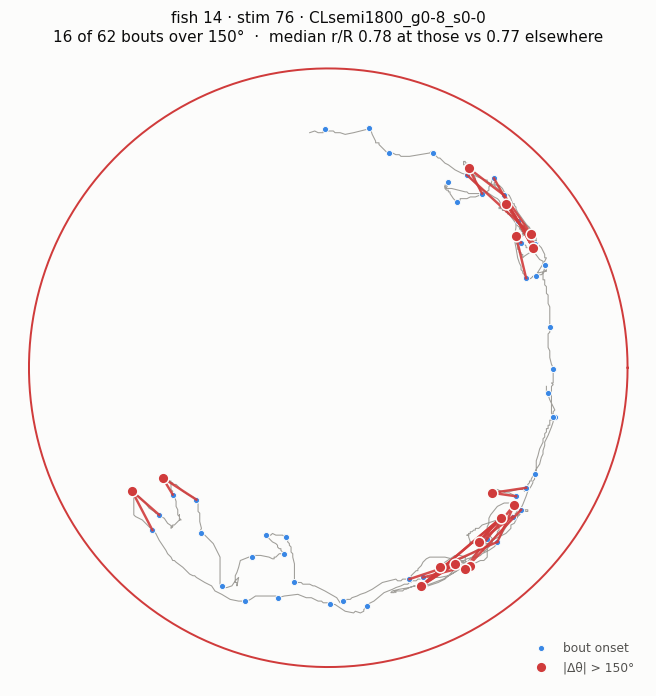

In [923]:
sharp = pick_reversal_block(df, thr_deg=150, min_bouts=25, max_gap=10, rank="count")
print(pd.DataFrame(sharp[:6]).to_string(index=False))

s0 = sharp[0]
plot_block_path(df, s0["fish"], s0["block"], thr_deg=150)
plt.show()

# the same block at real speed — the shuttling reads much more clearly in motion
# make_block_video(s0["fish"], [s0["block"]], ROOT / f"mp4_sharp_f{s0['fish']}.mp4")

#### Do the ±180° turns come in cancelling *pairs*, and does that mean they are fake?

Watching the block, the sharp turns look like they arrive back to back — a reversal, then
straight back again. They do, and that is worth taking seriously, because
`dtheta_i = theta_i − theta_{i−1}` means **one** wrong leg direction corrupts **two**
consecutive turns as +180 then −180. A cancelling pair is exactly what a measurement error
would look like.

`reversal_pair_check` runs the three tests in order of what each can actually settle:

1. **Rate** — consecutive big turns happen **6.3× more often than independence predicts**
   (88 against 14). Structure exists; this says nothing about its cause.
2. **Cancellation** — 99 % of the pairs sum to under 45°, median 14°. Suggestive, but
   **necessary, not sufficient**: a genuine out-and-back cancels just as neatly.
3. **Decisive** — the path actually walked between onset *i−1* and *i+1* versus the two
   straight legs, plus the worst single frame in the window.

The third one answers it. Over 2.4 s the fish walks **80 px against 39 px** of straight
legs — **ratio 1.86** — reaching 24 px from where it started before returning, and the worst
single frame is **6.3 px (53 mm/s)**. A one-frame position glitch would give ratio ≈ 1 with
a step in the hundreds of px; the known fish 5 artefact steps **217 px** in one frame.

So the pairs are real curved out-and-back excursions, not a frame-assignment flicker — and
59 of the 86 are fish 14, the wall-shuttler again. Re-run this whenever the segmentation
parameters change.

In [924]:
pairs = reversal_pair_check(df, thr_deg=150)
pairs.head(10)

1. RATE       P(|dtheta| > 150) = 0.0143
              consecutive pairs 88 observed vs 14 expected  ->  6.3x chance
2. CANCELS    |sum of the pair| median 14°, 99 % under 45°   (necessary, not sufficient)
3. DECISIVE   over 2.42 s the fish walks 80 px against 39 px of straight legs  ->  ratio 1.86
              it gets 24 px from the start and back; worst single frame 6.3 px = 53 mm/s
              pairs with any frame over 100 mm/s: 8 of 86

  VERDICT: real out-and-back travel -- a one-frame glitch would give ratio ~1 and a step in the hundreds of px
  concentrated in fish 14 (59 of 86 pairs)


,fish,bout,secs,path_px,straight_px,ratio,excursion_px,max_step_px,max_step_mm_s
0,0,2670,7.67,100.7,46.1,2.18,17.0,6.4,53
1,2,1572,3.90,66.5,13.2,5.05,10.4,3.0,25
2,2,4574,2.53,50.2,33.4,1.50,18.9,3.2,26
3,2,4578,1.83,49.5,31.2,1.59,23.0,6.3,53
4,3,519,3.20,94.2,54.6,1.73,27.7,11.3,94
5,5,735,2.60,65.4,32.7,2.00,13.2,12.5,104
6,5,1246,3.70,108.2,70.2,1.54,31.3,22.6,189
7,6,2347,4.30,52.3,15.9,3.29,10.4,3.2,26
8,7,5056,5.73,77.2,24.6,3.14,15.1,3.2,26
9,8,585,3.27,243.3,2.0,121.67,8.5,9.5,79


### 15 · Does behaviour change over the session?

Everything so far pools the whole 174 minutes. This asks whether the fish are doing
something different at the end than at the start — **per fish**, so a session effect cannot
be confused with individuality.

**Two different questions, kept apart.** A *trend* is monotone change (habituation,
fatigue); a *slow fluctuation* is behaviour correlated on a minutes timescale with no
direction. §8–§10 already showed the second exists — quiescence comes in episodes lasting
minutes. This section is about the first.

**How individuality is excluded.** Every fish is centred on its **own** session mean before
plotting, so the panels show change rather than level, and each fish's Spearman `rho` is
computed against its own series. The test that decides anything is then the **sign test
across fish**: one fish drifting proves nothing, but if a session effect is real most of
the 15 should move the same way.

**Two confounds handled.** The stimulus schedule is time-randomised — ρ(cycle, group size)
= 0.001, ρ(cycle, moving) = −0.021, and the two halves match — so a trend cannot be the
protocol's ordering. And the kinematic metrics use **active rows only**, because `distance`
and `Δθ` on a gap-spanning row describe the gap; without that, a drift in quiescence would
leak into every channel as a fake trend.

*(Note: `generative_metrics.py`'s `*_late` metrics are not session time — `LATE_BLOCK_S =
40` is seconds into a stimulus block. The session-time ones are `rate_acf_1min/3min`.)*

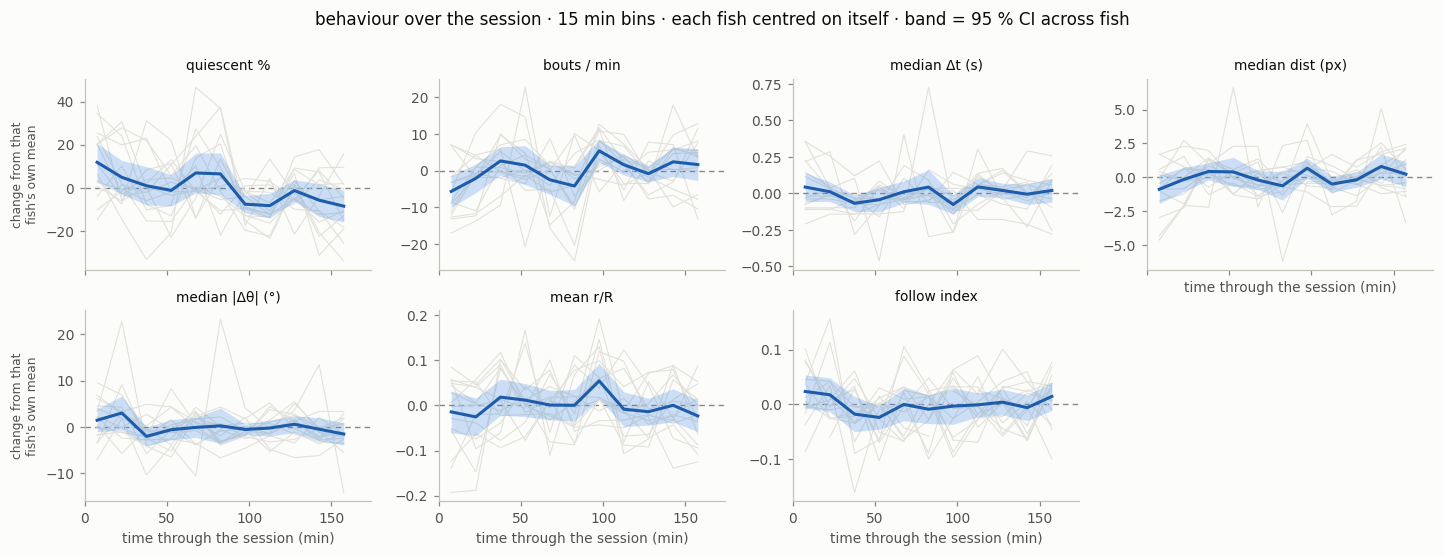

In [925]:
plot_time_trends(df, bin_min=15)
plt.show()

In [926]:
trend_table(df, bin_min=15)

,mean_rho,same_sign,first_bin,last_bin,sign_test_p
metric,,,,,
quiescent %,-0.275,10/15,41.72,21.49,0.3018
bouts / min,0.226,11/15,21.53,28.86,0.1185
median Δt (s),0.213,11/15,1.29,1.27,0.1185
median dist (px),0.047,8/15,14.32,15.44,1.0000
median |Δθ| (°),-0.108,8/15,39.84,36.86,1.0000
mean r/R,-0.088,8/15,0.43,0.42,1.0000
follow index,0.018,8/15,0.15,0.14,1.0000


The Spearman above tests for a **monotone drift**, which is the wrong instrument if the
change is confined to the opening — and the figure suggests exactly that: quiescence
elevated and bout rate depressed for roughly the first half hour, flat afterwards. So
contrast the first 30 min against the rest, paired within each fish.

In [927]:
settling_table(df, early_min=30, bin_min=15)

,early,rest,diff,same_sign,wilcoxon_p
metric,,,,,
quiescent %,38.26,27.93,10.33,10/15,0.0554
bouts / min,23.33,28.07,-4.74,10/15,0.0730
median Δt (s),1.27,1.24,0.03,9/15,0.7615
median dist (px),14.69,15.32,-0.63,9/15,0.3028
median |Δθ| (°),40.62,37.87,2.75,8/15,0.1070
mean r/R,0.43,0.45,-0.02,8/15,0.4543
follow index,0.14,0.12,0.02,10/15,0.1354


#### "No trend" is not "no change"

Both tests above ask whether change has a **direction**. Neither asks whether there is
change at all — and there is a great deal of it. Comparing how much one fish wanders across
its own 15 min bins against how much the fish differ from each other:

A ratio near 1 means a single fish varies over three hours **as much as the fish differ from
one another**. For bout rate and the follow index that is what happens. Two consequences
worth carrying forward:

* individuality estimated from a short window is largely temporal noise, so a per-fish
  parameter fitted on one stretch will not transfer to another;
* the thing to model is **slow non-directional fluctuation** — which is what the
  across-window autocorrelation metric was pointing at all along — not a session trend.

The settling effect is likewise not uniform: fish 4, 8, 10 and 13 drop 28–36 points of
quiescence between the first half hour and the rest, while fish 2, 6, 14, 0 and 1 move the
other way. Mean +10.3, **median only +4.5** — the aggregate is carried by a minority.

In [928]:
time_variation_table(df, bin_min=15)

,within_fish_sd,between_fish_sd,ratio
metric,,,
follow index,0.050,0.044,1.13
bouts / min,7.533,7.140,1.05
mean r/R,0.069,0.078,0.88
quiescent %,14.180,20.040,0.71
median dist (px),1.435,2.394,0.60
median Δt (s),0.130,0.228,0.57
median |Δθ| (°),4.086,7.151,0.57
